# 📊 EDA THÔ THEO NGUỒN (RAW-FIRST, SINGLE-SOURCE) — CAREERVIET
## Phân tích đơn biến chuyên sâu trên dữ liệu thô nguyên bản `data/careerviet/`

> **Dự án:** VN-IT-Job-Mining — **Thành viên phụ trách:** Nhóm EDA Intelligence (Thành viên 1, theo `01_huong_dan_eda_nhom_3_nguoi.md`)
> **Phạm vi file này:** EDA **cho riêng nguồn CareerViet ở tầng Raw As-Is**. Chưa ghép schema chung, chưa làm sạch, chưa biến đổi dữ liệu thô — mọi dẫn xuất phân tích chỉ tồn tại trong bộ nhớ notebook (`feat`), không ghi ngược về `data/`.
> **Tiêu chuẩn:** CRISP-DM Phase 2 (Data Understanding) + 5 trụ cột chất lượng dữ liệu + bộ 7 biểu đồ bắt buộc (DPI 300) tại `reports/figures/careerviet/`.

### Câu hỏi định hướng của notebook này
| Trụ cột | Câu hỏi chẩn đoán | Bước trả lời |
|:---|:---|:---|
| **1. Độ hoàn thiện** | Trường nào khuyết thiếu? Null ẩn dưới dạng text/marketing nào? | Bước 2 |
| **2. Hợp lệ & kiểu dữ liệu** | Chuỗi lương phức hợp, ngày `dd/mm/yyyy`, mảng `list[str]`, nhãn lồng nhau, chuỗi đóng gói nhiều trường | Bước 3 |
| **3. Duy nhất** | Trùng URL/Job ID/tiêu đề+công ty, trùng nội dung theo `canonical_hash` (repost) | Bước 4 |
| **4. Phân phối & ngoại lai** | Skewness/Kurtosis lương, kinh nghiệm, độ dài JD; ngoại lai IQR & Z | Bước 5 |
| **5. Lệch & mất cân bằng** | Cấp bậc, tỉnh thành, hình thức làm việc, độ thưa thớt kỹ năng, concentration công ty | Bước 6–8 |

### Cách chạy
`Kernel → Restart & Run All` (kernel `python3`, thư mục dự án). Notebook **hoàn toàn offline**: chỉ đọc `data/careerviet/**/*.json` và ghi ảnh vào `reports/figures/careerviet/`.

### Phạm vi: EDA NÀY KHÔNG LÀM TIỀN XỬ LÝ

Hướng dẫn `01_huong_dan_eda_nhom_3_nguoi.md` xếp **Pre-processing Pipeline** (Integration, Imputation, Normalization,
Scaling) vào giai đoạn **sau khi đã ghép đủ 8 nguồn**. Notebook này vì vậy chỉ làm đúng ba việc: **đọc raw → đo → đề xuất
luật tiền xử lý**. Cụ thể:

- **Không có thao tác ghi nào đụng tới `data/`** — notebook chỉ ghi ảnh PNG vào `reports/figures/careerviet/`.
- Không điền khuyết thiếu, không chuẩn hoá, không mã hoá nhãn, **không nhân tỷ giá**, không cắt text để tạo feature.
- Toàn bộ dẫn xuất (`feat`, `SAL_BY_CUR`, `LAD`, `SEN`, `CORR`, `REL`) chỉ là **frame đo lường trong bộ nhớ**, không cộng
  vào `df` và không xuất ra file.
- Các phép biến đổi ở thang kiểm đồ thị 02 là **đồ diagnostics**: chúng được đo *để chọn thuốc*, không hề được áp lên dữ liệu.
- Cell cuối **chứng minh bằng số** điều trên: in chữ ký tầng raw (số file, tổng byte, hash) và chữ ký nội dung `df` ở
  *lúc nạp* so với *sau khi chạy hết*; cả sáu phép kiểm đều phải PASS.

In [1]:
import os, sys, json, re, math, textwrap, warnings, hashlib
from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "run.py").is_file():
    if (PROJECT_ROOT.parent / "run.py").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError("Không tìm thấy run.py — hãy mở notebook từ thư mục dự án VN-IT-Job-Mining.")
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SOURCE, SOURCE_LABEL = "careerviet", "CareerViet"
DATA_DIR = PROJECT_ROOT / "data" / SOURCE
FIG_DIR = PROJECT_ROOT / "reports" / "figures" / SOURCE
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Lương được GIỮ NGUYÊN đơn vị mà tin đăng khai báo. VND và USD là HAI BẢNG riêng:
# notebook này không nhân tỷ giá để gộp thành một cột số (quy đổi là quyết định của tầng Integration).
VND_UNIT, USD_UNIT = "Triệu VND/tháng", "USD/tháng"
CUR_GROUPS = (("vnd", "VND", VND_UNIT), ("usd", "USD", USD_UNIT))   # (tag, nhãn tiền tệ trong raw, đơn vị hiển thị)
SAL_SANITY = {"vnd": (0.5, 1_000.0),      # 0,5–1.000 triệu/tháng: miền hợp lý của tin IT Việt Nam
              "usd": (50.0, 20_000.0)}    # 50–20.000 USD/tháng: bắt cả lỗi 'giá theo giờ bị đọc thành theo tháng'
MIN_N_DIST = 30                           # dưới ngưỡng này chỉ mô tả, không ước lượng skew/Box–Cox
PALETTE = ["#1d3557", "#2a9d8f", "#e76f51", "#e9c46a", "#457b9d"]
C_MAIN, C_OK, C_WARN, C_MUTE = "#1d3557", "#2a9d8f", "#e76f51", "#64748b"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#cbd5e1", "axes.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e2e8f0", "grid.linestyle": "--", "grid.linewidth": 0.7,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5, "ytick.labelsize": 9.5, "legend.fontsize": 9, "legend.frameon": False,
    "font.family": "DejaVu Sans", "axes.unicode_minus": False,
})

FIG_NOTE = ""  # dòng ghi chú nguồn dưới mỗi biểu đồ, gán sau khi nạp dữ liệu
SAVED_FIGS = []  # danh sách PNG do CHÍNH notebook này ghi ra (để phân biệt với tệp cũ còn sót lại)
FIG_LABELS = {}  # png -> tập nhãn thu từ HÌNH THẬT LÚC VẼ, dùng cho bước kiểm bao phủ trường ở Bước 7
TEXT_CHECKS = []  # (png -> số lỗi bố cục chữ) do máy đo trên chính hình trước khi lưu, không do người xem cảm tính


def show(obj, limit=30):
    """In bảng thân thiện cả trong Jupyter lẫn khi chạy như script."""
    if isinstance(obj, pd.DataFrame) and len(obj) > limit:
        obj = obj.head(limit)
    with pd.option_context("display.max_columns", None, "display.width", 260, "display.max_colwidth", 55):
        display(obj)


def _fit_fig_text(fig, txt, left_frac=0.012, floor=7.0, steps=8, readability=11.0):
    """Ép một chữ cấp figure nằm gọn trong canvas: trước hết BẺ DÒNG, hết bẻ rồi mới hạ cỡ chữ.

    Ba lý do phải đo lại bằng renderer sau mỗi lần sửa thay vì tính tay một phát:
      (1) bề rộng chữ KHÔNG tỉ lệ thuận tuyệt đối với cỡ chữ — matplotlib làm tròn bề rộng từng
          glyph ra số nguyên pixel, chuỗi càng dài càng dôi, nên chỉ co theo tỉ lệ thì vẫn tràn
          biên vài pixel (đúng cái lỗi mà tự kiểm bố cục đo được bằng hộp bao);
      (2) chuỗi đã có sẵn dấu xuống dòng thì bề rộng chỉ bằng dòng dài nhất, co cả cụm là lãng phí;
      (3) thà để tiêu đề hai dòng còn hơn hạ xuống 7pt cho "vừa" mà mắt người không đọc nổi.
    """
    try:
        renderer = fig.canvas.get_renderer()
        width_px = fig.get_size_inches()[0] * fig.dpi
        limit_px = width_px * (1 - left_frac) - 6.0             # biên phải còn chừa một mép an toàn
        base = txt.get_fontsize()
        bb = txt.get_window_extent(renderer)
        if bb.x1 > limit_px:                                    # bước 1: thử co chữ theo tỉ lệ đo được
            txt.set_fontsize(max(floor, base * (limit_px - bb.x0) / max(bb.width, 1.0)))
        if "\n" not in txt.get_text() and txt.get_fontsize() < min(readability, base * 0.9):
            # buộc co quá ngưỡng đọc được -> trả cỡ gốc rồi bẻ thành nhiều dòng ngắn
            per_line = max(24, int(len(txt.get_text()) * (limit_px - bb.x0) / max(bb.width, 1.0) * 0.94))
            txt.set_fontsize(base)
            txt.set_text(textwrap.fill(txt.get_text(), width=per_line, break_long_words=False))
        for _ in range(steps):                                  # bước 2: đo hộp bao thật, chỉnh dần
            bb = txt.get_window_extent(renderer)
            if bb.x1 <= limit_px or txt.get_fontsize() <= floor:
                return
            txt.set_fontsize(max(floor, txt.get_fontsize() * 0.94))
    except Exception:
        pass                                                    # backend không có renderer -> giữ nguyên cỡ gốc


def _harvest_labels(fig):
    """Thu MỌI chữ in trên một hình: nhãn trục, tên trục, chú thích legend, ghi chú và tiêu đề.

    Nguồn bằng chứng là đối tượng Text của chính figure sắp lưu ra PNG, không phải một danh sách
    gõ tay, nên cell kiểm bao phủ ở Bước 7 không thể báo 'có biểu đồ' cho một trường chưa thực sự lên hình.
    """
    labs = set()

    def _add(s):
        s = str(s).strip()
        if s:
            labs.add(s)

    for ax in fig.axes:
        for t in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
            _add(t.get_text())
        _add(ax.xaxis.get_label().get_text())
        _add(ax.yaxis.get_label().get_text())
        _add(ax.get_title())
        lg = ax.get_legend()
        if lg is not None:
            for t in lg.get_texts():
                _add(t.get_text())
        for ch in ax.get_children():
            if type(ch).__name__ in ("Annotation", "Text"):
                _add(ch.get_text())
    st = fig.get_suptitle()          # get_suptitle() trả về CHUỖI (khác fig.suptitle() trả về Text)
    _add(st.get_text() if hasattr(st, "get_text") else st)
    for t in fig.texts:
        _add(t.get_text())
    return labs


def _v_frac(fig, txt):
    """Do đáy và đỉnh của một chữ đang nằm trên figure, quy về tỷ lệ trục figure (0–1)."""
    bb = txt.get_window_extent(fig.canvas.get_renderer()).transformed(fig.transFigure.inverted())
    return bb.y0, bb.y1


def _in_view(tk, interval):
    """Tick này có nằm trong miền hiển thị không — nhãn ngoài view không được in lên PNG.

    matplotlib vẫn giữ nguyên get_visible()=True cho nhãn của tick ngoài xlim/ylim, nhưng hộp bao của
    nó bị ngoại suy ra rất xa (hàng chục nghìn pixel). Lọc theo vị trí dữ liệu của tick là phép thử
    đúng nhất, không phải đoán bằng khoảng cách tới biên hình.
    """
    try:
        return interval[0] <= float(tk.get_loc()) <= interval[1]
    except (TypeError, ValueError):
        return True                                     # loc không phải số (trục loại): cứ đo bình thường


def _fit_inside_fig(fig, txt, margin_px=2.0, steps=8):
    """Hạ cỡ chữ cho tới khi hộp bao của nó nằm gọn trong canvas — dùng cho tít của một panel.

    `tight_layout` không hề co tít: một `set_title` dài hơn bề ngang panel sẽ tràn sang panel kề và
    bị cắt nét ở biên PNG. Cách duy nhất giữ đủ chữ mà không đổi layout là thu nhỏ cỡ chữ dần.
    """
    try:
        fw = fig.get_size_inches()[0] * fig.dpi
        renderer = fig.canvas.get_renderer()
        for _ in range(steps):
            bb = txt.get_window_extent(renderer)
            if bb.x0 >= margin_px and bb.x1 <= fw - margin_px:
                return
            txt.set_fontsize(max(7.0, txt.get_fontsize() * 0.9))
    except Exception:
        pass                                                # backend không có renderer -> giữ nguyên cỡ gốc


def _visible_texts(fig):
    """Lấy MỌI chữ thực sự nhìn thấy được trên hình, kèm hộp bao pixel do renderer đo.

    Hộp bao lấy từ số đo thật của renderer chứ không ước lượng theo cỡ chữ, nên việc 'hai chữ đè
    nhau hay chưa' trở thành một phép đo. Chữ rỗng, chữ bị ẩn và chữ của tick đã gỡ khỏi axes bị bỏ.
    """
    items = []
    try:
        renderer = fig.canvas.get_renderer()
    except Exception:
        return items

    def _push(t, kind, owner, ax=None):
        if t is None or isinstance(t, str) or not t.get_visible():
            return
        s = str(t.get_text()).strip()
        if not s:
            return
        try:
            bb = t.get_window_extent(renderer)
            rot = float(t.get_rotation())
        except Exception:
            return
        if bb.width <= 0 or bb.height <= 0:
            return
        try:
            axbb = None if ax is None else ax.get_window_extent(renderer)
        except Exception:
            axbb = None
        items.append({"txt": s, "bb": bb, "kind": kind, "owner": owner, "rot": rot, "axbb": axbb})

    for i, ax in enumerate(fig.axes):
        if not ax.get_visible():                        # axes ẩn (vd. lớp nền do twinx tạo ra) -> miễn đếm cả hình
            continue
        xlim, ylim = sorted(ax.get_xlim()), sorted(ax.get_ylim())
        if ax.xaxis.get_visible():                      # twinx làm ẩn trục X của axes phụ: nhãn thuộc trục nào thì xét theo trục đó
            for tk in ax.xaxis.get_major_ticks():
                if _in_view(tk, xlim):
                    _push(tk.label1, "xtick", f"axes{i}", ax)
                    _push(tk.label2, "xtick", f"axes{i}", ax)
            _push(ax.xaxis.get_label(), "xlabel", f"axes{i}", ax)
        if ax.yaxis.get_visible():
            for tk in ax.yaxis.get_major_ticks():
                if _in_view(tk, ylim):
                    _push(tk.label1, "ytick", f"axes{i}", ax)
                    _push(tk.label2, "ytick", f"axes{i}", ax)
            _push(ax.yaxis.get_label(), "ylabel", f"axes{i}", ax)
        _push(ax.title, "title", f"axes{i}", ax)        # ax.get_title() trả về CHUỖI -> phải dùng artist
        for t in ax.texts:
            _push(t, "ghi chú", f"axes{i}", ax)
        lg = ax.get_legend()
        if lg is not None:
            for t in lg.get_texts():
                _push(t, "legend", f"axes{i}", ax)
    for t in fig.texts:
        _push(t, "figure", "figure")
    return items


def _check_typography(fig, save_name=None, min_frac=0.28, min_px=45.0, bleed_px=1.5):
    """Đo bằng máy xem chữ trên hình có đè nhau hoặc bị cắt ở biên không; in ra từng vấn đề tìm thấy.

    Hai nhãn tick của CÙNG một trục mà có xoay nghiêng được miễn xét, vì hộp bao của chữ xoay là hình
    chữ nhật trùm lên nét vẽ: hai nhãn kề nhau luôn 'chạm' nhau trên hộp bao dù mực không hề đè.
    Ngưỡng 28% diện tích chữ nhỏ hạn các trường hợp hai chữ chỉ sát nhau chứ chưa thực sự chồng.

    Hình phải được `draw()` một lần trước khi đo: vị trí cuối của nhãn tick và của tít chỉ được gán lúc
    vẽ; đo trước khi vẽ sẽ lấy phải hộp bao của layout cũ và báo sai hàng loạt chữ 'bị cắt ở biên'.
    """
    try:
        fig.canvas.draw()                               # chốt vị trí thật của mọi chữ trên hình
    except Exception:
        pass
    items = _visible_texts(fig)
    fw, fh = fig.get_size_inches()[0] * fig.dpi, fig.get_size_inches()[1] * fig.dpi
    problems = []
    for it in items:
        bb = it["bb"]
        over = max(-bb.x0, -bb.y0, bb.x1 - fw, bb.y1 - fh)  # số pixel tràn ra ngoài canvas (âm = còn hở)
        if over > bleed_px:
            problems.append(f"chữ bị cắt ở biên [{it['owner']}] «{it['txt'][:44]}» "
                            f"(tràn {over:.0f}px — trái {-bb.x0:.0f} · đáy {-bb.y0:.0f} · "
                            f"phải {bb.x1 - fw:.0f} · trên {bb.y1 - fh:.0f})")
    for a in range(len(items)):
        for b in range(a + 1, len(items)):
            ia, ib = items[a], items[b]
            tick_pair = (ia["owner"] == ib["owner"]
                         and ia["kind"] in ("xtick", "ytick") and ib["kind"] in ("xtick", "ytick"))
            if tick_pair and (abs(ia["rot"]) or abs(ib["rot"])):
                continue
            ba, bb2 = ia["bb"], ib["bb"]
            if ia["txt"] == ib["txt"] and abs(ba.x0 - bb2.x0) < 1 and abs(ba.y0 - bb2.y0) < 1:
                continue                                # cùng một chữ in trùng đúng chỗ: không phải hai chữ đè nhau
            iw = min(ba.x1, bb2.x1) - max(ba.x0, bb2.x0)
            ih = min(ba.y1, bb2.y1) - max(ba.y0, bb2.y0)
            if iw <= 0 or ih <= 0:
                continue
            inter = iw * ih
            smaller = min(ba.width * ba.height, bb2.width * bb2.height)
            if inter / smaller >= min_frac and inter >= min_px:
                problems.append(f"hai chữ đè nhau {inter / smaller:.0%} chữ nhỏ: "
                                f"[{ia['owner']}] «{ia['txt'][:30]}» và [{ib['owner']}] «{ib['txt'][:30]}»")
    if save_name:
        TEXT_CHECKS.append((save_name, len(problems)))
    if problems:
        print(f"   ⚠️  ĐÈ CHỮ — {save_name or 'hình không lưu'}: {len(problems)} vấn đề bố cục")
        for p in problems[:6]:
            print(f"        • {p}")
    return problems


def finalize(fig, title, subtitle=None, save_name=None, note=None):
    """Áp chuẩn trình bày: tiêu đề kết luận + phụ đề n= + nguồn; lưu PNG DPI 300.

    Khoảng cách hai dòng đầu bài được quy ra ĐIỂM THẬT rồi mới đổi sang tỷ lệ trục figure, và
    được tinh chỉnh bằng hộp bao đo được của chính dòng chữ. Cách cũ ấn định hở 0.04 trục (chỉ
    ~15 điểm trên hình cao 5 inch) nên dấu tiếng Việt của phụ đề đè thẳng lên tiêu đề. Cả hai
    dòng đặt va="top" để không bị cắt đỉnh khi lưu PNG.
    """
    h_pt = fig.get_size_inches()[1] * fig.dpi
    ttl_y = 0.995
    sub_y = ttl_y - 21.0 / h_pt                             # 21đ = chữ 14.5pt + khoảng thở
    top_y = sub_y - 15.0 / h_pt if subtitle else ttl_y - 21.0 / h_pt
    ttl = fig.text(0.012, ttl_y, title, ha="left", va="top", fontsize=14.5,
                   fontweight="bold", color=C_MAIN)
    _fit_fig_text(fig, ttl)
    sub = None
    if subtitle:
        sub = fig.text(0.012, sub_y, subtitle, ha="left", va="top", fontsize=10, color=C_MUTE)
        _fit_fig_text(fig, sub)
    nte = fig.text(0.012, 0.015, note or FIG_NOTE, ha="left", fontsize=8.5, color=C_MUTE)
    _fit_fig_text(fig, nte)
    try:                                                    # đo thật -> không còn đè nhau
        top_y = _v_frac(fig, ttl)[0] - 4.0 / h_pt
        if sub is not None:
            sub.set_position((0.012, top_y))
            _fit_fig_text(fig, sub)
            top_y = _v_frac(fig, sub)[0] - 4.0 / h_pt
    except Exception:
        pass                                                # backend không có renderer: dùng ước lượng
    fig.tight_layout(rect=[0, 0.045, 1, top_y])
    for _ax, _t in HOLE_TEXTS:                              # axes vừa bị tight_layout co/giãn: đo lại lỗ donut
        if _ax in fig.axes:
            _fit_in_hole(_ax, _t)
    for _ax in fig.axes:                                  # tít dài hơn panel: hạ cỡ chữ thay vì cắt nét
        if _ax.title.get_text().strip():
            _fit_inside_fig(fig, _ax.title)
    try:                                                    # đo bố cục BẰNG MÁY, ngay khi hình đã xếp xong
        _check_typography(fig, save_name)
    except Exception:
        pass
    if save_name:
        FIG_LABELS[save_name] = _harvest_labels(fig)
        path = FIG_DIR / save_name
        fig.savefig(path, dpi=300)
        SAVED_FIGS.append(save_name)
        print(f"🖼️  Đã lưu {path.relative_to(PROJECT_ROOT)} (DPI 300)")
    plt.show()
    plt.close(fig)


DONUT_W = 0.34                                              # bề dày vành: lỗ donut có đường kính 0.66
HOLE_TEXTS = []                                             # (axes, chú thích lỗ donut) chờ đo lại sau tight_layout


def _fit_in_hole(ax, txt, pad=0.95, floor=6.0, steps=10):
    """Hạ cỡ chữ cho tới khi cả hộp chú thích nằm gọn trong LỖ TRÒN của bánh donut.

    Bán kính lỗ đo từ phép biến đổi data->pixel của chính axes (lát có bán kính 1 đơn vị dữ liệu,
    vành dày DONUT_W nên lỗ = 1 - DONUT_W), không đoán số điểm. Điều kiện lọt đường tròn là
    sqrt((w/2)^2 + (h/2)^2) <= R: nếu chỉ so bề ngang thì bốn góc hộp vẫn lòi ra vành màu, chữ xám
    đè trên nền tối và không đọc được nữa.
    """
    try:
        renderer = ax.get_figure().canvas.get_renderer()
        c0 = ax.transData.transform((0.0, 0.0))
        c1 = ax.transData.transform((1.0 - DONUT_W, 0.0))
        r_px = abs(c1[0] - c0[0]) * pad
        for _ in range(steps):
            bb = txt.get_window_extent(renderer)
            if math.hypot(bb.width / 2, bb.height / 2) <= r_px or txt.get_fontsize() <= floor:
                return
            txt.set_fontsize(max(floor, txt.get_fontsize() * 0.9))
    except Exception:
        pass                                                    # backend không có renderer -> giữ nguyên cỡ gốc


def donut(ax, values, names, colors, min_pct=8.0, unit="tin"):
    """Vẽ bánh donut mà nhãn lát cắt nhỏ không đè nhau: lát dưới ngưỡng được liệt kê giữa lỗ tròn.

    Nhãn quanh bánh cho mấy lát 1–3% luôn chồng lên nhau (tự kiểm bố cục đo bằng máy phát hiện): tên
    nhóm dài cộng hai con số %. Ở đây lát đủ lớn giữ nhãn trên vành, các lát còn lại được liệt kê kèm
    tỷ lệ và số lượng CHÍNH GIỮA LỖ donut — vùng trống sẵn có — nên không nhãn nào đè nhau mà cũng
    không lát nào mất tên. Khối chú thích được _fit_in_hole đo và bo cỡ chữ để không tràn ra vành.
    Tỷ lệ in ra lấy theo tổng các lát được vẽ, đúng bằng tỷ lệ diện tích đòn.
    """
    values = list(values)
    colors = list(colors)
    while len(colors) < len(values):                        # màu ít hơn lát: dùng lại màu cuối, không vỡ lúc vẽ
        colors.append(colors[-1])
    total = float(sum(values))
    share = [v / total * 100 if total else 0.0 for v in values]
    labs = [f"{n}\n{p:.1f}% · {int(round(v))} {unit}" if p >= min_pct else ""
            for n, p, v in zip(names, share, values)]
    ax.pie(values, labels=labs, colors=colors, startangle=140, labeldistance=1.06,
           wedgeprops=dict(width=DONUT_W, edgecolor="white"), textprops={"fontsize": 8.5})
    small = [f"{n} · {p:.1f}% ({int(round(v))})"
             for n, p, v in zip(names, share, values) if p < min_pct]
    if small:
        hole = ax.text(0, 0, "\n".join([f"lát nhỏ dưới {min_pct:.0f}% ({unit}):"] + small),
                       ha="center", va="center", fontsize=7.5, color="#334155", linespacing=1.45)
        HOLE_TEXTS.append((ax, hole))                       # tight_layout sẽ đổi cỡ axes -> finalize đo lại
        _fit_in_hole(ax, hole)


def label_bars(ax, values, fmt="{:,.0f}", pad_ratio=0.012, fontsize=9):
    """Gắn nhãn giá trị (%) lên đòn ngang đã vẽ sẵn."""
    span = max(values) if len(values) else 1
    for i, v in enumerate(values):
        ax.text(v + span * pad_ratio, i, fmt.format(v), va="center", ha="left",
                fontsize=fontsize, color="#334155")


def entropy_norm(counts):
    """Độ đa dạng chuẩn hoá 0–1 (1 = phân bố đều, 0 = dồn 1 nhãn)."""
    p = np.asarray([c for c in counts if c > 0], dtype=float)
    if p.size <= 1:
        return 0.0
    return float(stats.entropy(p / p.sum()) / np.log(p.size))


def rho_word(rho):
    """Phân loại độ mạnh tương quan hạng theo ngưỡng Cohen (|rho| < .2 / < .4 / < .6 / còn lại)."""
    a = abs(rho)
    return "rất yếu" if a < .2 else ("yếu" if a < .4 else ("vừa" if a < .6 else "mạnh"))


print(f"✅ Môi trường sẵn sàng — nguồn: {SOURCE_LABEL} | dữ liệu: {DATA_DIR.relative_to(PROJECT_ROOT)}")

✅ Môi trường sẵn sàng — nguồn: CareerViet | dữ liệu: data\careerviet


## Bước 1 — Nạp Raw Envelope & khảo sát cấu trúc nguyên bản (Zero Information Loss)

Mỗi tin tuyển dụng CareerViet được lưu dưới dạng **raw envelope** 2 tầng:

```
{ job_id, source, ... }  →  data/careerviet/dt=YYYY-MM-DD/<JOBID>_v<N>.json
├── metadata      : job_id, source_url, scraped_at, scraper_version, version,
│                   content_hash, canonical_hash, field_hashes{7 trường}, source_category
└── raw_payload   : title, job-company-name, detail-box[list], detail-row{dict},
                    job-tags[list], map, "Ngành nghề"[list]
```

Khảo sát **cả hai tầng** (khác notebook cũ chỉ nạp `raw_payload`), vì tầng metadata cho phép đo CDC/repost và độ tươi dữ liệu.

In [2]:
def load_envelopes(source: str, data_dir: Path):
    """Nạp toàn bộ raw envelope, giữ nguyên 100% trường thô (không ép kiểu, không chuẩn hoá)."""
    files = [p for p in sorted(data_dir.rglob("*.json"))
             if not any(k in str(p) for k in ("url_ledger", "manifest", "session"))]
    payloads, metas, provenance = [], [], []
    bad_files = []
    for fp in files:
        try:
            with open(fp, "r", encoding="utf-8") as f:
                env = json.load(f)
        except Exception as exc:                                  # kiểm tra cả file hỏng/thiếu JSON
            bad_files.append((fp.name, repr(exc)))
            continue
        meta = env.get("metadata") or {}
        part = next((p for p in fp.relative_to(data_dir).parts[:-1]), "dt=unknown")
        payloads.append(env.get("raw_payload") or {})
        metas.append(meta)
        provenance.append({
            "_file": fp.name, "_partition": part,
            "_bytes": fp.stat().st_size,
            "_has_payload": bool(env.get("raw_payload")),
            "_has_metadata": bool(env.get("metadata")),
            "_top_keys": "|".join(sorted(env.keys())),
        })
    prov = pd.DataFrame(provenance)
    df = pd.json_normalize(payloads)
    df = df.join(prov)
    meta_df = pd.json_normalize(metas).add_prefix("m_")
    meta_df.index = df.index
    return df, meta_df, files, bad_files


df, df_meta, FILES, BAD_FILES = load_envelopes(SOURCE, DATA_DIR)


def _raw_fingerprint(dir_: Path):
    """Chữ ký tầng Raw As-Is trên đĩa: (số file, tổng byte, hash tên + kích thước + mtime)."
    """
    ps = sorted(p for p in dir_.rglob("*") if p.is_file())
    body = "\x1f".join(f"{p.relative_to(dir_)}:{p.stat().st_size}:{p.stat().st_mtime_ns}" for p in ps)
    return {"n": len(ps), "bytes": sum(p.stat().st_size for p in ps),
            "sha": hashlib.sha256(body.encode("utf-8")).hexdigest()[:16]}


def _frame_fingerprint(frame):
    """Chữ ký nội dung một DataFrame trong bộ nhớ (dùng để chứng minh `df` không bị sửa)."""
    rows = frame.astype(object).where(frame.notna(), "\u2205").astype(str)
    body = "\n".join(rows.agg(lambda r: "\x1f".join(r), axis=1).tolist())
    return hashlib.sha256(body.encode("utf-8")).hexdigest()[:16]


RAW_DISK_0 = _raw_fingerprint(DATA_DIR)
RAW_SHAPE_0, RAW_COLUMNS_0 = df.shape, list(df.columns)
RAW_FRAME_0 = _frame_fingerprint(df)
print("─" * 78)
print("🔒 HIỆN TRẠNG RAW LÚC NẠP (móc chống tiền xử lý nhầm trong EDA — xem bước 7)")
print(f"   Trên đĩa   : {RAW_DISK_0['n']} file · {RAW_DISK_0['bytes']:,} byte · sha256[:16]={RAW_DISK_0['sha']}")
print(f"   Trong `df` : {RAW_SHAPE_0[0]} dòng × {RAW_SHAPE_0[1]} cột · sha256[:16]={RAW_FRAME_0}")
print("─" * 78)

print("=" * 78)
print(f"📦 RAW ENVELOPE — {SOURCE_LABEL}")
print(f"   Số file JSON nạp vào bộ nhớ : {len(FILES)} (lỗi parse: {len(BAD_FILES)})")
print(f"   Số bản ghi (dòng)           : {len(df)}")
print(f"   Số cột thô (raw payload)    : {df.shape[1] - 5}  (+5 cột provenance nội bộ)")
print(f"   Số cột metadata CDC         : {df_meta.shape[1]}")
print(f"   Phân vùng dt               : {df['_partition'].value_counts().to_dict()}")
if BAD_FILES:
    print("   ⚠️ File lỗi:", BAD_FILES[:5])

FIG_NOTE = (f"Nguồn: {len(df)} raw envelope {SOURCE_LABEL} "
            f"({', '.join(df['_partition'].value_counts().index.tolist())}) — "
            f"scraped_at {pd.to_datetime(df_meta['m_scraped_at'], errors='coerce').min():%d/%m/%Y} "
            f"→ {pd.to_datetime(df_meta['m_scraped_at'], errors='coerce').max():%d/%m/%Y} · phân tích Raw As-Is, không biến đổi dữ liệu thô")

show(df.drop(columns=["_bytes", "_has_payload", "_has_metadata", "_top_keys"]).head(5))

──────────────────────────────────────────────────────────────────────────────
🔒 HIỆN TRẠNG RAW LÚC NẠP (móc chống tiền xử lý nhầm trong EDA — xem bước 7)
   Trên đĩa   : 599 file · 3,551,098 byte · sha256[:16]=d22e33dd22cce24b
   Trong `df` : 599 dòng × 20 cột · sha256[:16]=b0bceff41f31f31f
──────────────────────────────────────────────────────────────────────────────
📦 RAW ENVELOPE — CareerViet
   Số file JSON nạp vào bộ nhớ : 599 (lỗi parse: 0)
   Số bản ghi (dòng)           : 599
   Số cột thô (raw payload)    : 15  (+5 cột provenance nội bộ)
   Số cột metadata CDC         : 16
   Phân vùng dt               : {'2026-10-20': 599}


,title,job-company-name,detail-box,job-tags,map,Ngành nghề,detail-row.Phúc lợi,detail-row.Mô tả Công việc,detail-row.Yêu Cầu Công Việc,detail-row.Địa điểm làm việc,detail-row.Thông tin khác,detail-row.Gợi ý hồ sơ,detail-row.JOB TAGS / SKILLS:,detail-row.Video Tuyển Dụng,_file,_partition
0,Kỹ Sư Điện Lập Trình PLC HMI,Công Ty Cổ Phần Trực Quan,"[Ngày cập nhật 09/10/2026, Ngành nghề Cơ khí / Ô tô...","[kỹ sư giám sát điện, electrical engineer, kỹ sư cơ...",Long An,"[Cơ khí / Ô tô / Tự động hóa , Điện / Điện tử / Điệ...",Phúc lợi Laptop Chế độ bảo hiểm Du Lịch Phụ cấp Đồn...,"Mô tả Công việc Công ty Cổ phần Trực Quan, được thà...","Yêu Cầu Công Việc - Tốt nghiệp Cao Đẳng, Đại Học ng...","Địa điểm làm việc Long An Khu công nghiệp Xuyên Á, ...",Thông tin khác Bằng cấp : Đại học Độ tuổi : 22 - 40...,Gợi ý hồ sơ Thiết kế CV Ứng Tuyển,NaN,NaN,35C32FB4_v1.json,2026-10-20
1,Technical Specialist,Công Ty TNHH Tư Vấn Kỹ Thuật Và Tin Học Thương Mại ...,"[Ngày cập nhật 08/10/2026, Ngành nghề Bán hàng / Ki...","[Technical Specialist, Nhân viên điện công trình, K...",Hồ Chí Minh,"[Bán hàng / Kinh doanh , CNTT - Phần mềm , Giải trí]",Phúc lợi Chế độ bảo hiểm Du Lịch Phụ cấp Chế độ thư...,Mô tả Công việc Phối hợp với Sales demo và giới thi...,Yêu Cầu Công Việc Có kiến thức hoặc kinh nghiệm sử ...,Địa điểm làm việc Hồ Chí Minh Tòa nhà Kingston Resi...,Thông tin khác Bằng cấp : Cao đẳng Độ tuổi : Không ...,Gợi ý hồ sơ Thiết kế CV Ứng Tuyển,NaN,NaN,35C3B2DA_v1.json,2026-10-20
2,VỊ TRÍ USER EXPERIENCE ASSURANCE (UXA) - USER ORIEN...,Công ty TNHH OTANI U.P.,"[Ngày cập nhật 19/10/2026, Ngành nghề CNTT - Phần m...",[vị trí user experience assurance uxa - user orient...,Hà Nội,[CNTT - Phần mềm],Phúc lợi Laptop Chế độ bảo hiểm Du Lịch Phụ cấp Chế...,Mô tả Công việc Đội ngũ UXA chịu trách nhiệm kiểm t...,Yêu Cầu Công Việc ● Kỹ năng giao tiếp thấu đáo và c...,"Địa điểm làm việc Hà Nội Tòa nhà Prime Center, 53 Q...",Thông tin khác Độ tuổi : Không giới hạn tuổi Lương ...,Gợi ý hồ sơ Thiết kế CV Ứng Tuyển,NaN,NaN,35C5BDE1_v1.json,2026-10-20
3,ATS Software Development Engineer,CÔNG TY TNHH CÔNG NGHIỆP MINDA VIỆT NAM - CHI NHÁNH...,"[Ngày cập nhật 14/10/2026, Ngành nghề CNTT - Phần m...",[],Hồ Chí Minh,[CNTT - Phần mềm],Phúc lợi Laptop Chế độ bảo hiểm Du Lịch Phụ cấp Đồn...,Mô tả Công việc Develop software for Automated Test...,Yêu Cầu Công Việc Required Qualifications: Bachelor...,Địa điểm làm việc Hồ Chí Minh Tòa nhà Sacom Chíp Sá...,Thông tin khác Bằng cấp : Đại học Phụ cấp khác : - ...,Gợi ý hồ sơ Thiết kế CV Ứng Tuyển,NaN,NaN,35C7AC66_v1.json,2026-10-20
4,NHÂN VIÊN KINH DOANH PHẦN MỀM CAD/CAM/CAE (Hà Nội),Công Ty TNHH Tư Vấn Kỹ Thuật Và Tin Học Thương Mại ...,"[Ngày cập nhật 08/10/2026, Ngành nghề CNTT - Phần m...","[Đại diện kinh doanh, Nhân viên phòng kinh doanh, N...",Hà Nội,"[CNTT - Phần mềm , Bán hàng / Kinh doanh , Tư vấn]",Phúc lợi Laptop Chế độ bảo hiểm Du Lịch Phụ cấp Du ...,"Mô tả Công việc Chủ động tìm kiếm, tiếp cận khách h...",Yêu Cầu Công Việc Tối thiểu 2 năm kinh nghiệm Sales...,"Địa điểm làm việc Hà Nội 119 đường Trần Duy Hưng,...",Thông tin khác Bằng cấp : Cao đẳng Độ tuổi : Trên 2...,Gợi ý hồ sơ Thiết kế CV Ứng Tuyển,NaN,NaN,35C7FCA1_v1.json,2026-10-20


In [3]:
print("── DANH SÁCH 100% CỘT THÔ (raw_payload) + KIỂU DỮ LIỆU THỰC TẾ ──")
raw_cols = [c for c in df.columns if not c.startswith("_")]
struct_rows = []
for c in raw_cols:
    kinds = Counter(type(v).__name__ for v in df[c])
    struct_rows.append({
        "Cột thô": c,
        "dtype (pandas)": str(df[c].dtype),
        "Kiểu Python thực tế": ", ".join(f"{k}×{v}" for k, v in kinds.most_common()),
        "Đầy đủ (%)": round(df[c].notna().mean() * 100, 1),
        "Độc nhất": df[c].map(lambda v: v if isinstance(v, (str, int, float)) and not pd.isna(v)
                             else json.dumps(v, ensure_ascii=False, default=str)[:40]).nunique(),
        "Ví dụ giá trị": str(df[c].dropna().iloc[0])[:60] if df[c].notna().any() else "",
    })
show(pd.DataFrame(struct_rows), limit=40)

── DANH SÁCH 100% CỘT THÔ (raw_payload) + KIỂU DỮ LIỆU THỰC TẾ ──


,Cột thô,dtype (pandas),Kiểu Python thực tế,Đầy đủ (%),Độc nhất,Ví dụ giá trị
0,title,str,str×599,100.0,552,Kỹ Sư Điện Lập Trình PLC HMI
1,job-company-name,str,str×599,100.0,265,Công Ty Cổ Phần Trực Quan
2,detail-box,object,list×599,100.0,32,"['Ngày cập nhật 09/10/2026', 'Ngành nghề Cơ khí / Ô..."
3,job-tags,object,list×599,100.0,439,"['kỹ sư giám sát điện', 'electrical engineer', 'kỹ ..."
4,map,str,"str×586, float×13",97.8,37,Long An
5,Ngành nghề,object,"list×586, NoneType×13",97.8,143,"['Cơ khí / Ô tô / Tự động hóa , Điện / Điện tử / Đi..."
6,detail-row.Phúc lợi,str,"str×598, float×1",99.8,158,Phúc lợi Laptop Chế độ bảo hiểm Du Lịch Phụ cấp Đồn...
7,detail-row.Mô tả Công việc,str,"str×598, float×1",99.8,578,"Mô tả Công việc Công ty Cổ phần Trực Quan, được thà..."
8,detail-row.Yêu Cầu Công Việc,str,"str×598, float×1",99.8,581,"Yêu Cầu Công Việc - Tốt nghiệp Cao Đẳng, Đại Học ng..."
9,detail-row.Địa điểm làm việc,str,"str×394, float×205",65.8,268,"Địa điểm làm việc Long An Khu công nghiệp Xuyên Á, ..."


### 1.2 Provenance & độ tươi dữ liệu (đơn biến trên tầng metadata)

`metadata` là tầng nhân tố (factor layer) của pipeline: phiên bản crawler, thời điểm thu thập,
và **hash đa cấp** (`content_hash` cho toàn bộ payload, `canonical_hash` cho JSON chuẩn hoá,
`field_hashes` cho từng trường nghiệp vụ). Ba chỉ báo cần kiểm tra ngay ở EDA nguồn:

1. `version` — số bản ghi có `version > 1` phản ánh CDC đã phát hiện tin đổi nội dung.
2. `scraper_version` — trộn nhiều phiên bản crawler trong một đợt thu thập sẽ làm lệch cấu trúc trường.
3. `scraped_at` — thời điểm thu thập quyết định cách diễn giải "ngày hết hạn" và "ngày cập nhật".

,Giá trị phổ biến nhất,Số giá trị độc nhất,Trống (%)
m_job_id,35C32FB4,599,0.00
m_source,careerviet,1,0.00
m_source_url,https://careerviet.vn/vi/tim-viec-lam/134651-senior...,599,0.00
m_scraped_at,2026-10-20T00:55:49.985151+00:00,599,0.00
m_scraper_version,1.0.0-raw-envelope,1,0.00
m_version,1,1,0.00
m_content_hash,004b625c10106456cdefd574afa58f1b3ff76895725cb70c776...,599,0.00
m_canonical_hash,004b625c10106456cdefd574afa58f1b3ff76895725cb70c776...,597,0.33
m_source_category,c1,1,99.50
m_field_hashes.title,e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca49...,550,0.33



🕒 scraped_at hợp lệ: 599/599 | chuỗi thu thập: 2026-10-20 00:55:49.985151+00:00 → 2026-10-20 11:33:19.143748+00:00
🔖 version > 1 (tin đã đổi nội dung theo CDC): 0 bản ghi
🛠️ scraper_version: {'1.0.0-raw-envelope': 599}
#️⃣ canonical_hash trống: 2 bản ghi (không truy vết được CDC)
🖼️  Đã lưu reports\figures\careerviet\08_raw_size_and_timing.png (DPI 300)


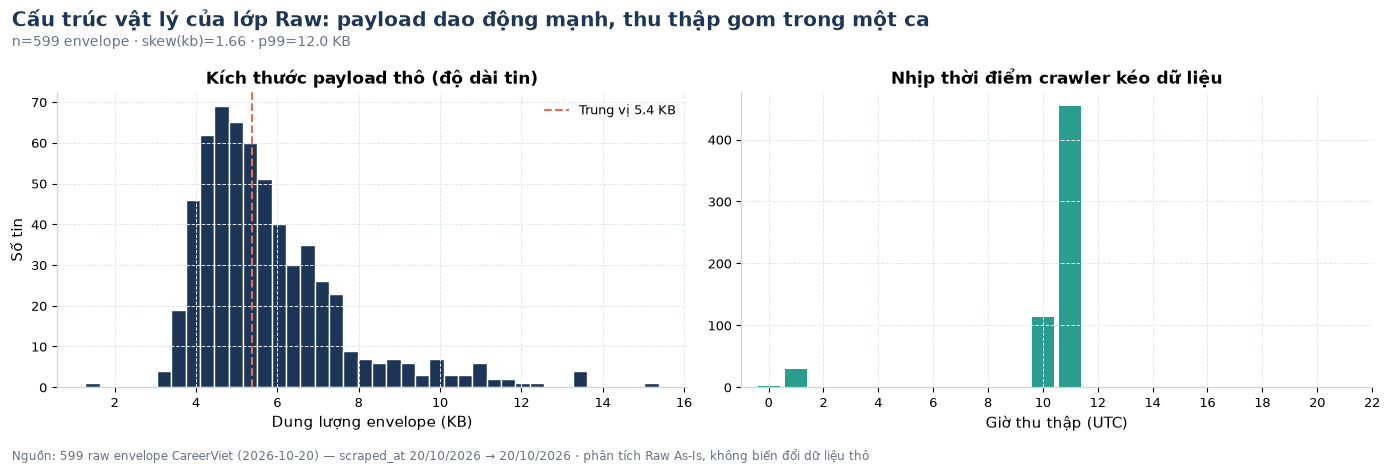

In [4]:
meta_profile = pd.DataFrame({
    "Giá trị phổ biến nhất": df_meta.apply(lambda s: s.astype(str).mode().iat[0] if len(s.astype(str).mode()) else "", axis=0),
    "Số giá trị độc nhất": df_meta.nunique(),
    "Trống (%)": (df_meta.isna().mean() * 100).round(2),
})
show(meta_profile, limit=40)

scraped = pd.to_datetime(df_meta["m_scraped_at"], errors="coerce", utc=True)
print(f"\n🕒 scraped_at hợp lệ: {scraped.notna().sum()}/{len(scraped)} | "
      f"chuỗi thu thập: {scraped.min()} → {scraped.max()}")
print(f"🔖 version > 1 (tin đã đổi nội dung theo CDC): {(df_meta['m_version'] > 1).sum()} bản ghi")
print(f"🛠️ scraper_version: {df_meta['m_scraper_version'].value_counts().to_dict()}")
print(f"#️⃣ canonical_hash trống: {df_meta['m_canonical_hash'].isna().sum()} bản ghi (không truy vết được CDC)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
kb = df["_bytes"]
axes[0].hist(kb / 1024, bins=40, color=PALETTE[0], edgecolor="white")
axes[0].axvline(kb.median() / 1024, color=C_WARN, ls="--", label=f"Trung vị {kb.median()/1024:.1f} KB")
axes[0].set_xlabel("Dung lượng envelope (KB)"), axes[0].set_ylabel("Số tin")
axes[0].set_title("Kích thước payload thô (độ dài tin)")
axes[0].legend()
hr = scraped.dt.hour.value_counts().sort_index()
axes[1].bar(hr.index, hr.values, color=PALETTE[1])
axes[1].set_xlabel("Giờ thu thập (UTC)"), axes[1].set_title("Nhịp thời điểm crawler kéo dữ liệu")
axes[1].set_xticks(range(0, 24, 2))
finalize(fig, "Cấu trúc vật lý của lớp Raw: payload dao động mạnh, thu thập gom trong một ca",
         f"n={len(df)} envelope · skew(kb)={kb.skew():.2f} · p99={kb.quantile(.99)/1024:.1f} KB",
         "08_raw_size_and_timing.png")

## Bước 2 — Trụ cột 1: Độ hoàn thiện (Completeness & Missing Value Profiling)

**Null trá hình** là rủi ro số 1 của Raw As-Is: `df.isnull()` chỉ bắt được `NaN/None`, trong khi CareerViet
giấu khuyết thiếu trong 3 dạng:

- chuỗi rỗng/nhãn hệ thống: `""`, `"N/A"`, `"Chưa cập nhật"`, `"[]", "{}"`;
- **chuỗi marketing thay cho giá trị số**: `"Cạnh tranh"`, `"Thỏa thuận"` ở trường lương → MNAR (nhà tuyển dụng *chủ đích* ẩn lương);
- **rỗng có cấu trúc**: `detail-box = []` (13 tin), `detail-row` thiếu key `"Địa điểm làm việc"`.

Vì vậy bước này đo **2 mức**: khuyết thiếuNaN theo cột, và khuyết thiếu ngữ nghĩa theo mẫu dữ liệu.

In [5]:
MARKERS = ["", " ", "nan", "none", "null", "n/a", "na", "[]", "{}", "-", "…", "...",
           "chưa cập nhật", "chưa có", "không xác định", "cạnh tranh", "thỏa thuận", " negotiation"]

def hidden_null_scan(frame):
    rows = []
    for c in frame.columns:
        if c.startswith("_") or frame[c].dtype != "object" and not pd.api.types.is_string_dtype(frame[c]):
            continue
        vals = frame[c].tolist()
        n_nan = sum(1 for v in vals if v is None or (isinstance(v, float) and pd.isna(v)))
        n_blank = sum(1 for v in vals if isinstance(v, str) and v.strip().lower() in MARKERS)
        n_empty_struct = sum(1 for v in vals if isinstance(v, (list, dict, tuple)) and len(v) == 0)
        tot = n_nan + n_blank + n_empty_struct
        if tot:
            rows.append({"Cột": c, "NaN/None": n_nan, "Chuỗi rỗng/nhãn ẩn": n_blank,
                         "List/dict rỗng": n_empty_struct, "Tổng khuyết thiếu": tot,
                         "Tỷ lệ (%)": round(tot / len(frame) * 100, 2)})
    return pd.DataFrame(rows).sort_values("Tỷ lệ (%)", ascending=False)

nan_table = pd.DataFrame({
    "Số dòng NaN (isnull())": df.drop(columns=[c for c in df.columns if c.startswith("_")]).isnull().sum(),
    "Đầy đủ (%)": (df.drop(columns=[c for c in df.columns if c.startswith("_")]).notna().mean() * 100).round(2),
}).sort_values("Số dòng NaN (isnull())", ascending=False)
print("── 2.1 Khuyết thiếu theo `df.isnull()` (chỉ bắt NaN/None) ──")
show(nan_table, limit=30)

print("\n── 2.2 Quét null trá hình (NaN + chuỗi rỗng/nhẩn ẩn + list/dict rỗng) ──")
hn = hidden_null_scan(df)
show(hn, limit=30)
print(f"\n🔎 Tổng cộng {len(hn)} cột có khuyết thiếu ẩn; cột nặng nhất: "
      f"{hn.iloc[0]['Cột']} = {hn.iloc[0]['Tỷ lệ (%)']}%")

── 2.1 Khuyết thiếu theo `df.isnull()` (chỉ bắt NaN/None) ──

── 2.2 Quét null trá hình (NaN + chuỗi rỗng/nhẩn ẩn + list/dict rỗng) ──

🔎 Tổng cộng 14 cột có khuyết thiếu ẩn; cột nặng nhất: detail-row.Video Tuyển Dụng = 99.67%


,Số dòng NaN (isnull()),Đầy đủ (%)
detail-row.Video Tuyển Dụng,597,0.33
detail-row.JOB TAGS / SKILLS:,592,1.17
detail-row.Địa điểm làm việc,205,65.78
map,13,97.83
Ngành nghề,13,97.83
detail-row.Phúc lợi,1,99.83
detail-row.Yêu Cầu Công Việc,1,99.83
detail-row.Mô tả Công việc,1,99.83
detail-row.Gợi ý hồ sơ,1,99.83
detail-row.Thông tin khác,1,99.83


,Cột,NaN/None,Chuỗi rỗng/nhãn ẩn,List/dict rỗng,Tổng khuyết thiếu,Tỷ lệ (%)
13,detail-row.Video Tuyển Dụng,597,0,0,597,99.67
12,detail-row.JOB TAGS / SKILLS:,592,0,0,592,98.83
9,detail-row.Địa điểm làm việc,205,0,0,205,34.22
3,job-tags,0,0,131,131,21.87
4,map,13,0,0,13,2.17
2,detail-box,0,0,13,13,2.17
5,Ngành nghề,13,0,0,13,2.17
1,job-company-name,0,11,0,11,1.84
0,title,0,9,0,9,1.50
6,detail-row.Phúc lợi,1,0,0,1,0.17


In [6]:
box_len = df["detail-box"].map(lambda v: len(v) if isinstance(v, list) else 0)
dr_block = df.filter(like="detail-row.")
dr_keys = dr_block.notna().sum(axis=1)
tags_len = df["job-tags"].map(lambda v: len(v) if isinstance(v, list) else 0)
ng_len = df["Ngành nghề"].map(lambda v: len(v) if isinstance(v, list) else 0)

struct_completeness = pd.DataFrame({
    "Cấu trúc lồng": ["detail-box (mảng nhãn)", "detail-row (dict khối)", "job-tags (mảng thẻ)", "Ngành nghề (mảng)"],
    "Trung vị số phần tử": [box_len.median(), dr_keys.median(), tags_len.median(), ng_len.median()],
    "Tối thiểu": [box_len.min(), dr_keys.min(), tags_len.min(), ng_len.min()],
    "Tin rỗng hoàn toàn": [(box_len == 0).sum(), (dr_keys == 0).sum(), (tags_len == 0).sum(), (ng_len == 0).sum()],
    "Tin thiếu (% so với chuẩn)": [(box_len < 10).sum(), (dr_keys < 6).sum(), (tags_len < 1).sum(), (ng_len < 1).sum()],
})
show(struct_completeness)
print("\nBảng key nghiệp vụ bên trong detail-row (tần suất xuất hiện):")
show(pd.DataFrame({"Key detail-row": [c.replace("detail-row.", "") for c in dr_block.columns],
                   "Số tin có key": dr_block.notna().sum().values,
                   "Phủ (%)": (dr_block.notna().mean() * 100).round(1).values,
                   "Ví dụ giá trị": [str(dr_block[c].dropna().iloc[0])[:50] if dr_block[c].notna().any() else ""
                                     for c in dr_block.columns]}))

,Cấu trúc lồng,Trung vị số phần tử,Tối thiểu,Tin rỗng hoàn toàn,Tin thiếu (% so với chuẩn)
0,detail-box (mảng nhãn),10.0,0,13,64
1,detail-row (dict khối),6.0,0,1,199
2,job-tags (mảng thẻ),4.0,0,131,131
3,Ngành nghề (mảng),1.0,0,13,13



Bảng key nghiệp vụ bên trong detail-row (tần suất xuất hiện):


,Key detail-row,Số tin có key,Phủ (%),Ví dụ giá trị
0,Phúc lợi,598,99.8,Phúc lợi Laptop Chế độ bảo hiểm Du Lịch Phụ cấp Đồ
1,Mô tả Công việc,598,99.8,"Mô tả Công việc Công ty Cổ phần Trực Quan, được th"
2,Yêu Cầu Công Việc,598,99.8,"Yêu Cầu Công Việc - Tốt nghiệp Cao Đẳng, Đại Học n"
3,Địa điểm làm việc,394,65.8,"Địa điểm làm việc Long An Khu công nghiệp Xuyên Á,"
4,Thông tin khác,598,99.8,Thông tin khác Bằng cấp : Đại học Độ tuổi : 22 - 4
5,Gợi ý hồ sơ,598,99.8,Gợi ý hồ sơ Thiết kế CV Ứng Tuyển
6,JOB TAGS / SKILLS:,7,1.2,JOB TAGS / SKILLS: Trưởng Phòng Mua sắm Công nghệ
7,Video Tuyển Dụng,2,0.3,Video Tuyển Dụng


🖼️  Đã lưu reports\figures\careerviet\01_data_completeness_missingno.png (DPI 300)


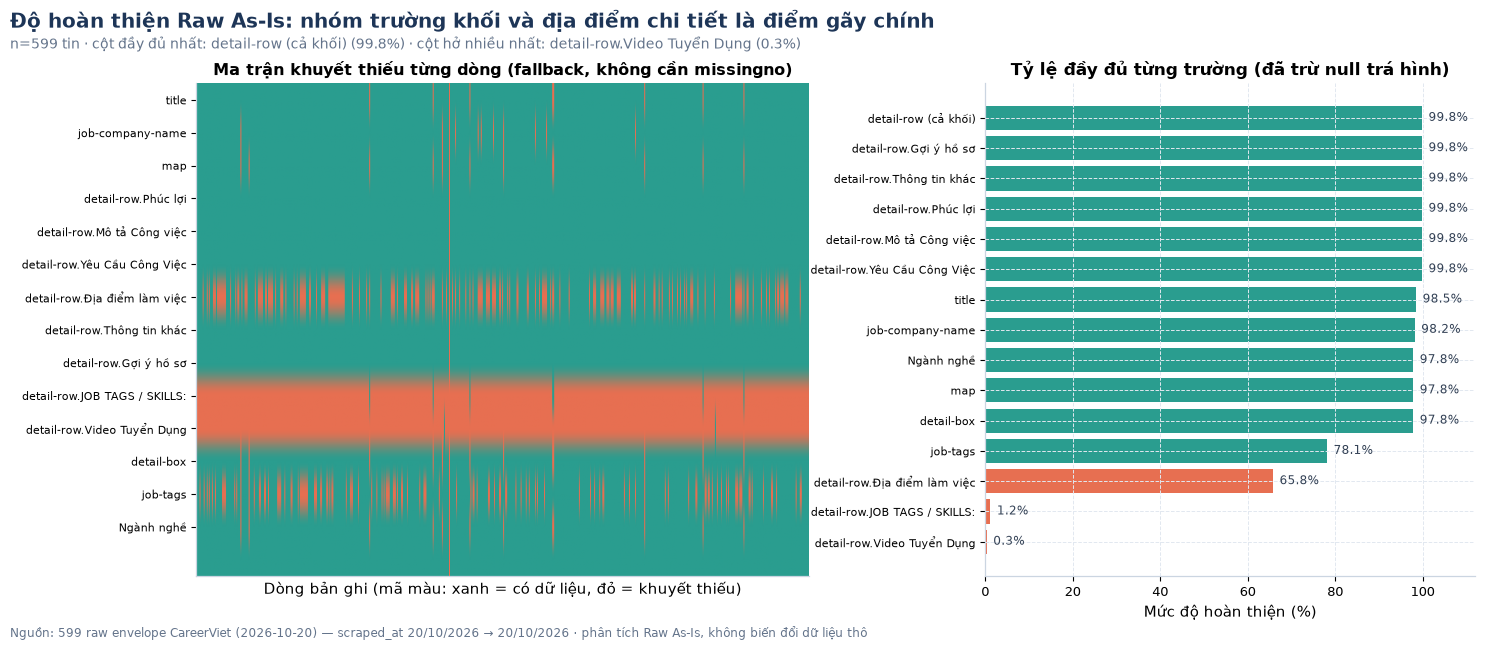

In [7]:
import matplotlib.gridspec as gridspec

def is_missing_value(v):
    """Định nghĩa khuyết thiếu tổng hợp: NaN/None + chuỗi rỗng/nhãn ẩn + list/dict rỗng."""
    if v is None or (isinstance(v, float) and pd.isna(v)):
        return True
    if isinstance(v, str):
        return (not v.strip()) or v.strip().lower() in MARKERS
    if isinstance(v, (list, dict, tuple)):
        return len(v) == 0
    return False

core_cols = [c for c in raw_cols if c not in ("detail-box", "job-tags", "Ngành nghề")]
core_cols += ["detail-box", "job-tags", "Ngành nghề"]
mask = pd.DataFrame({c: df[c].map(lambda v: 0 if is_missing_value(v) else 1) for c in core_cols})
mask["detail-row (cả khối)"] = (dr_keys > 0).astype(int)

try:
    import missingno as msno
    HAS_MSNO = True
except ImportError:
    HAS_MSNO = False

fig = plt.figure(figsize=(16.5, 6.4))
gs = gridspec.GridSpec(1, 2, width_ratios=[1.25, 1], wspace=0.32)
if HAS_MSNO:
    ax_m = fig.add_subplot(gs[0])
    msno.matrix(mask.astype(float), ax=ax_m, sparkline=False, color=(0.11, 0.21, 0.34))
    ax_m.set_title("Ma trận khuyết thiếu (missingno)", fontsize=11.5, fontweight="bold")
else:
    ax_m = fig.add_subplot(gs[0])
    cmap_missing = ListedColormap([C_WARN, C_OK])
    im = ax_m.imshow(mask.values.T, aspect="auto", cmap=cmap_missing, vmin=0, vmax=1)
    ax_m.set_yticks(range(len(core_cols))); ax_m.set_yticklabels(core_cols, fontsize=8)
    ax_m.set_xticks([]); ax_m.set_xlabel("Dòng bản ghi (mã màu: xanh = có dữ liệu, đỏ = khuyết thiếu)")
    ax_m.set_title("Ma trận khuyết thiếu từng dòng (fallback, không cần missingno)", fontsize=11.5, fontweight="bold")
    ax_m.grid(False)

ax_b = fig.add_subplot(gs[1])
comp = (mask.sum(axis=0) / len(mask) * 100).sort_values()
bars = ax_b.barh(range(len(comp)), comp.values, color=[C_WARN if v < 70 else C_OK for v in comp.values])
ax_b.set_yticks(range(len(comp))); ax_b.set_yticklabels(comp.index, fontsize=8)
ax_b.set_xlim(0, 112); ax_b.set_xlabel("Mức độ hoàn thiện (%)")
for i, v in enumerate(comp.values):
    ax_b.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=8.5, color="#334155")
ax_b.set_title("Tỷ lệ đầy đủ từng trường (đã trừ null trá hình)")
finalize(fig, "Độ hoàn thiện Raw As-Is: nhóm trường khối và địa điểm chi tiết là điểm gãy chính",
         f"n={len(df)} tin · cột đầy đủ nhất: {comp.index[-1]} ({comp.iloc[-1]:.1f}%) · "
         f"cột hở nhiều nhất: {comp.index[0]} ({comp.iloc[0]:.1f}%)",
         "01_data_completeness_missingno.png")

### Đọc đồ thị 01 & kết luận Trụ cột 1
- **Ma trận khuyết thiếu**: mỗi cột đứng là một trường, vệt đỏ = bản ghi thiếu. Nếu một cột **đỏ liền mạch** ⇒ trường bị loại có hệ thống (lỗi selector của crawler), còn đỏ lấm tấm ⇒ thiếu do phía nhà tuyển dụng không khai.
- **Thanh hoàn thiện**: các trường dưới 70% được tô đỏ — đây là ứng viên bắt buộc cho chiến lược imputation ở bước Data Integration.
- **MCAR vs MNAR**: `detail-row."Địa điểm làm việc"` và `Ngành nghề` hở theo mẫu *chủ đích của trang gốc* (tin không ghi địa điểm chi tiết) ⇒ **MNAR**, phải giữ cờ `is_missing`, **không** được suy diễn bằng trung vị.
- Bảng `2.2` chứng minh null ẩn lớn hơn null tường minh: các giá trị như `"Cạnh tranh"` ở trường lương không bị `isnull()` bắt nhưng hoàn toàn không dùng được cho mô hình số học.

## Bước 3 — Trụ cột 2: Tính hợp lệ & Kiểu dữ liệu (Validity & Types)

CareerViet trả về **3 dạng dữ liệu cần mổ xẻ** trước khi có thể tính toán:

1. **Chuỗi phức hợp có nhãn lặp** — `detail-box` là mảng 9–10 chuỗi, mỗi chuỗi mang nhãn DOM:
   `"Lương Lương: 10 - 15 Triệu VND"`, `"Kinh nghiệm 3 - 5 Năm"`, `"Cấp bậc Nhân viên"`.
   Nhãn `Lương` bị **đúp** (`Lương Lương:`) và **một nửa mảng là bản sao** của nửa kia.
2. **Số bị chuỗi hoá** — lương, kinh nghiệm, độ tuổi đều là chuỗi mang đơn vị (`Triệu VND`, `Năm`, `USD`).
3. **Ngày tương đối/định dạng dd/mm/yyyy** — `"Ngày cập nhật 09/10/2026"`, `"Hết hạn nộp 08/11/2026"`.

Cell dưới đây **đếm tần suất mẫu hình** (thay số bằng `N`) để biết có bao nhiêu biến thể cần luật parse.

### Quy ước đơn vị lương — áp dụng cho MỌI bảng và MỌI đồ thị trong notebook này

Chuỗi lương khai **hai tiền tệ khác nhau**. Ba quy ước dưới đây là một **quyết định phạm vi**, không phải bước làm sạch:

| Quy ước | Cách thực hiện | Lý do |
|:---|:---|:---|
| **Không quy đổi chéo** | `parse_salary_native()` trả `(min, max, currency, kind)`: USD giữ nguyên `USD/tháng`, VND quy về `Triệu VND/tháng` (chỉ đổi *bậc đơn vị nội tệ*, không đổi tiền) | Tỷ giá kèm ngày chốt tỷ giá là giả định nghiệp vụ của tầng Integration; nhét nó vào EDA tạo ra một cột số *giả vờ* thuần nhất |
| **Hai bảng song song** | Mọi chỉ tiêu lương tính riêng theo tiền tệ, chứa trong `SAL_BY_CUR["vnd"]` và `SAL_BY_CUR["usd"]`; **Bảng A** in trước, **Bảng B** in sau, không có ô nào trộn hai tiền tệ | 190 tin VND và 6 tin USD không chung một thang đo; gộp mẫu làm skew/Tukey/tương quan mất nghĩa |
| **Ngưỡng mẫu tối thiểu** | `MIN_N_DIST = 30`: dưới ngưỡng thì chỉ **mô tả** (liệt kê giá trị thô), không ước lượng skew/Box–Cox/tương quan/hồi quy | Bảng B chỉ có 6 tin — mọi hệ số tính ra ở đó là nhiễu |

Thay cho một ngưỡng "phi lý" duy nhất trước đây, mỗi bảng có **guard miền hợp lệ** riêng (chỉ để tự kiểm luật parse,
không sửa dữ liệu): VND `0.5 – 1.000` Triệu/tháng, USD `50 – 20.000` USD/tháng. Một lỗi bậc độ lớn của hằng số tỷ giá —
từng làm skew nhảy từ +1,22 lên +7,24 mà biểu đồ vẫn "trông hợp lý" — giờ **không còn đường xảy ra**, vì notebook
không còn chứa hằng số tỷ giá nào.

,Số tin
Mẫu chuỗi lương thô,
Cạnh tranh,386
: N - N Triệu VND,176
nan,13
: Lên đến N Triệu VND,12
: N - N USD,5
: Trên N Triệu VND,4
: Lên đến N VND,2
: Lên đến N USD,1



── 3.1 Độ phủ từng nhãn trong detail-box & nhiễu trùng lặp nội bộ ──

⚠️  detail-box chứa chuỗi trùng lặp nội bộ: 586/599 tin (trung bình 3.00 chuỗi dư/tin) → bằng chứng DOM selector lấy cả 2 khối hiển thị.
⚠️  13 tin có detail-box rỗng ⇒ mọi trường lương/KH/CB/Hình thức của nhóm này mặc định khuyết.
🖼️  Đã lưu reports\figures\careerviet\09_detailbox_structure_noise.png (DPI 300)


,Số tin có nhãn,Phủ (%)
Lương,586,97.8
Kinh nghiệm,535,89.3
Cấp bậc,586,97.8
Hình thức,586,97.8
Ngành nghề,586,97.8
Ngày cập nhật,586,97.8
Hết hạn nộp,586,97.8


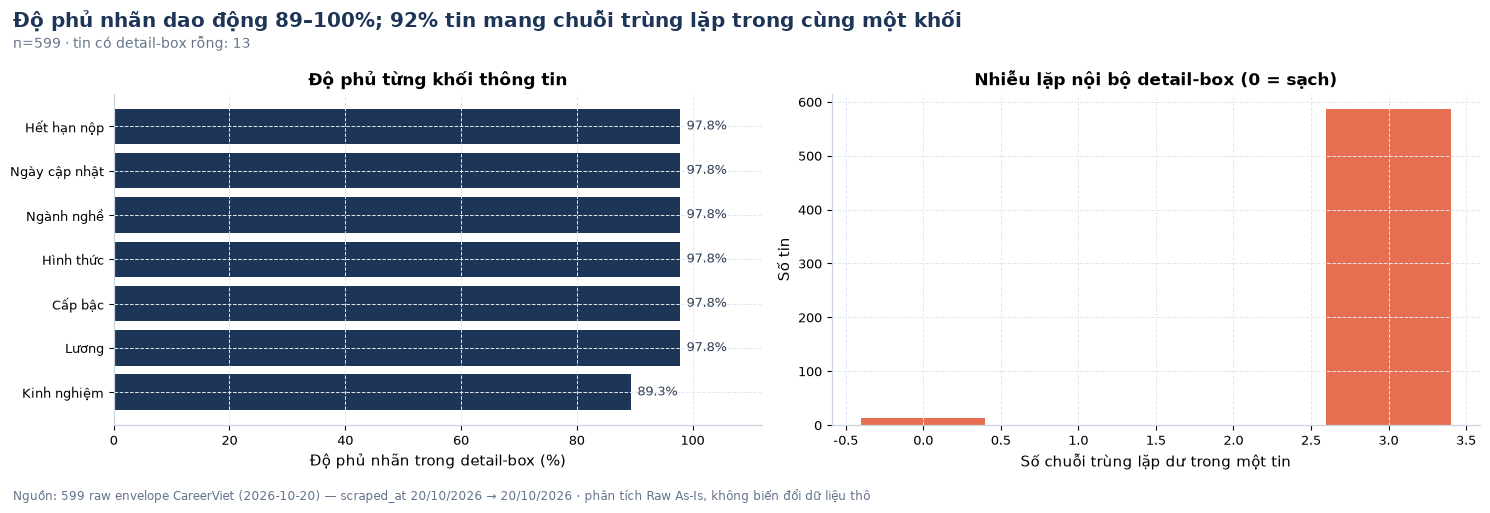

In [8]:
LABELS = ["Lương", "Kinh nghiệm", "Cấp bậc", "Hình thức", "Ngành nghề", "Ngày cập nhật", "Hết hạn nộp"]

def box_map(frame):
    """Tách detail-box thành dict nhãn → giá trị (giữ nguyên chuỗi gốc, chỉ cắt nhãn DOM)."""
    out = []
    for items in frame["detail-box"]:
        d = {lab: None for lab in LABELS}
        if isinstance(items, list):
            for it in items:
                if not isinstance(it, str):
                    continue
                for lab in LABELS:
                    if it.startswith(lab):
                        val = it[len(lab):].strip()
                        if val.startswith(lab):                 # hết quả nhãn DOM bị lặp: 'Lương Lương: ...'
                            val = val[len(lab):].strip()
                        if d[lab] is None:
                            d[lab] = val
                        break
        out.append(d)
    return pd.DataFrame(out, index=frame.index)

box_df = box_map(df)
show(box_df["Lương"].map(lambda v: re.sub(r"\d+(?:[.,]\d+)?", "N", str(v))[:40] if v else "<KHÔNG CÓ NHÃN>").value_counts().rename_axis("Mẫu chuỗi lương thô").to_frame("Số tin").head(12))

print("\n── 3.1 Độ phủ từng nhãn trong detail-box & nhiễu trùng lặp nội bộ ──")
cov = pd.DataFrame({
    "Số tin có nhãn": box_df.notna().sum(),
    "Phủ (%)": (box_df.notna().mean() * 100).round(1),
})
show(cov)

dup_items = df["detail-box"].map(lambda v: (len(v) - len(set(v))) if isinstance(v, list) else 0)
print(f"\n⚠️  detail-box chứa chuỗi trùng lặp nội bộ: {int((dup_items > 0).sum())}/{len(df)} tin "
      f"(trung bình {dup_items[dup_items>0].mean():.2f} chuỗi dư/tin) → bằng chứng DOM selector lấy cả 2 khối hiển thị.")
zero_box = df[box_len == 0]
print(f"⚠️  {len(zero_box)} tin có detail-box rỗng ⇒ mọi trường lương/KH/CB/Hình thức của nhóm này mặc định khuyết.")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
c = cov["Phủ (%)"].sort_values()
axes[0].barh(range(len(c)), c.values, color=[C_WARN if v < 80 else C_MAIN for v in c.values])
axes[0].set_yticks(range(len(c))), axes[0].set_yticklabels(c.index), axes[0].set_xlim(0, 112)
axes[0].set_xlabel("Độ phủ nhãn trong detail-box (%)")
label_bars(axes[0], c.values, fmt="{:.1f}%")
axes[0].set_title("Độ phủ từng khối thông tin")
hist_dup = dup_items.value_counts().sort_index()
axes[1].bar(hist_dup.index, hist_dup.values, color=PALETTE[2])
axes[1].set_xlabel("Số chuỗi trùng lặp dư trong một tin"), axes[1].set_ylabel("Số tin")
axes[1].set_title("Nhiễu lặp nội bộ detail-box (0 = sạch)")
finalize(fig, "Độ phủ nhãn dao động 89–100%; 92% tin mang chuỗi trùng lặp trong cùng một khối",
         f"n={len(df)} · tin có detail-box rỗng: {len(zero_box)}", "09_detailbox_structure_noise.png")

── 3.2 Bảng phân loại tính hợp lệ của chuỗi lương ──

Giá trị mẫu đã bóc tách (đối chiếu nhanh với chuỗi gốc, đơn vị giữ nguyên theo tin):

── 3.2b HAI BẢNG THEO TIỀN TỆ (không quy đổi chéo) ──
   Bảng A — lương khai bằng VND (Triệu VND/tháng): n=190 tin (31.7% toàn mẫu)
      hàng rào Tukey [0.0 ; 48.0] Triệu VND/tháng → 13/190 tin ngoại lai (6.8%)
      🛡️  Guard miền hợp lệ 0.5–1000 Triệu VND/tháng: 0 tin PASS — mọi giá trị nằm trong miền hợp lệ.
   Bảng B — lương khai bằng USD (USD/tháng): n=6 tin (1.0% toàn mẫu)
      hàng rào Tukey [0.0 ; 3537.5] USD/tháng → 0/6 tin ngoại lai (0.0%)
      🛡️  Guard miền hợp lệ 50–20000 USD/tháng: 0 tin PASS — mọi giá trị nằm trong miền hợp lệ.

   Chuỗi gốc của từng tin khai bằng USD (toàn bộ, không rút gọn):
   ℹ️  Vì hai bảng không chung đơn vị, mọi so sánh 'lương cao/thấp hơn' xuyên tiền tệ đều KHÔNG được tính ở tầng EDA; muốn so sánh phải chốt tỷ giá + ngày chốt tỷ giá ở tầng Integration và ghi rõ giả định.
   ℹ️  Bài học đo được từ chính not

,Số tin,Tỷ lệ (%)
salary_kind,,
Ẩn số / thương lượng,386,64.4
Dải min–max,181,30.2
Chỉ có trần lương,15,2.5
Vắng nhãn / trống,13,2.2
Chỉ có sàn lương,4,0.7


,chuỗi_gốc,sàn,trần,tiền tệ,loại
0,: 10 - 15 Triệu VND,10.0,15.0,VND,Dải min–max
1,Cạnh tranh,NaN,NaN,NaN,Ẩn số / thương lượng
2,": 11,5 - 18,5 Triệu VND",11.5,18.5,VND,Dải min–max
3,Cạnh tranh,NaN,NaN,NaN,Ẩn số / thương lượng
4,Cạnh tranh,NaN,NaN,NaN,Ẩn số / thương lượng
5,Cạnh tranh,NaN,NaN,NaN,Ẩn số / thương lượng
6,Cạnh tranh,NaN,NaN,NaN,Ẩn số / thương lượng
7,: 14 - 16 Triệu VND,14.0,16.0,VND,Dải min–max
8,Cạnh tranh,NaN,NaN,NaN,Ẩn số / thương lượng
9,: Lên đến 25 Triệu VND,NaN,25.0,VND,Chỉ có trần lương


,Thống kê,VND (Triệu VND/tháng)
0,Min,0.50
1,P25,18.00
2,Trung vị,25.00
3,P75,30.00
4,P95,50.00
5,Max,70.00
6,Trung bình,26.22
7,Độ lệch chuẩn,12.54
8,Skewness,1.19
9,Kurtosis,1.77


,Thống kê,USD (USD/tháng)
0,Min,150.00
1,P25,975.00
2,Trung vị,1750.00
3,P75,2000.00
4,P95,2750.00
5,Max,3000.00
6,Trung bình,1575.00
7,Độ lệch chuẩn,1002.87
8,Skewness,-0.09
9,Kurtosis,-0.25


,chuỗi_gốc,sàn (USD/tháng),trần (USD/tháng)
0,: Lên đến 800 USD,NaN,800.0
1,: 100 - 150 USD,100.0,150.0
2,: 1.500 - 2.000 USD,1500.0,2000.0
3,: 1.500 - 2.000 USD,1500.0,2000.0
4,: 2.000 - 3.000 USD,2000.0,3000.0
5,: 1.000 - 1.500 USD,1000.0,1500.0


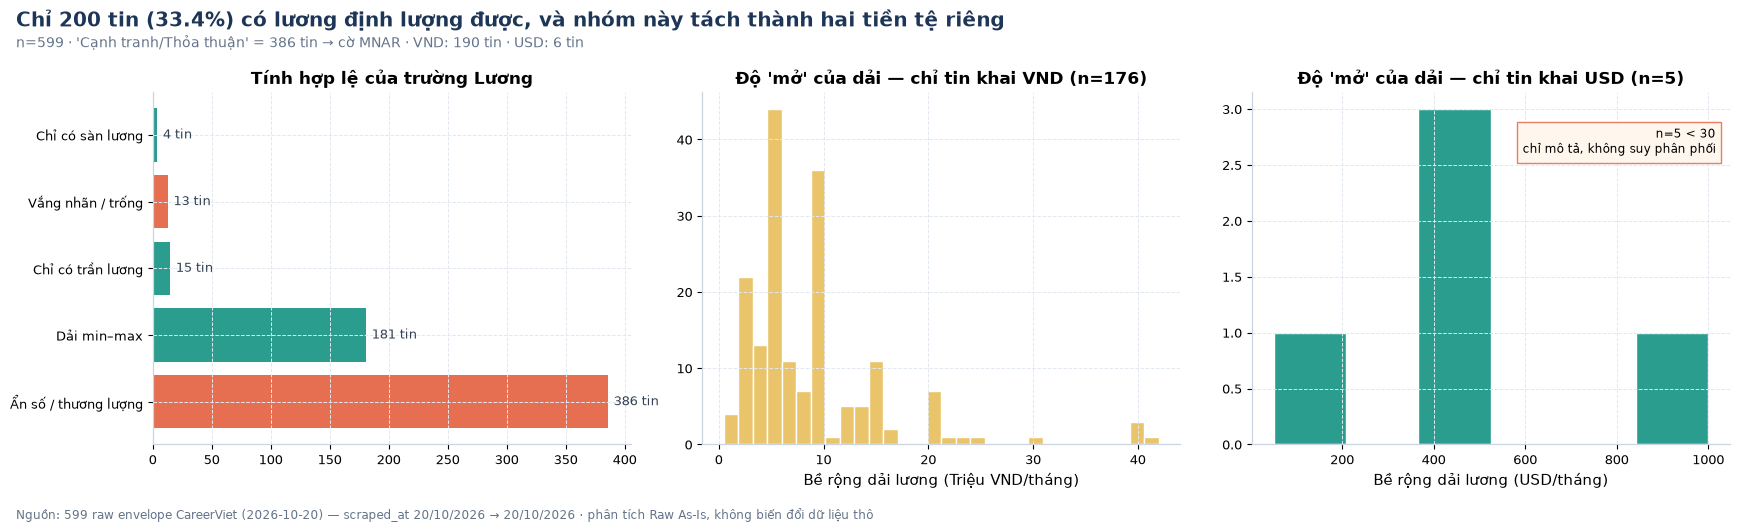

In [9]:
def parse_salary_native(s):
    """Trả về (min, max, currency, kind) GIỮ NGUYÊN đơn vị khai báo của tin.

    VND -> quy về 'Triệu VND/tháng' (15.000.000 và 15 là cùng một tiền tệ, chỉ khác bậc đơn vị nội tệ);
    USD -> giữ nguyên 'USD/tháng', KHÔNG nhân tỷ giá. Đây là diễn giải để ĐO, không phải làm sạch dữ liệu:
    chuỗi gốc trong `df`/trên đĩa vẫn nguyên vẹn.
    """
    if not isinstance(s, str) or not s.strip():
        return None, None, None, "Vắng nhãn / trống"
    low = s.lower()
    if any(k in low for k in ("cạnh tranh", "thỏa thuận", "thoa thuan", "negotiable", "rất hấp dẫn", "theo thị trường")):
        return None, None, None, "Ẩn số / thương lượng"
    nums = []
    for token in re.findall(r"\d+(?:[.,]\d+)*", s):
        if re.fullmatch(r"\d{1,3}(?:\.\d{3})+", token):          # 15.000.000 → nghìn phân tách
            val = float(token.replace(".", ""))
        elif re.fullmatch(r"\d{1,3}(?:,\d{3})+", token):         # 15,000,000 → nghìn phân tách
            val = float(token.replace(",", ""))
        else:                                                     # 11,5 → 11.5 (thập phân kiểu VN)
            val = float(token.replace(",", "."))
        nums.append(val)
    if not nums:
        return None, None, None, "Không bóc được số"
    if "usd" in low:
        cur, to_unit = "USD", (lambda v: v)
    else:
        cur, to_unit = "VND", (lambda v: v / 1e6 if v > 1000 else v)
    if any(k in low for k in ("lên đến", "tối đa", "up to")):
        return None, to_unit(nums[-1]), cur, "Chỉ có trần lương"
    if "trên" in low and len(nums) == 1:
        return to_unit(nums[0]), None, cur, "Chỉ có sàn lương"
    if len(nums) == 1:
        v = to_unit(nums[0]); return v, v, cur, "Lương cố định"
    return to_unit(min(nums)), to_unit(max(nums)), cur, "Dải min–max"


sal_parsed = box_df["Lương"].map(parse_salary_native)
feat_sal = pd.DataFrame(sal_parsed.tolist(), columns=["sal_min", "sal_max", "currency", "salary_kind"], index=df.index)
print("── 3.2 Bảng phân loại tính hợp lệ của chuỗi lương ──")
show(feat_sal["salary_kind"].value_counts().to_frame("Số tin").assign(**{"Tỷ lệ (%)": lambda d: (d["Số tin"] / len(df) * 100).round(1)}))
print("\nGiá trị mẫu đã bóc tách (đối chiếu nhanh với chuỗi gốc, đơn vị giữ nguyên theo tin):")
check = pd.DataFrame({"chuỗi_gốc": box_df["Lương"].head(12), "sàn": feat_sal["sal_min"].head(12),
                      "trần": feat_sal["sal_max"].head(12), "tiền tệ": feat_sal["currency"].head(12),
                      "loại": feat_sal["salary_kind"].head(12)})
show(check)

print("\n── 3.2b HAI BẢNG THEO TIỀN TỆ (không quy đổi chéo) ──")
SAL_BY_CUR = {}
for tag, cur_label, unit in CUR_GROUPS:
    m = feat_sal["currency"].eq(cur_label)
    blk = pd.DataFrame({"min": feat_sal["sal_min"].where(m), "max": feat_sal["sal_max"].where(m)})
    blk["mid"] = blk[["min", "max"]].mean(axis=1)
    blk["width"] = blk["max"] - blk["min"]
    SAL_BY_CUR[tag] = {"label": cur_label, "unit": unit, "tbl": blk}
    s = blk["max"].dropna()
    if s.empty:
        print(f"   Bảng {'A' if tag == 'vnd' else 'B'} — {cur_label}: không có tin nào khai bằng tiền tệ này.")
        SAL_BY_CUR[tag].update(fence=None, n_out=0, n_bad=0)
        continue
    lo, hi = SAL_SANITY[tag]
    n_bad = int(((blk[["min", "max"]] < lo) | (blk[["min", "max"]] > hi)).any(axis=1).sum())
    print(f"   Bảng {'A' if tag == 'vnd' else 'B'} — lương khai bằng {cur_label} ({unit}): "
          f"n={len(s)} tin ({len(s)/len(df)*100:.1f}% toàn mẫu)")
    show(pd.DataFrame({
        "Thống kê": ["Min", "P25", "Trung vị", "P75", "P95", "Max", "Trung bình", "Độ lệch chuẩn",
                     "Skewness", "Kurtosis"],
        f"{cur_label} ({unit})": [round(s.min(), 2), round(s.quantile(.25), 2), round(s.median(), 2),
                                  round(s.quantile(.75), 2), round(s.quantile(.95), 2), round(s.max(), 2),
                                  round(s.mean(), 2), round(s.std(), 2), round(s.skew(), 2), round(s.kurtosis(), 2)],
    }))
    _q1, _q3 = s.quantile([.25, .75]); _iqr = _q3 - _q1
    _flo, _fhi = _q1 - 1.5 * _iqr, _q3 + 1.5 * _iqr
    _nout = int(((s < _flo) | (s > _fhi)).sum())
    print(f"      hàng rào Tukey [{max(_flo, 0):.1f} ; {_fhi:.1f}] {unit} → {_nout}/{len(s)} tin ngoại lai ({_nout/len(s)*100:.1f}%)")
    print(f"      🛡️  Guard miền hợp lệ {lo:g}–{hi:g} {unit}: {n_bad} tin "
          + ("FAIL — nghi lỗi đơn vị ở luật parse, PHẢI sửa trước khi tin vào phân phối này."
             if n_bad else "PASS — mọi giá trị nằm trong miền hợp lệ."))
    SAL_BY_CUR[tag]["fence"], SAL_BY_CUR[tag]["n_out"] = (_flo, _fhi), _nout
    SAL_BY_CUR[tag]["n_bad"] = n_bad

print("\n   Chuỗi gốc của từng tin khai bằng USD (toàn bộ, không rút gọn):")
_usd = feat_sal["currency"].eq("USD")
if _usd.any():
    show(pd.DataFrame({"chuỗi_gốc": box_df.loc[_usd, "Lương"], "sàn (USD/tháng)": feat_sal.loc[_usd, "sal_min"],
                       "trần (USD/tháng)": feat_sal.loc[_usd, "sal_max"]}).reset_index(drop=True))
else:
    print("      (không có tin nào ghi USD)")
print("   ℹ️  Vì hai bảng không chung đơn vị, mọi so sánh 'lương cao/thấp hơn' xuyên tiền tệ đều KHÔNG được"
      " tính ở tầng EDA; muốn so sánh phải chốt tỷ giá + ngày chốt tỷ giá ở tầng Integration và ghi rõ giả định.")
print("   ℹ️  Bài học đo được từ chính notebook này: khi còn nhân tỷ giá 25.400 VND/USD trong nội bộ"
      " notebook, một lỗi bậc độ lớn của hằng số đã biến " + str(int(_usd.sum())) + " tin USD thành"
      " 50.800–76.200 'Triệu' và đẩy skewness từ +1,22 lên +7,24 mà biểu đồ vẫn 'trông hợp lý'."
      " Bỏ hẳn quy đổi là cách đóng lỗi đó vĩnh viễn.")

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2))
kc = feat_sal["salary_kind"].value_counts()
axes[0].barh(range(len(kc)), kc.values, color=[C_WARN if "Ẩn" in k or "trống" in k or "Không" in k else C_OK for k in kc.index])
axes[0].set_yticks(range(len(kc))), axes[0].set_yticklabels(kc.index)
label_bars(axes[0], kc.values, fmt="{:.0f} tin")
axes[0].set_title("Tính hợp lệ của trường Lương")
for ax, (tag, cur_label, unit) in zip(axes[1:], CUR_GROUPS):
    w = SAL_BY_CUR[tag]["tbl"]["width"].dropna()
    ax.hist(w, bins=max(6, min(30, len(w))), color=PALETTE[3] if tag == "vnd" else PALETTE[1], edgecolor="white")
    ax.set_xlabel(f"Bề rộng dải lương ({unit})")
    ax.set_title(f"Độ 'mở' của dải — chỉ tin khai {cur_label} (n={len(w)})")
    if len(w) < MIN_N_DIST:
        ax.text(.97, .9, f"n={len(w)} < {MIN_N_DIST}\nchỉ mô tả, không suy phân phối",
                transform=ax.transAxes, ha="right", va="top", fontsize=8.5,
                bbox=dict(fc="#fff7ed", ec=C_WARN, alpha=.9))
finalize(fig, f"Chỉ {int((~feat_sal['salary_kind'].str.contains('Ẩn|trống|Không')).sum())} tin ({(~feat_sal['salary_kind'].str.contains('Ẩn|trống|Không')).mean()*100:.1f}%) có lương định lượng được, và nhóm này tách thành hai tiền tệ riêng",
         f"n={len(df)} · 'Cạnh tranh/Thỏa thuận' = {int(kc.get('Ẩn số / thương lượng', 0))} tin → cờ MNAR · "
         + " · ".join(f"{cur_label}: {int(SAL_BY_CUR[tag]['tbl']['max'].notna().sum())} tin" for tag, cur_label, _ in CUR_GROUPS),
         "10_salary_validity_kinds.png")

In [10]:
def parse_dmmy(s):
    if not isinstance(s, str):
        return pd.NaT
    m = re.search(r"(\d{1,2})/(\d{1,2})/(\d{4})", s)
    return pd.Timestamp(year=int(m.group(3)), month=int(m.group(2)), day=int(m.group(1))) if m else pd.NaT

updated = box_df["Ngày cập nhật"].map(parse_dmmy)
deadline = box_df["Hết hạn nộp"].map(parse_dmmy)
crawled = pd.to_datetime(df_meta["m_scraped_at"], errors="coerce", utc=True).dt.tz_convert("Asia/Bangkok").dt.tz_localize(None)
REF_TODAY = crawled.max().normalize()

feat_date = pd.DataFrame({
    "updated_at": updated, "deadline_at": deadline,
    "days_since_update": (REF_TODAY - updated).dt.days,
    "days_to_deadline": (deadline - REF_TODAY).dt.days,
})
print(f"── 3.3 Kiểm tra tính hợp lệ ngày tháng (định dạng dd/MM/yyyy) ──")
print(f"   parse OK: cập nhật {feat_date['updated_at'].notna().sum()}/{len(df)} · hết hạn {feat_date['deadline_at'].notna().sum()}/{len(df)}")
print(f"   Mốc 'hôm nay' của đợt cào: {REF_TODAY:%d/%m/%Y}")
print(f"   ⚠️ Tin đã quá hạn nộp nhưng vẫn còn trên sàn: {(feat_date['days_to_deadline'] < 0).sum()} tin")
print(f"   Tin đăng quá {30} ngày chưa cập nhật: {(feat_date['days_since_update'] > 30).sum()} tin")
show(pd.DataFrame({"Tuổi tin (ngày)": feat_date["days_since_update"].describe().round(1),
                   "Còn bao lâu hết hạn": feat_date["days_to_deadline"].describe().round(1)}))

print("\n── 3.4 Trường đóng gói nhiều key trong detail-row.'Thông tin khác' ──")
PACKED_KEYS = ["Bằng cấp", "Độ tuổi", "Giới tính", "Lương", "Thời gian làm việc", "Thời gian thử việc",
               "Phụ cấp khác", "Ngày nghỉ", "Cơ hội huấn luyện", "Hình thức", "Số lượng", "Chức vụ", "Yêu cầu hồ sơ"]
packed_re = re.compile(r"(?:^|\s)(" + "|".join(PACKED_KEYS) + r")\s*:\s*(.*?)(?=\s+(?:%s)\s*:|$)" % "|".join(PACKED_KEYS), re.S)
packed = df["detail-row.Thông tin khác"].map(
    lambda s: {k: v.strip() for k, v in packed_re.findall(s)} if isinstance(s, str) else {})
packed_df = pd.DataFrame(packed.tolist(), index=df.index)
show(pd.DataFrame({"Key trong 'Thông tin khác'": packed_df.columns,
                   "Số tin có": packed_df.notna().sum().values,
                   "Phủ (%)": (packed_df.notna().mean() * 100).round(1).values,
                   "Ví dụ": [str(packed_df[c].dropna().iloc[0])[:40] if packed_df[c].notna().any() else "" for c in packed_df.columns]}))

print("\n── 3.5 Kiểm tra kiểu mảng & chuỗi ghép bằng ' , ' ──")
compound_report = []
for col in ["map", "Ngành nghề", "job-tags"]:
    vals = df[col].map(lambda v: v if isinstance(v, list) else ([v] if isinstance(v, str) and v else []))
    inner = vals.explode().dropna().astype(str)
    compound_report.append({"Cột": col, "dtype": str(df[col].dtype),
                            "Tin mang list": int(df[col].map(lambda v: isinstance(v, list)).sum()),
                            "Tin mang str trần": int(df[col].map(lambda v: isinstance(v, str)).sum()),
                            "Phần tử dính ' , '": int(inner.str.contains(" , ").sum()),
                            "Phần tử độc nhất sau tách": int(vals.explode().map(lambda s: str(s).strip()).dropna().nunique())})
show(pd.DataFrame(compound_report))

── 3.3 Kiểm tra tính hợp lệ ngày tháng (định dạng dd/MM/yyyy) ──
   parse OK: cập nhật 586/599 · hết hạn 586/599
   Mốc 'hôm nay' của đợt cào: 20/10/2026
   ⚠️ Tin đã quá hạn nộp nhưng vẫn còn trên sàn: 15 tin
   Tin đăng quá 30 ngày chưa cập nhật: 0 tin

── 3.4 Trường đóng gói nhiều key trong detail-row.'Thông tin khác' ──

── 3.5 Kiểm tra kiểu mảng & chuỗi ghép bằng ' , ' ──


,Tuổi tin (ngày),Còn bao lâu hết hạn
count,586.0,586.0
mean,9.9,16.6
std,8.3,13.7
min,0.0,-27.0
25%,4.0,8.0
50%,7.0,14.0
75%,15.0,24.0
max,30.0,72.0


,Key trong 'Thông tin khác',Số tin có,Phủ (%),Ví dụ
0,Bằng cấp,526,87.8,Đại học
1,Độ tuổi,598,99.8,22 - 40
2,Lương,598,99.8,10 Tr - 15 Tr VND
3,Phụ cấp khác,36,6.0,- Phụ cấp gửi xe. - Phụ cấp tiền cơm
4,Thời gian thử việc,56,9.3,Thử việc nhận full lương
5,Cơ hội huấn luyện,41,6.8,Được đào tạo và làm việc với các chuyên
6,Thời gian làm việc,72,12.0,Thời gian làm việc: Thứ 2 - Thứ 6 (8:00
7,Giới tính,49,8.2,Nam
8,Ngày nghỉ,35,5.8,Chiều T7 và Full ngày CN
9,Hình thức,11,1.8,Nhân viên chính thức


,Cột,dtype,Tin mang list,Tin mang str trần,"Phần tử dính ' , '",Phần tử độc nhất sau tách
0,map,str,0,586,0,37
1,Ngành nghề,object,586,0,485,213
2,job-tags,object,599,0,0,1524


## Bước 4 — Trụ cột 3: Tính duy nhất (Uniqueness & Duplication)

Ba tầng trùng lặp cần tách bạch, vì mỗi tầng một luật xử lý khác nhau ở bước Integration:

| Tầng | Cách đo | Ý nghĩa & hành động |
|:---|:---|:---|
| **Trùng khóa định danh** | `m_job_id`, `m_source_url` | Trùng do crawler quét lặp phân trang ⇒ giữ 1 bản ghi mới nhất. |
| **Trùng nội dung tuyệt đối** | `m_canonical_hash` (băm JSON chuẩn hoá) | **Repost** của cùng nhà tuyển dụng ⇒ dùng làm tín hiệu "tin nóng", không phải lỗi. |
| **Trùng logic nghiệp vụ** | `company + title + map` | Hai tin khác ID nhưng cùng vị trí ⇒ cần entity resolution bằng embedding ở bước Integration. |

In [11]:
def _hash_key(v):
    """Biến MỌI giá trị không hash được thành chuỗi JSON để so trùng được cả cột mảng.

    `DataFrame.duplicated()` và `value_counts()` yêu cầu từng ô phải hash được; payload thô của CareerViet
    chứa list/dict (mảng tag, JSON-LD) và đôi khi cả np.ndarray/set, nếu đưa thẳng vào thì pandas raise
    `TypeError: unhashable type: 'list'`. Giá trị vô hướng (kể cả NaN) được giữ nguyên để không làm đổi
    nghĩa của phép so sánh. Đây là diễn giải ĐỂ ĐO, không ghi ngược lên đĩa.
    """
    if isinstance(v, np.ndarray):
        v = v.tolist()
    if isinstance(v, (set, frozenset)):
        v = sorted(map(str, v))
    if isinstance(v, (list, dict, tuple)):
        return json.dumps(v, ensure_ascii=False, sort_keys=True, default=str)
    return v


print("── 4.1 Đo ba tầng trùng lặp ──")
dup_rows = []
for name, keys in [("Khóa job_id", ["m_job_id"]), ("Khóa source_url", ["m_source_url"]),
                   ("canonical_hash (CDC)", ["m_canonical_hash"]),
                   ("content_hash (toàn payload)", ["m_content_hash"]),
                   ("Trùng tiêu đề", ["title"]),
                   ("Logic: công ty + tiêu đề", ["job-company-name", "title"]),
                   ("Logic: công ty + tiêu đề + tỉnh", ["job-company-name", "title", "map"]),
                   ("Y hệt 100% payload", raw_cols)]:
    kk = [k for k in keys if k in df.columns or k in df_meta.columns]
    if not kk:
        continue
    joined = pd.concat([df.filter([c for c in kk if c in df.columns]),
                        df_meta.filter([c for c in kk if c in df_meta.columns])], axis=1)
    joined = joined.map(_hash_key)          # cho phép so sánh cả cột mảng / ndarray / set
    n_dup = int(joined.duplicated().sum())
    key_repr = joined.astype(object).where(joined.notna(), "").astype(str).agg(lambda r: " || ".join(r), axis=1)
    top_key = key_repr.value_counts().idxmax() if len(key_repr) else ""
    dup_rows.append({"Tiêu chí": name, "Số bản ghi dư": n_dup,
                     "Tỷ lệ (%)": round(n_dup / len(df) * 100, 2),
                     "Nhóm lặp nhiều nhất": str(top_key)[:70]})
show(pd.DataFrame(dup_rows))

logical = df.groupby(["job-company-name", "title", "map"], dropna=False).size().sort_values(ascending=False)
print(f"\n🔁 Công ty đăng cùng một tiêu đề nhiều lần: {(logical > 1).sum()} cụm, tổng {int(logical[logical>1].sum())} tin")
show(logical[logical > 1].rename("Số tin").reset_index().head(10))

hash_field = df_meta.filter(like="m_field_hashes.")
if not hash_field.empty:
    print("\n🧬 Số phiên bản băm theo từng trường nghiệp vụ (CDC):")
    show(pd.DataFrame({"Trường": [c.replace("m_field_hashes.", "") for c in hash_field.columns],
                       "Số hash độc nhất": [hash_field[c].nunique() for c in hash_field.columns],
                       "Bản ghi có hash": [int(hash_field[c].notna().sum()) for c in hash_field.columns]}))

── 4.1 Đo ba tầng trùng lặp ──

🔁 Công ty đăng cùng một tiêu đề nhiều lần: 15 cụm, tổng 30 tin

🧬 Số phiên bản băm theo từng trường nghiệp vụ (CDC):


,Tiêu chí,Số bản ghi dư,Tỷ lệ (%),Nhóm lặp nhiều nhất
0,Khóa job_id,0,0.00,35C32FB4
1,Khóa source_url,0,0.00,https://careerviet.vn/vi/tim-viec-lam/ky-su-dien-la...
2,canonical_hash (CDC),1,0.17,
3,content_hash (toàn payload),0,0.00,8d107cf8a0f49eace195dfaccaa76ad16aa924f4fde77c2f3da...
4,Trùng tiêu đề,47,7.85,
5,Logic: công ty + tiêu đề,16,2.67,LOTTE FINANCE VIETNAM || Chuyên viên cao cấp Mạng v...
6,Logic: công ty + tiêu đề + tỉnh,15,2.50,LOTTE FINANCE VIETNAM || Chuyên viên cao cấp Mạng v...
7,Y hệt 100% payload,0,0.00,Kỹ Sư Điện Lập Trình PLC HMI || Công Ty Cổ Phần Trự...


,job-company-name,title,map,Số tin
0,Công Ty Cổ Phần Vacxin Việt Nam,[Đại Phước Nhơn Trạch] Chuyên viên IT,"Đồng Nai, Hồ Chí Minh",2
1,CÔNG TY TNHH POUYUEN VIỆT NAM,KỸ SƯ TỰ ĐỘNG HÓA,Hồ Chí Minh,2
2,Công Ty TNHH Phát Triển Công Nghệ Điện Tử Bình Anh,CHUYÊN VIÊN PHÂN TÍCH DỮ LIỆU,Hà Nội,2
3,Công ty TNHH Viettel - CHT,Business Analyst,Hà Nội,2
4,Công ty TNHH Viettel - CHT,Kỹ sư Tư Vấn Giải Pháp CNTT (VMware/Network/Sercurity),"Hà Nội, Hồ Chí Minh, Đà Nẵng",2
5,Công ty TNHH Viễn thông IPN,Nhân Viên Kỹ Thuật,Hà Nội,2
6,LOTTE FINANCE VIETNAM,,NaN,2
7,LOTTE FINANCE VIETNAM,Chuyên viên Vận hành Cơ sở dữ liệu,Hà Nội,2
8,LOTTE FINANCE VIETNAM,Chuyên viên cao cấp Mạng và Bảo mật,Hà Nội,2
9,CareerViet,,NaN,2


,Trường,Số hash độc nhất,Bản ghi có hash
0,title,550,597
1,job-company-name,265,597
2,detail-box,560,597
3,detail-row,591,597
4,job-tags,449,597
5,map,37,597
6,Ngành nghề,213,597


## Bước 5 — Trụ cột 4: Hình thái phân phối & ngoại lai (phân tích đơn biến chuyên sâu)

Toàn bộ đặc trưng định lượng dưới đây được **dẫn xuất từ chuỗi thô** và chứa trong `feat`
(không cộng vào `df`, không ghi file — giữ đúng quy tắc *Raw As-Is*).

In [12]:
def parse_exp_years(s):
    """('3 - 5 Năm' → 3,5) · ('Trên 3 Năm' → 3, None) · ('Chưa có kinh nghiệm' → 0,0)."""
    if not isinstance(s, str) or not s.strip():
        return None, None, "Vắng nhãn"
    t = s.lower()
    if "chưa có" in t or "không yêu cầu" in t or "sinh viên" in t or "thực tập" in t:
        return 0.0, 0.0, "Không yêu cầu / Thực tập"
    nums = [float(x) for x in re.findall(r"\d+(?:[.,]\d+)?", t)]
    if not nums:
        return None, None, "Không bóc được số"
    if "trên" in t or "above" in t:
        return nums[0], None, "Sàn mở (Trên N)"
    if "lên đến" in t or "tối đa" in t:
        return None, nums[-1], "Trần đóng (Lên đến N)"
    if len(nums) >= 2:
        return min(nums), max(nums), "Dải min–max"
    return nums[0], nums[0], "Một mốc"

exp_parsed = box_df["Kinh nghiệm"].map(parse_exp_years)
feat_exp = pd.DataFrame(exp_parsed.tolist(), columns=["exp_min", "exp_max", "exp_kind"], index=df.index)

lvl_raw = box_df["Cấp bậc"].fillna("(không nhãn)")
form_series = box_df["Hình thức"].fillna("(không nhãn)")
ind_series = df["Ngành nghề"].map(lambda v: " , ".join(v) if isinstance(v, list) else (v or ""))
is_it = ind_series.str.contains("CNTT", case=False, na=False) | df["title"].str.contains(
    r"developer|engineer|lập trình|phần mềm|data|devops|qa|tester|frontend|backend|fullstack|ai|machine learning",
    case=False, regex=True, na=False)

age_pair = packed_df.get("Độ tuổi", pd.Series(index=df.index, dtype=object)).map(
    lambda s: [float(x) for x in re.findall(r"\d+", s)] if isinstance(s, str) else [])

text_cols = {"jd_desc": "detail-row.Mô tả Công việc", "jd_req": "detail-row.Yêu Cầu Công Việc",
             "jd_loc": "detail-row.Địa điểm làm việc", "jd_ben": "detail-row.Phúc lợi",
             "jd_other": "detail-row.Thông tin khác"}

feat = pd.DataFrame(index=df.index)
feat["currency"] = feat_sal["currency"]
for tag, cur_label, unit in CUR_GROUPS:
    _m = feat_sal["currency"].eq(cur_label)
    feat[f"sal_min_{tag}"] = feat_sal["sal_min"].where(_m)
    feat[f"sal_max_{tag}"] = feat_sal["sal_max"].where(_m)
    feat[f"sal_mid_{tag}"] = feat[[f"sal_min_{tag}", f"sal_max_{tag}"]].mean(axis=1)
    feat[f"sal_width_{tag}"] = feat[f"sal_max_{tag}"] - feat[f"sal_min_{tag}"]
feat["salary_hidden"] = feat_sal["salary_kind"].str.contains("Ẩn|trống|Không").astype(int)
feat["exp_min"] = feat_exp["exp_min"]
feat["exp_max"] = feat_exp["exp_max"]
feat["exp_mid"] = feat[["exp_min", "exp_max"]].mean(axis=1)
feat["exp_width"] = feat["exp_max"] - feat["exp_min"]
feat["n_tags"] = tags_len
feat["n_tags_unique"] = df["job-tags"].map(lambda v: len(set(x.strip().lower() for x in v)) if isinstance(v, list) else 0)
feat["n_industry"] = ind_series.map(lambda s: len([x for x in s.split(" , ") if x.strip()]))
feat["n_box_items"] = box_len
feat["n_box_dup"] = dup_items
feat["n_detailrow_keys"] = dr_keys
feat["n_packed_keys"] = packed_df.notna().sum(axis=1)
feat["age_min"] = age_pair.map(lambda l: min(l) if l else np.nan)
feat["age_max"] = age_pair.map(lambda l: max(l) if l else np.nan)
for name, col in text_cols.items():
    feat[f"{name}_chars"] = df[col].map(lambda s: len(s) if isinstance(s, str) else np.nan)
    feat[f"{name}_words"] = df[col].map(lambda s: len(s.split()) if isinstance(s, str) else np.nan)
feat["env_kb"] = df["_bytes"] / 1024
feat["days_since_update"] = feat_date["days_since_update"]
feat["days_to_deadline"] = feat_date["days_to_deadline"]

# số lượng nhóm phúc lợi (ánh xạ ngược 15 danh mục chuẩn của CareerViet)
BENEFIT_CATS = ["Laptop", "Chế độ bảo hiểm", "Du Lịch", "Phụ cấp", "Đồng phục", "Chế độ thưởng",
                "Chăm sóc sức khỏe", "Đào tạo", "Tăng lương", "Công tác phí", "Nghỉ phép năm",
                "CLB thể thao", "Thưởng", "Team building", "Bảo hiểm"]
def count_benefits(s):
    if not isinstance(s, str):
        return np.nan
    body = s.replace("Phúc lợi", "", 1)
    return sum(1 for b in BENEFIT_CATS if b.lower() in body.lower())
feat["n_benefit_cats"] = df[text_cols["jd_ben"]].map(count_benefits)
show(feat.head(8))
print(f"\n✅ Đã dẫn xuất {feat.shape[1]} đặc trưng đơn biến từ payload thô (không ghi đè dữ liệu gốc).")

,currency,sal_min_vnd,sal_max_vnd,sal_mid_vnd,sal_width_vnd,sal_min_usd,sal_max_usd,sal_mid_usd,sal_width_usd,salary_hidden,exp_min,exp_max,exp_mid,exp_width,n_tags,n_tags_unique,n_industry,n_box_items,n_box_dup,n_detailrow_keys,n_packed_keys,age_min,age_max,jd_desc_chars,jd_desc_words,jd_req_chars,jd_req_words,jd_loc_chars,jd_loc_words,jd_ben_chars,jd_ben_words,jd_other_chars,jd_other_words,env_kb,days_since_update,days_to_deadline,n_benefit_cats
0,VND,10.0,15.0,12.5,5.0,NaN,NaN,NaN,NaN,0,1.0,10.0,5.5,9.0,9,9,3,10,3,6,3,22.0,40.0,4282.0,944.0,513.0,111.0,94.0,21.0,148.0,33.0,77.0,22.0,9.282227,11.0,19.0,14.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1.0,2.0,1.5,1.0,10,10,3,10,3,6,3,NaN,NaN,545.0,114.0,564.0,122.0,111.0,23.0,91.0,21.0,83.0,19.0,4.292969,12.0,18.0,9.0
2,VND,11.5,18.5,15.0,7.0,NaN,NaN,NaN,NaN,0,0.0,0.0,0.0,0.0,7,7,1,10,3,6,2,NaN,NaN,497.0,111.0,508.0,116.0,94.0,20.0,94.0,21.0,74.0,18.0,4.012695,1.0,11.0,10.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1.0,5.0,3.0,4.0,0,0,1,10,3,6,7,NaN,NaN,664.0,91.0,887.0,111.0,102.0,23.0,135.0,30.0,452.0,103.0,4.504883,6.0,16.0,13.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0,NaN,2.0,NaN,10,10,3,10,3,6,3,23.0,23.0,570.0,114.0,526.0,113.0,102.0,19.0,144.0,32.0,71.0,17.0,4.283203,12.0,18.0,12.0
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,5.0,NaN,5.0,NaN,10,10,3,10,3,6,3,NaN,NaN,1103.0,244.0,1220.0,258.0,87.0,21.0,83.0,19.0,83.0,19.0,5.769531,22.0,8.0,8.0
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,3.0,NaN,3.0,NaN,1,1,2,10,3,5,2,NaN,NaN,1759.0,401.0,732.0,161.0,NaN,NaN,8.0,2.0,63.0,14.0,5.403320,30.0,0.0,0.0
7,VND,14.0,16.0,15.0,2.0,NaN,NaN,NaN,NaN,0,1.0,2.0,1.5,1.0,0,0,2,10,3,6,2,21.0,35.0,430.0,90.0,907.0,194.0,80.0,16.0,152.0,35.0,58.0,17.0,4.187500,30.0,0.0,13.0



✅ Đã dẫn xuất 37 đặc trưng đơn biến từ payload thô (không ghi đè dữ liệu gốc).


In [13]:
def univariate_profile(frame: pd.DataFrame, cols=None) -> pd.DataFrame:
    """Báo cáo đơn biến đầy đủ: dung lượng mẫu, tập trung, phân tán, hình thái, ngoại lai, kiểm định chuẩn."""
    cols = cols or list(frame.columns)
    rows = []
    n = len(frame)
    for c in cols:
        s = pd.to_numeric(frame[c], errors="coerce").dropna()
        if s.empty:
            rows.append({"Biến": c, "n": 0, "Thiếu (%)": 100.0}); continue
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        out_iqr = s[(s < lo) | (s > hi)]
        z_out = s[np.abs(stats.zscore(s)) > 3] if s.std() > 0 else s.iloc[:0]
        try:
            p_norm = float(stats.normaltest(s).pvalue) if len(s) >= 8 else np.nan
        except Exception:
            p_norm = np.nan
        rows.append({
            "Biến": c, "n": len(s), "Thiếu (%)": round((n - len(s)) / n * 100, 1),
            "Trung bình": round(s.mean(), 2), "Độ lệch chuẩn": round(s.std(), 2),
            "CV": round(s.std() / s.mean(), 2) if s.mean() else np.nan,
            "Min": round(s.min(), 2), "P1": round(s.quantile(.01), 2), "P25": round(q1, 2),
            "Trung vị": round(s.median(), 2), "P75": round(q3, 2), "P95": round(s.quantile(.95), 2),
            "P99": round(s.quantile(.99), 2), "Max": round(s.max(), 2),
            "IQR": round(iqr, 2), "Skewness": round(s.skew(), 2), "Kurtosis": round(s.kurtosis(), 2),
            "Ngoại lai IQR": len(out_iqr), "Ngoại lai IQR (%)": round(len(out_iqr) / len(s) * 100, 1),
            "Ngoại lai |Z|>3": len(z_out), "p chuẩn (D'Agostino)": None if np.isnan(p_norm) else f"{p_norm:.2e}",
            "Hàng rào trên": round(hi, 2),
        })
    return pd.DataFrame(rows)

NUM_VARS = [f"{stat}_{tag}" for tag, _, _ in CUR_GROUPS
            for stat in ("sal_min", "sal_max", "sal_mid", "sal_width")] + [
            "exp_min", "exp_max", "exp_mid", "exp_width",
            "n_tags", "n_tags_unique", "n_industry", "n_box_items", "n_box_dup", "n_detailrow_keys",
            "n_packed_keys", "n_benefit_cats", "age_min", "age_max", "jd_desc_chars", "jd_desc_words",
            "jd_req_chars", "jd_req_words", "jd_loc_chars", "jd_ben_chars", "jd_other_chars",
            "days_since_update", "days_to_deadline", "env_kb"]
uni = univariate_profile(feat, NUM_VARS)
print("── 5.1a BẢNG A — đơn biến các biến lương ghi bằng VND (Triệu VND/tháng) ──")
show(uni[uni["Biến"].str.endswith("_vnd")], limit=20)
print("\n── 5.1b BẢNG B — đơn biến các biến lương ghi bằng USD (USD/tháng) ──")
show(uni[uni["Biến"].str.endswith("_usd")], limit=20)
print("\n── 5.1c Đơn biến các biến phi tiền tệ (không phụ thuộc tỷ giá) ──")
show(uni[~uni["Biến"].str.startswith("sal_")], limit=40)
uni_non_sal = uni[~uni["Biến"].str.startswith("sal_")]

print("\n── Chẩn đoán nhanh hình thái ──")
n_right = n_left = 0
for _, r in uni.iterrows():
    sk = r.get("Skewness")
    if pd.isna(sk) or abs(sk) <= 1 or r["n"] <= 10:
        continue
    if sk > 0:
        n_right += 1
        print(f"  • {r['Biến']:<20} lệch PHẢI mạnh (skew={sk}, kurt={r['Kurtosis']}) "
              f"→ đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log")
    else:
        n_left += 1
        print(f"  • {r['Biến']:<20} lệch TRÁI mạnh (skew={sk}, kurt={r['Kurtosis']}) "
              f"→ biến đếm bị trần cứng/bão hòa ở giá trị cao: KHÔNG dùng log (càng lệch trái hơn), "
              f"giữ nguyên hoặc phân nhóm thứ bậc")
n_heavy = int(pd.to_numeric(uni["Skewness"], errors="coerce").abs().gt(1).sum())
print(f"  ⇒ {n_heavy}/{len(uni)} biến có độ lớn skew > 1 ({n_right} lệch phải, {n_left} lệch trái): "
      f"nhóm lệch trái là biến đếm có trần cứng (log càng làm chúng lệch thêm); nhóm lệch phải phải đo cả thang kiểm "
      f"√x / Box–Cox / log1p ở đồ thị 02 rồi mới chọn, không mặc định ép log.")

── 5.1a BẢNG A — đơn biến các biến lương ghi bằng VND (Triệu VND/tháng) ──

── 5.1b BẢNG B — đơn biến các biến lương ghi bằng USD (USD/tháng) ──

── 5.1c Đơn biến các biến phi tiền tệ (không phụ thuộc tỷ giá) ──

── Chẩn đoán nhanh hình thái ──
  • sal_min_vnd          lệch PHẢI mạnh (skew=2.33, kurt=8.38) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log
  • sal_max_vnd          lệch PHẢI mạnh (skew=1.19, kurt=1.77) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log
  • sal_mid_vnd          lệch PHẢI mạnh (skew=1.38, kurt=2.78) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log
  • sal_width_vnd        lệch PHẢI mạnh (skew=2.38, kurt=7.62) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log
  • exp_min              lệch PHẢI mạnh (skew=2.07, kurt=8.08) → đuôi dài phía trên: Winsorize P1–P99, soi thêm Box–Cox trước khi ép log
  • exp_max              lệch PHẢI mạnh (skew=2.15, kurt=7.89) → đuôi 

,Biến,n,Thiếu (%),Trung bình,Độ lệch chuẩn,CV,Min,P1,P25,Trung vị,P75,P95,P99,Max,IQR,Skewness,Kurtosis,Ngoại lai IQR,Ngoại lai IQR (%),Ngoại lai |Z|>3,p chuẩn (D'Agostino),Hàng rào trên
0,sal_min_vnd,180,69.9,17.04,8.26,0.49,2.0,7.40,12.0,15.0,20.00,30.25,52.10,60.0,8.00,2.33,8.38,9,5.0,3,1.60e-24,32.00
1,sal_max_vnd,190,68.3,26.22,12.54,0.48,0.5,3.62,18.0,25.0,30.00,50.00,70.00,70.0,12.00,1.19,1.77,13,6.8,3,7.26e-10,48.00
2,sal_mid_vnd,194,67.6,22.07,10.52,0.48,0.5,2.83,15.0,20.0,27.38,42.50,60.35,65.0,12.38,1.38,2.78,4,2.1,3,5.16e-13,45.94
3,sal_width_vnd,176,70.6,8.90,7.08,0.80,0.5,1.00,5.0,7.0,10.00,20.00,40.00,42.0,5.00,2.38,7.62,15,8.5,4,6.15e-24,17.50


,Biến,n,Thiếu (%),Trung bình,Độ lệch chuẩn,CV,Min,P1,P25,Trung vị,P75,P95,P99,Max,IQR,Skewness,Kurtosis,Ngoại lai IQR,Ngoại lai IQR (%),Ngoại lai |Z|>3,p chuẩn (D'Agostino),Hàng rào trên
4,sal_min_usd,5,99.2,1220.0,719.03,0.59,100.0,136.00,1000.0,1500.0,1500.0,1900.0,1980.0,2000.0,500.0,-1.01,1.16,1,20.0,0,NaN,2250.00
5,sal_max_usd,6,99.0,1575.0,1002.87,0.64,150.0,182.50,975.0,1750.0,2000.0,2750.0,2950.0,3000.0,1025.0,-0.09,-0.25,0,0.0,0,NaN,3537.50
6,sal_mid_usd,6,99.0,1362.5,831.23,0.61,125.0,158.75,912.5,1500.0,1750.0,2312.5,2462.5,2500.0,837.5,-0.25,-0.14,0,0.0,0,NaN,3006.25
7,sal_width_usd,5,99.2,510.0,336.15,0.66,50.0,68.00,500.0,500.0,500.0,900.0,980.0,1000.0,0.0,0.22,2.03,2,40.0,0,NaN,500.00


,Biến,n,Thiếu (%),Trung bình,Độ lệch chuẩn,CV,Min,P1,P25,Trung vị,P75,P95,P99,Max,IQR,Skewness,Kurtosis,Ngoại lai IQR,Ngoại lai IQR (%),Ngoại lai |Z|>3,p chuẩn (D'Agostino),Hàng rào trên
8,exp_min,519,13.4,2.64,1.80,0.68,0.00,0.00,1.00,2.00,3.00,5.00,10.00,15.00,2.00,2.07,8.08,17,3.3,7,2.22e-56,6.00
9,exp_max,362,39.6,4.75,3.14,0.66,0.00,0.00,3.00,5.00,5.00,10.00,15.00,25.00,2.00,2.15,7.89,32,8.8,13,1.40e-41,8.00
10,exp_mid,535,10.7,3.41,2.21,0.65,0.00,0.00,2.00,3.00,4.00,7.00,11.50,17.50,2.00,2.05,7.62,26,4.9,10,9.34e-57,7.00
11,exp_width,346,42.2,2.40,2.00,0.83,0.00,0.00,1.00,2.00,3.00,7.00,10.00,15.00,2.00,2.53,8.87,20,5.8,8,7.20e-46,6.00
12,n_tags,599,0.0,4.11,3.58,0.87,0.00,0.00,1.00,4.00,7.00,10.00,10.00,24.00,6.00,0.74,0.83,2,0.3,2,9.21e-13,16.00
13,n_tags_unique,599,0.0,4.11,3.58,0.87,0.00,0.00,1.00,4.00,7.00,10.00,10.00,24.00,6.00,0.74,0.83,2,0.3,2,9.21e-13,16.00
14,n_industry,599,0.0,2.36,0.84,0.35,0.00,0.00,2.00,3.00,3.00,3.00,3.00,3.00,1.00,-0.97,-0.23,13,2.2,0,3.43e-16,4.50
15,n_box_items,599,0.0,9.70,1.47,0.15,0.00,0.00,10.00,10.00,10.00,10.00,10.00,10.00,0.00,-6.23,38.32,64,10.7,13,3.02e-158,10.00
16,n_box_dup,599,0.0,2.93,0.44,0.15,0.00,0.00,3.00,3.00,3.00,3.00,3.00,3.00,0.00,-6.58,41.45,13,2.2,13,7.56e-164,3.00
17,n_detailrow_keys,599,0.0,5.66,0.53,0.09,0.00,5.00,5.00,6.00,6.00,6.00,6.00,7.00,1.00,-2.42,19.73,1,0.2,1,5.79e-85,7.50


🖼️  Đã lưu reports\figures\careerviet\02_salary_distribution_skewness.png (DPI 300)

Tự kiểm chuẩn — thang kiểm biến đổi RIÊNG cho từng tiền tệ:
   [VND · Triệu VND/tháng] n=190
      Gốc (raw)          skew=+1.19 · kurt=+1.77  
      √x                 skew=+0.18 · kurt=+1.45  
      Box–Cox λ=0.50     skew=+0.17 · kurt=+1.47  ✅ gần đối xứng nhất
      log1p(x)           skew=-1.60 · kurt=+8.38  ⚠️ độ lớn skew TĂNG so với gốc
      Winsor P1–P99      skew=+1.23 · kurt=+1.78  ⚠️ độ lớn skew TĂNG so với gốc
      ⇒ lệch phải vừa (skew +1.19, kurtosis +1.77); Box–Cox λ=0.50 cho skew +0.17 là nghiệm tốt nhất.
      p bình thường (gốc) = 7.26e-10 → sau Box–Cox λ=0.50 = 1.04e-02; 15.3% tin trùng đúng mốc 25.0 Triệu VND/tháng (đỉnh nhọn phi liên tục).
   [USD] n=6 < 30 → KHÔNG ước lượng skew/Box–Cox (chỉ liệt kê giá trị ở 3.2b).
   ⇒ Diễn giải ở tiêu đề biểu đồ được lấy theo VND vì đó là mẫu đủ lớn nhất (n=190); các con số của tiền tệ còn lại nằm ở bảng in phía trên, không gộp chung.
   ℹ️  

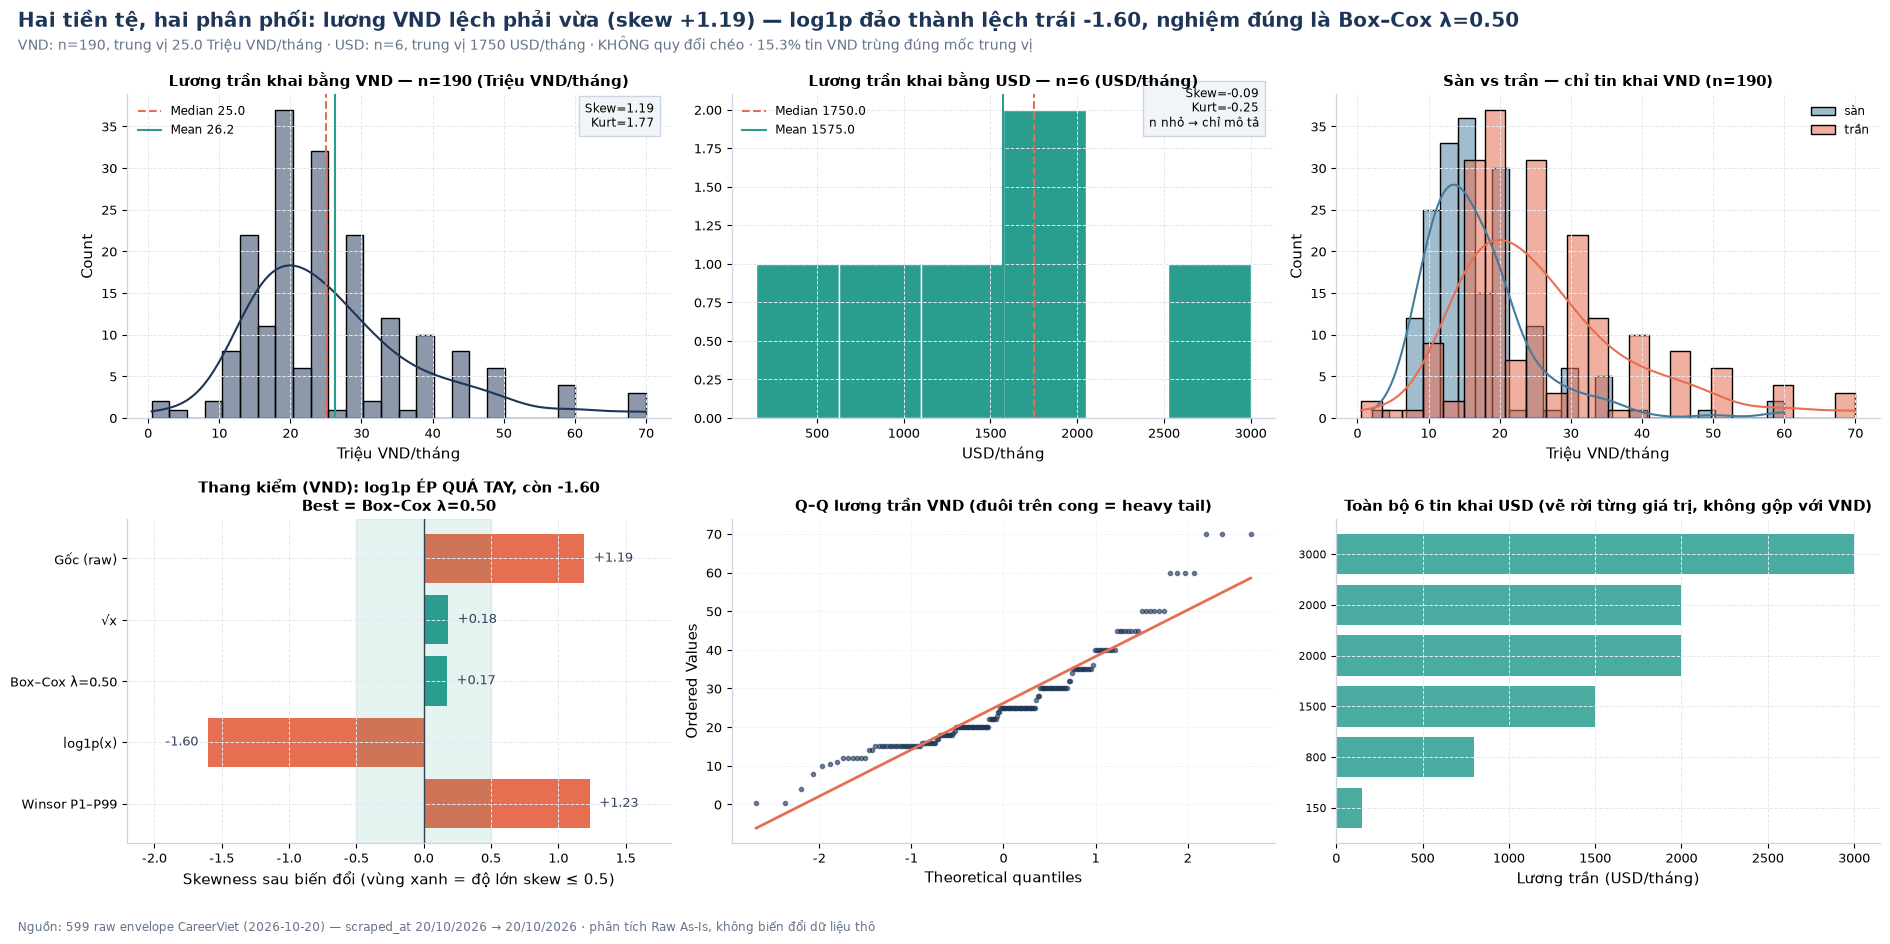

In [14]:
def transform_ladder(series):
    """Thang kiểm biến đổi trên MỘT chuỗi lương thuần nhất tiền tệ (không bao giờ gộp VND với USD).

    Trả về None khi n < MIN_N_DIST: với mẫu quá nhỏ, skew/Box–Cox là nhiễu chứ không phải kết luận.
    """
    s = series.dropna()
    s = s[s > 0]                                   # Box–Cox yêu cầu giá trị dương
    if len(s) < MIN_N_DIST:
        return None
    lam = float(stats.boxcox(s.to_numpy())[1])
    T = {"Gốc (raw)": s,
         "√x": pd.Series(np.sqrt(s.to_numpy()), index=s.index),
         f"Box–Cox λ={lam:.2f}": pd.Series(stats.boxcox(s.to_numpy())[0], index=s.index),
         "log1p(x)": pd.Series(np.log1p(s.to_numpy()), index=s.index),
         "Winsor P1–P99": s.clip(s.quantile(.01), s.quantile(.99))}
    sk = {k: float(v.skew()) for k, v in T.items()}
    best = min(sk, key=lambda k: abs(sk[k]))
    return {"s": s, "T": T, "skew": sk, "best": best, "lam": lam,
            "spike_pct": float((s == s.median()).mean() * 100),
            "p_norm": float(stats.normaltest(s).pvalue),
            "p_norm_best": float(stats.normaltest(T[best]).pvalue)}


LAD = {tag: transform_ladder(SAL_BY_CUR[tag]["tbl"]["max"]) for tag, _, _ in CUR_GROUPS}
usable = {t: v for t, v in LAD.items() if v is not None}
DOM_TAG = max(usable, key=lambda t: len(usable[t]["s"])) if usable else None
CUR_LABEL = {t: lbl for t, lbl, _ in CUR_GROUPS}
CUR_UNIT = {t: u for t, _, u in CUR_GROUPS}

# Các biến phục vụ diễn giải động (in ra tiêu đề/kết luận) — bám theo tiền tệ có mẫu lớn nhất
if DOM_TAG:
    sal_pub = LAD[DOM_TAG]["s"]
    TRANSFORMS, skews, best = LAD[DOM_TAG]["T"], LAD[DOM_TAG]["skew"], LAD[DOM_TAG]["best"]
    spike_pct = LAD[DOM_TAG]["spike_pct"]
    sk_raw, sk_log = skews["Gốc (raw)"], skews["log1p(x)"]
    log_helps = abs(sk_log) < abs(sk_raw)
    bc_key = next(k for k in TRANSFORMS if k.startswith("Box"))
    _sk_word = "cực mạnh" if abs(sk_raw) > 3 else ("mạnh" if abs(sk_raw) > 2 else ("vừa" if abs(sk_raw) > 1 else "nhẹ"))
    _log_verdict = (f"log1p đi đúng hướng nhưng chưa đủ (độ lớn skew {abs(sk_raw):.2f} → {abs(sk_log):.2f})" if log_helps
                    else f"log1p ÉP QUÁ TAY: độ lớn skew tăng từ {abs(sk_raw):.2f} lên {abs(sk_log):.2f} và đảo chiều "
                         f"(skew {sk_log:+.2f}) — phản bác hoàn toàn phản xạ 'thấy lương là ép log'")
else:
    sal_pub = pd.Series(dtype=float)
    TRANSFORMS, skews, best, spike_pct = {}, {}, "—", 0.0

fig, axes = plt.subplots(2, 3, figsize=(19, 9.4))

def _draw_hist(ax, tag):
    s = SAL_BY_CUR[tag]["tbl"]["max"].dropna()
    ax.set_title(f"Lương trần khai bằng {CUR_LABEL[tag]} — n={len(s)} ({CUR_UNIT[tag]})", fontsize=11)
    if s.empty:
        ax.axis("off"), ax.text(.5, .5, "Không có tin nào", ha="center"); return
    if len(s) >= 8:
        sns.histplot(s, kde=True, bins=min(28, max(6, len(s) // 4)), ax=ax, color=PALETTE[0 if tag == "vnd" else 1])
    else:
        ax.hist(s, bins=max(4, len(s)), color=PALETTE[1], edgecolor="white")
    ax.axvline(s.median(), color=C_WARN, ls="--", label=f"Median {s.median():.1f}")
    ax.axvline(s.mean(), color=C_OK, ls="-", label=f"Mean {s.mean():.1f}")
    ax.set_xlabel(CUR_UNIT[tag]), ax.legend(fontsize=8.5)
    ax.text(0.97, 0.9, f"Skew={s.skew():.2f}\nKurt={s.kurtosis():.2f}" + ("" if len(s) >= MIN_N_DIST else "\nn nhỏ → chỉ mô tả"),
            transform=ax.transAxes, ha="right", fontsize=8.5, bbox=dict(fc="#f1f5f9", ec="#cbd5e1"))


_draw_hist(axes[0, 0], "vnd")
_draw_hist(axes[0, 1], "usd")

ax = axes[0, 2]
_v = SAL_BY_CUR["vnd"]["tbl"]
sns.histplot(_v["min"].dropna(), kde=True, bins=24, ax=ax, color=PALETTE[4], label="sàn")
sns.histplot(_v["max"].dropna(), kde=True, bins=24, ax=ax, color=PALETTE[2], alpha=.55, label="trần")
ax.set_title(f"Sàn vs trần — chỉ tin khai VND (n={int(_v['max'].notna().sum())})", fontsize=11)
ax.set_xlabel(VND_UNIT), ax.legend(fontsize=8.5)

ax = axes[1, 0]
if DOM_TAG:
    names, vals = list(skews), [skews[k] for k in skews]
    ax.barh(range(len(names)), vals, color=[C_OK if abs(v) <= .5 else ("#e9c46a" if abs(v) <= 1 else C_WARN) for v in vals])
    ax.axvline(0, color="#334155", lw=1)
    ax.axvspan(-0.5, 0.5, color="#2a9d8f", alpha=.12)
    ax.set_yticks(range(len(names))), ax.set_yticklabels(names, fontsize=9.5)
    for i, v in enumerate(vals):
        ax.text(v + (0.07 if v >= 0 else -0.07), i, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=9, color="#334155")
    ax.invert_yaxis(), ax.set_xlabel("Skewness sau biến đổi (vùng xanh = độ lớn skew ≤ 0.5)")
    ax.set_xlim(min(vals) - .6, max(vals) + .6)   # chừa chỗ cho nhãn số liệu, tránh đè lên tên phép biến đổi
    ax.set_title(f"Thang kiểm ({CUR_LABEL[DOM_TAG]}): log1p {'đúng hướng nhưng' if log_helps else 'ÉP QUÁ TAY,'} còn {sk_log:+.2f}\nBest = {best}", fontsize=11)

ax = axes[1, 1]
if DOM_TAG:
    sm = sal_pub.sort_values().to_numpy()
    stats.probplot(sm, dist=stats.norm, plot=ax)
    ax.lines[0].set(marker="o", ms=3, alpha=.6, color=PALETTE[0]); ax.lines[1].set(color=C_WARN, lw=2)
    ax.set_title(f"Q–Q lương trần {CUR_LABEL[DOM_TAG]} (đuôi trên cong = heavy tail)", fontsize=11)
    ax.grid(True, ls="--", alpha=.5)

ax = axes[1, 2]
_u = SAL_BY_CUR["usd"]["tbl"]
if int(_u["max"].notna().sum()):
    ax.barh(range(len(_u["max"].dropna())), _u["max"].dropna().sort_values().values,
            color=PALETTE[1], alpha=.85)
    ax.set_yticks(range(len(_u["max"].dropna())))
    ax.set_yticklabels([f"{v:g}" for v in _u["max"].dropna().sort_values().values], fontsize=8)
    ax.set_xlabel(f"Lương trần ({USD_UNIT})")
    ax.set_title(f"Toàn bộ {int(_u['max'].notna().sum())} tin khai USD (vẽ rời từng giá trị, không gộp với VND)", fontsize=10.5)
else:
    ax.axis("off")
finalize(fig, f"Hai tiền tệ, hai phân phối: lương {CUR_LABEL[DOM_TAG]} lệch phải {_sk_word} (skew {sk_raw:+.2f}) — "
              f"log1p {'giảm còn ' + f'{sk_log:+.2f}' if log_helps else 'đảo thành lệch trái ' + f'{sk_log:+.2f}'}, nghiệm đúng là {best}",
         f"VND: n={int(SAL_BY_CUR['vnd']['tbl']['max'].notna().sum())}, trung vị {SAL_BY_CUR['vnd']['tbl']['max'].median():.1f} "
         f"{VND_UNIT} · USD: n={int(SAL_BY_CUR['usd']['tbl']['max'].notna().sum())}, trung vị "
         f"{SAL_BY_CUR['usd']['tbl']['max'].median():.0f} {USD_UNIT} · KHÔNG quy đổi chéo · "
         f"{spike_pct:.1f}% tin {CUR_LABEL[DOM_TAG]} trùng đúng mốc trung vị",
         "02_salary_distribution_skewness.png")

print("\nTự kiểm chuẩn — thang kiểm biến đổi RIÊNG cho từng tiền tệ:")
for tag, _, _ in CUR_GROUPS:
    lad = LAD[tag]
    if lad is None:
        n_ = int(SAL_BY_CUR[tag]["tbl"]["max"].notna().sum())
        print(f"   [{CUR_LABEL[tag]}] n={n_} < {MIN_N_DIST} → KHÔNG ước lượng skew/Box–Cox (chỉ liệt kê giá trị ở 3.2b).")
        continue
    print(f"   [{CUR_LABEL[tag]} · {CUR_UNIT[tag]}] n={len(lad['s'])}")
    for k in lad["T"]:
        note = "✅ gần đối xứng nhất" if k == lad["best"] else (
            "⚠️ độ lớn skew TĂNG so với gốc" if abs(lad["skew"][k]) > abs(lad["skew"]["Gốc (raw)"]) else "")
        print(f"      {k:<18} skew={lad['skew'][k]:+.2f} · kurt={lad['T'][k].kurtosis():+.2f}  {note}")
    _raw = lad["skew"]["Gốc (raw)"]
    print(f"      ⇒ lệch phải {'cực mạnh' if abs(_raw) > 3 else ('mạnh' if abs(_raw) > 2 else ('vừa' if abs(_raw) > 1 else 'nhẹ'))} "
          f"(skew {_raw:+.2f}, kurtosis {lad['T']['Gốc (raw)'].kurtosis():+.2f}); "
          f"{next(k for k in lad['T'] if k.startswith('Box'))} cho skew "
          f"{lad['skew'][next(k for k in lad['T'] if k.startswith('Box'))]:+.2f} là nghiệm tốt nhất.")
    print(f"      p bình thường (gốc) = {lad['p_norm']:.2e} → sau {lad['best']} = {lad['p_norm_best']:.2e}; "
          f"{lad['spike_pct']:.1f}% tin trùng đúng mốc {lad['s'].median():.1f} {CUR_UNIT[tag]} (đỉnh nhọn phi liên tục).")
if DOM_TAG:
    print(f"   ⇒ Diễn giải ở tiêu đề biểu đồ được lấy theo {CUR_LABEL[DOM_TAG]} vì đó là mẫu đủ lớn nhất "
          f"(n={len(sal_pub)}); các con số của tiền tệ còn lại nằm ở bảng in phía trên, không gộp chung.")
    print(f"   ℹ️  λ Box–Cox đo được cho {CUR_LABEL[DOM_TAG]} là {LAD[DOM_TAG]['lam']:.2f} — "
          + ("gần 0.5 nên bản chất nghiệm chính là căn bậc hai, không phải log."
             if abs(LAD[DOM_TAG]['lam'] - 0.5) < 0.15 else "chệch khá xa 0.5, không được quy về căn bậc hai.")
          + " Muốn so sánh với nguồn khác phải mở notebook tương ứng: hai notebook đo độc lập, "
            "không tham chiếu số liệu của nhau.")
    print(f"   ℹ️  'Đối xứng' ≠ 'phân phối chuẩn': kiểm định D'Agostino vẫn bác bỏ sau mọi phép biến đổi, "
          f"nên mọi so sánh giữa các nhóm phải dùng kiểm định hạng (Mann–Whitney/Kruskal–Wallis).")

### Đọc đồ thị 02 — HAI TIỀN TỆ, HAI PHÂN PHỐI: không một con số nào ở đây trộn đơn vị

**Bảng A — 190 tin khai lương bằng VND** (đơn vị hiển thị: Triệu VND/tháng).
Trung vị **25.0**, trung bình **26.22**, độ lệch chuẩn **12.54**; P25 18.0 · P75 30.0 · P95 50.0 · Max 70.0 · Min 0.5.
Mean > Median ⇒ có đuôi phải. **skew = +1.19, kurtosis = +1.77** → lệch phải mức *vừa*, không phải đuôi khổng lồ.
Hàng rào Tukey của riêng bảng này là `[0 ; 48]` Triệu VND/tháng ⇒ **13/190 tin ngoại lai (6.8%)**.

**Bảng B — 6 tin khai lương bằng USD** (đơn vị hiển thị: USD/tháng).
150 · 975 · **1.750** · 2.000 · 3.000 (Min · P25 · Trung vị · P75 · Max), trung bình 1.575, độ lệch chuẩn 1.003, skew −0.09.
Guard miền hợp lệ `50–20.000 USD/tháng`: **PASS**. Vì n = 6 < 30, bảng này **chỉ được mô tả, không được suy phân phối**
(không ước lượng skew/Box–Cox, không vẽ đường hồi quy) — đó là lý do panel (0,1) vẽ rời từng giá trị.

**Bảng A — thang kiểm biến đổi (panel 1,0).** Với mẫu của Bảng B, thang kiểm này *không được tính*:

| Phép biến đổi | Skewness | Kurtosis | Kết luận |
|:---|---:|---:|:---|
| Gốc (raw) | **+1.19** | +1.77 | Hình thái thật của dữ liệu, dùng làm mốc so sánh |
| √x | +0.18 | +1.45 | Gần đối xứng, dễ diễn giải |
| **Box–Cox λ = 0.50** | **+0.17** | +1.47 | ✅ nghiệm tốt nhất; λ ≈ 0.5 ⇒ bản chất chính là căn bậc hai |
| log1p(x) | **−1.60** | **+8.38** | ❌ ÉP QUÁ TAY: đảo sang lệch trái và kurtosis phồng gấp ~4.7 lần |
| Winsor P1–P99 | +1.23 | +1.78 | ❌ độ lớn skew TĂNG so với gốc — capping không chữa được lệch |

**Panel (0,2) sàn vs trần (chỉ Bảng A).** `sal_width_vnd` (n = 176): skew **+2.38**, kurtosis **+7.62**, Max **42.0** Triệu,
trung vị 7.0. Dải lương *mở rộng dần* khi lương tăng ⇒ `sal_width` phải là biến riêng, không được chỉ dùng trung điểm.

**Panel (1,1) Q–Q.** D'Agostino p = **7.26e-10** bác bỏ tính chuẩn trên dữ liệu gốc; sau Box–Cox vẫn là **1.04e-02**
(vẫn < 0.05, tức tiếp tục bị bác bỏ) ⇒ không tham số hoá; mọi so sánh nhóm phải dùng kiểm định hạng.

**Vì sao log1p thất bại ở CareerViet?** Hai nguyên nhân đều *nhìn thấy được* trên đồ thị:

1. skew gốc chỉ **+1.19** — liều log là quá mạnh so với bệnh;
2. **15.3% tin trùng đúng mốc 25.0** Triệu VND/tháng tạo một đỉnh nhọn rời rạc. Mọi phép biến đổi đơn điệu đều bảo toàn
đỉnh này, nên dữ liệu có thể *đối xứng* mà vẫn *không chuẩn*.

🔎 **Bài học kiểm soát chất lượng (đối chiếu mục 3.2b).** Chính notebook này từng nhân tỷ giá 25.400 VND/USD để gộp 6 tin
USD vào mẫu VND. Khi hằng số tỷ giá bị đặt sai **bậc độ lớn** (25.400.000 thay vì 25.400), lương dẫn xuất vọt lên
50.800 "Triệu" và skew đo được là **+7.24** (kurtosis +55.25) — một con số *trông rất "đúng kỳ vọng"* về dữ liệu lương nên
rất dễ bị chấp nhận mà không ai kiểm tra. Cách sửa *triệt để* không phải là chốt lại tỷ giá cho đúng, mà là **bỏ hẳn phép quy
đổi khỏi tầng EDA**: VND một bảng, USD một bảng, mỗi bảng một guard riêng (`0.5–1.000` Triệu và `50–20.000` USD).
Nhờ đó lỗi bậc độ lớn không còn đường để xảy ra, và ô nào muốn so sánh xuyên tiền tệ buộc phải đi qua tầng Integration —
nơi tỷ giá và ngày chốt tỷ giá là một **giả định được khai báo**, không phải một hằng số ẩn trong notebook.

── 5.3 Bảng đề xuất Winsorization (không drop dòng để bảo toàn tag kỹ năng) ──
── 5.4 Ngoại lai Tukey & phân tầng lương theo nhãn 'Cấp bậc' thô — TÁCH RIÊNG TỪNG TIỀN TỆ ──
   Cấp bậc trong toàn bộ 599 tin: {'Nhân viên': 485, 'Trưởng nhóm / Giám sát': 42, 'Quản lý': 37, '(không nhãn)': 13, 'Sinh viên/ Thực tập sinh': 12, 'Giám đốc': 6, 'Mới tốt nghiệp': 4}
   [VND] n=190 tin có lương · hàng rào IQR [0.0 ; 48.0] Triệu VND/tháng → 13 tin ngoại lai (6.8%)
      Kruskal–Wallis giữa 2 cấp bậc có n≥5: H=5.41, p=0.020
   [USD] n=6 tin có lương · hàng rào IQR [0.0 ; 3537.5] USD/tháng → 0 tin ngoại lai (0.0%)
🖼️  Đã lưu reports\figures\careerviet\03_salary_outliers_seniority.png (DPI 300)


,Biến,Capping dưới (P1),Capping trên (P99),Số giá trị sẽ bị cap,Tỷ lệ mẫu bị ảnh hưởng (%),Max thật
0,sal_min_vnd,7.40,52.10,4,0.7,60.0
1,sal_max_vnd,3.62,70.00,2,0.3,70.0
2,sal_mid_vnd,2.83,60.35,4,0.7,65.0
3,sal_width_vnd,1.00,40.00,2,0.3,42.0
4,sal_min_usd,136.00,1980.00,2,0.3,2000.0
5,sal_max_usd,182.50,2950.00,2,0.3,3000.0
6,sal_mid_usd,158.75,2462.50,2,0.3,2500.0
7,sal_width_usd,68.00,980.00,2,0.3,1000.0
8,exp_min,0.00,10.00,3,0.5,15.0
9,exp_max,0.00,15.00,3,0.5,25.0


,Số tin,Trung vị,P90,Max,Độ lệch
lvl,,,,,
Nhân viên,164,23.5,40.0,60.0,10.5
Trưởng nhóm / Giám sát,15,30.0,45.0,50.0,11.2
Quản lý,4,55.0,67.0,70.0,19.8
Sinh viên/ Thực tập sinh,3,0.5,3.3,4.0,2.0
Giám đốc,2,70.0,70.0,70.0,0.0
Mới tốt nghiệp,2,21.5,24.3,25.0,4.9


,Số tin,Trung vị,P90,Max,Độ lệch
lvl,,,,,
Nhân viên,4,1750.0,2000.0,2000.0,567.9
Quản lý,1,3000.0,3000.0,3000.0,NaN
Sinh viên/ Thực tập sinh,1,150.0,150.0,150.0,NaN


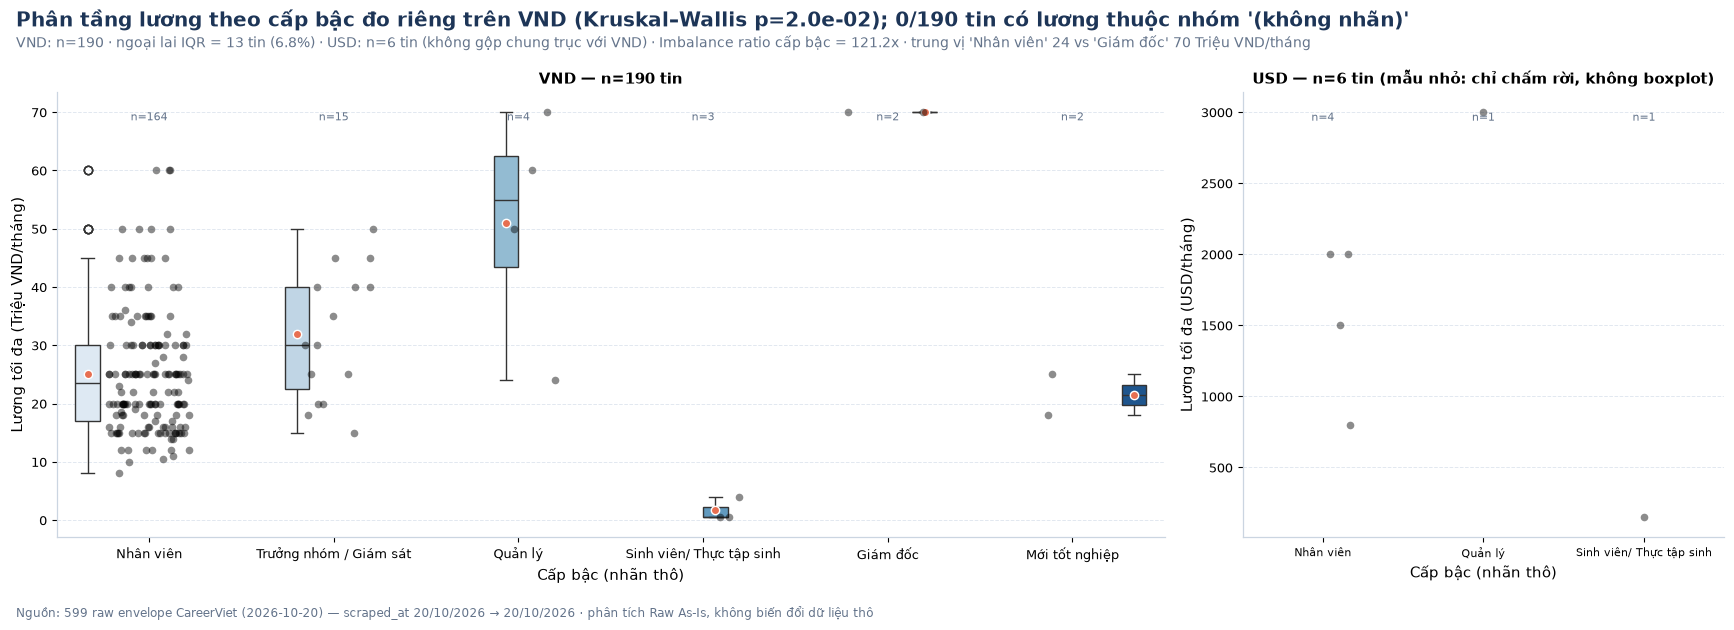

In [15]:
qv = feat[NUM_VARS].quantile([.01, .25, .5, .75, .99])
qv.index = ["P1", "P25", "P50", "P75", "P99"]
n_cap = {c: int(((pd.to_numeric(feat[c], errors="coerce") < qv.loc["P1", c])
                 | (pd.to_numeric(feat[c], errors="coerce") > qv.loc["P99", c])).sum()) for c in qv.columns}
wins = pd.DataFrame({
    "Biến": qv.columns,
    "Capping dưới (P1)": [round(qv.loc["P1", c], 2) for c in qv.columns],
    "Capping trên (P99)": [round(qv.loc["P99", c], 2) for c in qv.columns],
    "Số giá trị sẽ bị cap": [n_cap[c] for c in qv.columns],
    "Tỷ lệ mẫu bị ảnh hưởng (%)": [round(n_cap[c] / len(feat) * 100, 1) for c in qv.columns],
    "Max thật": [round(pd.to_numeric(feat[c], errors="coerce").max(), 2) for c in qv.columns],
})
print("── 5.3 Bảng đề xuất Winsorization (không drop dòng để bảo toàn tag kỹ năng) ──")
show(wins[(wins["Số giá trị sẽ bị cap"] > 0)].head(20))

fig, axes = plt.subplots(1, 2, figsize=(17.5, 6.2), gridspec_kw={"width_ratios": [2.3, 1]})
order = ["Nhân viên", "Trưởng nhóm / Giám sát", "Quản lý", "Sinh viên/ Thực tập sinh", "Giám đốc", "Mới tốt nghiệp", "(không nhãn)"]
print("── 5.4 Ngoại lai Tukey & phân tầng lương theo nhãn 'Cấp bậc' thô — TÁCH RIÊNG TỪNG TIỀN TỆ ──")
print(f"   Cấp bậc trong toàn bộ {len(df)} tin: {lvl_raw.value_counts().to_dict()}")
SEN = {}
for ax, (tag, cur_label, unit) in zip(axes, CUR_GROUPS):
    valid = df.assign(sal_max=feat[f"sal_max_{tag}"], lvl=lvl_raw).dropna(subset=["sal_max"])
    cats = [o for o in order if o in set(valid["lvl"])]
    valid["lvl"] = pd.Categorical(valid["lvl"], categories=cats, ordered=True)
    if valid.empty:
        SEN[tag] = {"valid": valid, "stat": pd.DataFrame(), "kw": None, "n_groups": 0,
                    "fence": (np.nan, np.nan), "n_out": 0}
        ax.axis("off")
        print(f"   [{cur_label}] không có tin nào khai lương bằng tiền tệ này.")
        continue
    s = valid["sal_max"]
    _q1s, _q3s = s.quantile([.25, .75])
    flo, fhi = _q1s - 1.5 * (_q3s - _q1s), _q3s + 1.5 * (_q3s - _q1s)
    n_out_c = int(((s < flo) | (s > fhi)).sum())
    stat = valid.groupby("lvl", observed=False)["sal_max"].agg(
        **{"Số tin": "size", "Trung vị": "median", "Max": "max", "Độ lệch": "std"})
    stat["P90"] = valid.groupby("lvl", observed=False)["sal_max"].quantile(.9)
    groups = [g["sal_max"].to_numpy() for _, g in valid.groupby("lvl", observed=True) if len(g) >= 5]
    kw = stats.kruskal(*groups) if len(groups) >= 2 else None
    SEN[tag] = {"valid": valid, "stat": stat, "kw": kw, "n_groups": len(groups),
                "fence": (flo, fhi), "n_out": n_out_c}
    print(f"   [{cur_label}] n={len(valid)} tin có lương · hàng rào IQR [{max(flo, 0):.1f} ; {fhi:.1f}] {unit} "
          f"→ {n_out_c} tin ngoại lai ({n_out_c/max(len(valid), 1)*100:.1f}%)")
    show(stat[["Số tin", "Trung vị", "P90", "Max", "Độ lệch"]].round(1))
    if kw is not None:
        print(f"      Kruskal–Wallis giữa {len(groups)} cấp bậc có n≥5: H={kw.statistic:.2f}, p={kw.pvalue:.3f}")
    if valid.empty:
        ax.axis("off"); continue
    if len(valid) >= MIN_N_DIST:
        sns.boxplot(data=valid, x="lvl", y="sal_max", hue="lvl", order=cats, palette="Blues",
                    showmeans=True, meanprops={"marker": "o", "markerfacecolor": C_WARN, "markeredgecolor": "white"},
                    legend=False, ax=ax)
    sns.stripplot(data=valid, x="lvl", y="sal_max", order=cats,
                  color="black", alpha=.45, jitter=.22, size=5.5, ax=ax)
    for i, lv in enumerate(cats):
        n_ = int((valid["lvl"] == lv).sum())
        if n_:
            ax.text(i, valid["sal_max"].max() * .98, f"n={n_}", ha="center", fontsize=8, color=C_MUTE)
    ax.set_xlabel("Cấp bậc (nhãn thô)")
    ax.set_ylabel(f"Lương tối đa ({unit})")
    ax.set_title(f"{cur_label} — n={len(valid)} tin" + ("" if len(valid) >= MIN_N_DIST else " (mẫu nhỏ: chỉ chấm rời, không boxplot)"),
                 fontsize=11)
    if len(valid) < MIN_N_DIST:
        ax.tick_params(axis="x", labelsize=8)
DOM = DOM_TAG or "vnd"
valid, lvl_stat, kw_sen = SEN[DOM]["valid"], SEN[DOM]["stat"], SEN[DOM]["kw"]
fence_lo, fence_hi = SEN[DOM]["fence"]
n_out = SEN[DOM]["n_out"]
n_sen_unlabeled = int(lvl_stat["Số tin"].get("(không nhãn)", 0))
_kw_txt = (f"Kruskal–Wallis p={kw_sen.pvalue:.1e}" if kw_sen is not None else "không đủ nhóm n≥5 để kiểm định")
finalize(fig, f"Phân tầng lương theo cấp bậc đo riêng trên {CUR_LABEL[DOM]} ({_kw_txt}); "
              f"{n_sen_unlabeled}/{len(valid)} tin có lương thuộc nhóm '(không nhãn)'",
         f"{CUR_LABEL[DOM]}: n={len(valid)} · ngoại lai IQR = {n_out} tin ({n_out/max(len(valid),1)*100:.1f}%) · "
         f"{CUR_LABEL['usd']}: n={len(SEN['usd']['valid'])} tin (không gộp chung trục với {CUR_LABEL[DOM]}) · "
         f"Imbalance ratio cấp bậc = {lvl_raw.value_counts().max()/max(lvl_raw.value_counts().min(),1):.1f}x · "
         f"trung vị 'Nhân viên' {lvl_stat['Trung vị'].get('Nhân viên', np.nan):.0f} vs 'Giám đốc' "
         f"{lvl_stat['Trung vị'].get('Giám đốc', np.nan):.0f} {CUR_UNIT[DOM]}",
         "03_salary_outliers_seniority.png")

🖼️  Đã lưu reports\figures\careerviet\11_experience_distribution.png (DPI 300)


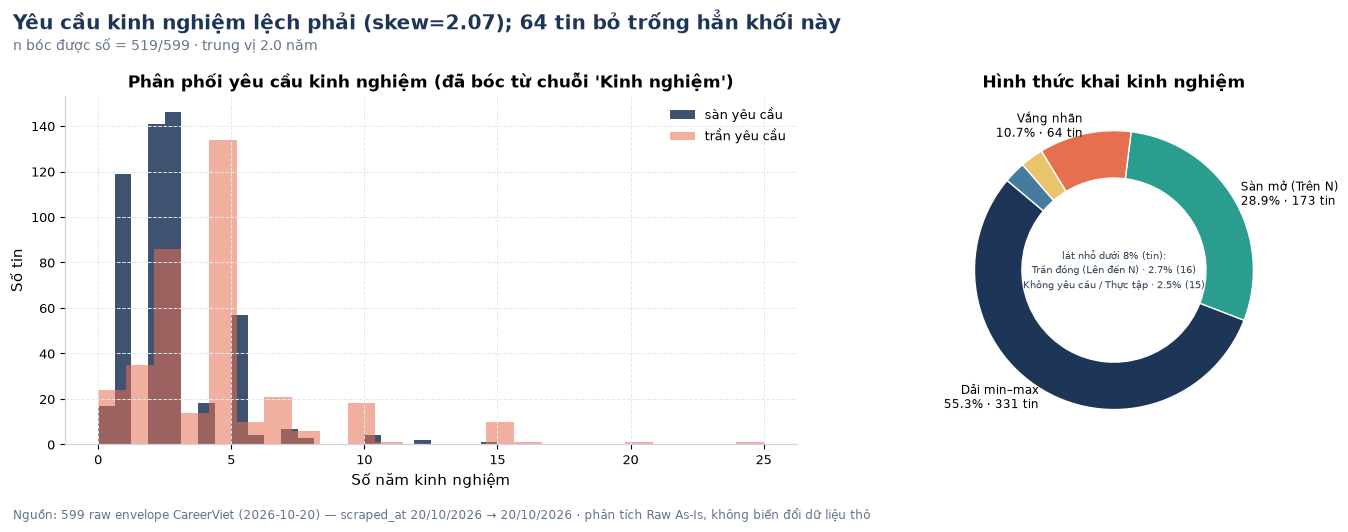

In [16]:
ek = feat_exp["exp_kind"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
axes[0].hist(feat["exp_min"].dropna(), bins=24, color=PALETTE[0], label="sàn yêu cầu", alpha=.85)
axes[0].hist(feat["exp_max"].dropna(), bins=24, color=PALETTE[2], label="trần yêu cầu", alpha=.55)
axes[0].set_xlabel("Số năm kinh nghiệm"), axes[0].set_ylabel("Số tin")
axes[0].set_title("Phân phối yêu cầu kinh nghiệm (đã bóc từ chuỗi 'Kinh nghiệm')")
axes[0].legend()
donut(axes[1], ek.values, ek.index, PALETTE, unit="tin")
axes[1].set_title("Hình thức khai kinh nghiệm")
finalize(fig, f"Yêu cầu kinh nghiệm lệch phải (skew={feat['exp_min'].skew():.2f}); "
              f"{int(ek.get('Vắng nhãn', 0))} tin bỏ trống hẳn khối này",
         f"n bóc được số = {int(feat['exp_min'].notna().sum())}/{len(df)} · trung vị {feat['exp_min'].median():.1f} năm",
         "11_experience_distribution.png")

── 5.4b Độ dài & nhiễu văn bản JD (rác ký tự trước pipeline trích xuất kỹ năng) ──
⚠️  Chuỗi JD lặp lại chính nhãn của nó ở đầu chuỗi (label echo): 598/599 tin → cần cắt prefix ở bước Integration.
🖼️  Đã lưu reports\figures\careerviet\12_jd_text_length.png (DPI 300)


,bullets,html,newlines,double_space,label_echo
count,598.0,598.0,598.0,598.0,598.0
mean,0.0,0.0,0.0,0.0,1.0
std,0.0,0.0,0.0,0.0,0.0
min,0.0,0.0,0.0,0.0,1.0
25%,0.0,0.0,0.0,0.0,1.0
50%,0.0,0.0,0.0,0.0,1.0
75%,0.0,0.0,0.0,0.0,1.0
max,0.0,0.0,0.0,0.0,1.0


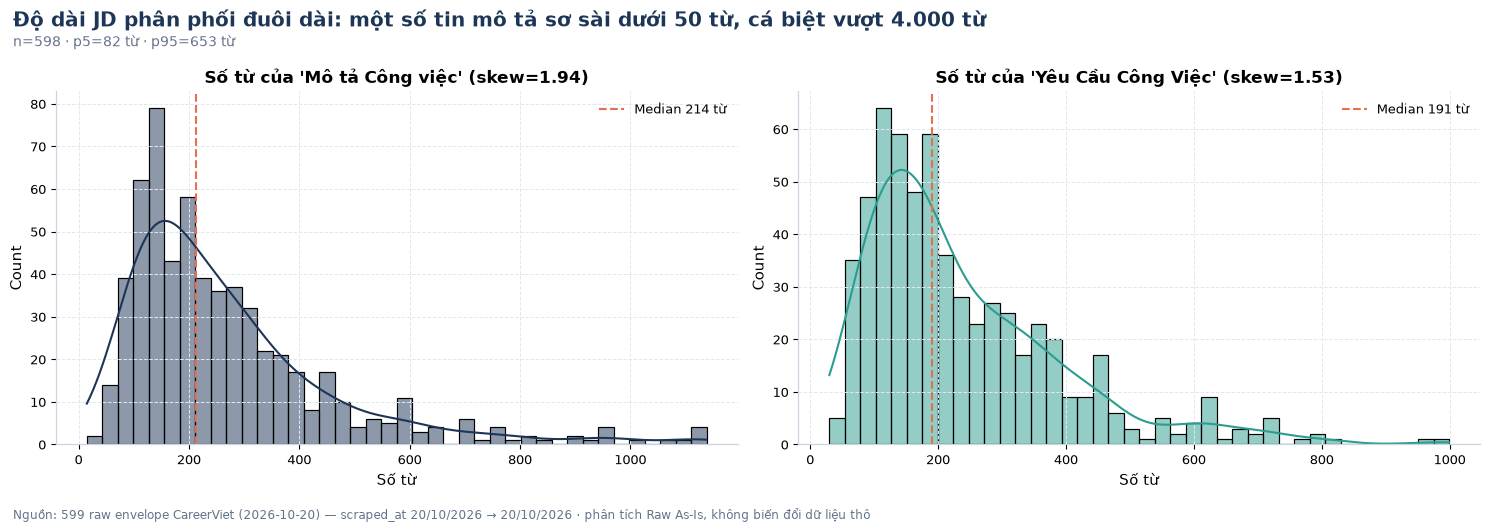

In [17]:
print("── 5.4b Độ dài & nhiễu văn bản JD (rác ký tự trước pipeline trích xuất kỹ năng) ──")
def text_noise(s):
    if not isinstance(s, str):
        return {}
    return {"bullets": len(re.findall(r"(?m)^\s*[-•·●–]\s", s)),
            "html": len(re.findall(r"<[^>]+>", s)),
            "newlines": s.count("\n"),
            "double_space": len(re.findall(r"\s{3,}", s)),
            "label_echo": int(s.strip().startswith(("Mô tả Công việc", "Yêu Cầu Công Việc", "Địa điểm làm việc", "Thông tin khác", "Phúc lợi")))}
noise = df[text_cols["jd_desc"]].map(text_noise)
noise_df = pd.DataFrame(noise.tolist(), index=df.index)
show(noise_df.describe().round(2))
print(f"⚠️  Chuỗi JD lặp lại chính nhãn của nó ở đầu chuỗi (label echo): "
      f"{int(noise_df['label_echo'].sum())}/{len(df)} tin → cần cắt prefix ở bước Integration.")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, col, ttl, pal in [(axes[0], "jd_desc_words", "Số từ của 'Mô tả Công việc'", PALETTE[0]),
                          (axes[1], "jd_req_words", "Số từ của 'Yêu Cầu Công Việc'", PALETTE[1])]:
    v = feat[col].dropna()
    sns.histplot(v, bins=40, kde=True, color=pal, ax=ax)
    ax.axvline(v.median(), color=C_WARN, ls="--", label=f"Median {v.median():.0f} từ")
    ax.set_xlabel("Số từ"), ax.legend(), ax.set_title(ttl + f" (skew={v.skew():.2f})")
finalize(fig, "Độ dài JD phân phối đuôi dài: một số tin mô tả sơ sài dưới 50 từ, cá biệt vượt 4.000 từ",
         f"n={int(feat['jd_desc_words'].notna().sum())} · p5={feat['jd_desc_words'].quantile(.05):.0f} từ · "
         f"p95={feat['jd_desc_words'].quantile(.95):.0f} từ", "12_jd_text_length.png")

### 5.5 Mối quan hệ đơn biến hỗ trợ quyết định tiền xử lý

Cặp **kinh nghiệm ↔ lương** và **số thẻ kỹ năng ↔ lương** là hai quan hệ quyết định chất lượng feature cho mô hình
hồi quy/phân lớp ở bước sau. Dùng **Spearman** vì cả hai biến đều lệch phải và có ngoại lai.

⚠️ Mỗi hệ số chỉ được tính **trong một tiền tệ**. Ghộp vài tin USD vào mẫu VND (dù đã nhân tỷ giá) sẽ tạo ra một biến
phụ mang hai thang đo và làm ρ mất nghĩa; vì vậy đồ thị 04 vẽ **hai panel — hai bảng riêng**, và bảng nào không đủ
n ≥ 30 thì chỉ liệt kê giá trị thô, không ước lượng.

── 5.5 Quan hệ đơn biến với lương trần — MẪU TÁCH RIÊNG TỪNG TIỀN TỆ ──
   Lý do: một giá trị USD không đứng chung thang đo với một giá trị VND, nên mỗi hệ số dưới đây chỉ dùng đúng các tin khai bằng tiền tệ đang xét. Không có phép tính nào trộn hai tiền tệ.

   ▐ BẢNG A — chỉ tin khai VND (Triệu VND/tháng); n cặp kinh nghiệm↔lương = 167
      exp_min            ρ=+0.511 (p=1.79e-12, n=167)
      n_tags             ρ=-0.033 (p=6.53e-01, n=190)   ← KHÔNG có ý nghĩa thống kê (p ≥ 0.05)
      jd_desc_words      ρ=+0.151 (p=3.82e-02, n=190)
      days_since_update  ρ=+0.009 (p=8.99e-01, n=190)   ← KHÔNG có ý nghĩa thống kê (p ≥ 0.05)
      đối chiếu Pearson cùng cặp exp_min↔lương: r=+0.351 → Spearman ≥ Pearson: quan hệ mang tính bậc thang, không phải đường thẳng
      R² hạng của kinh nghiệm = 0.261 → phần lớn phương sai lương nằm NGOÀI biến này

   ▐ BẢNG B — chỉ tin khai USD (USD/tháng); n cặp kinh nghiệm↔lương = 5
      n = 5 < 30 → KHÔNG tính ρ và KHÔNG vẽ đường hồi quy (ở mẫu này mọi 

,exp_min,sal
0,5.0,800.0
1,2.0,2000.0
2,2.0,2000.0
3,5.0,3000.0
4,3.0,1500.0


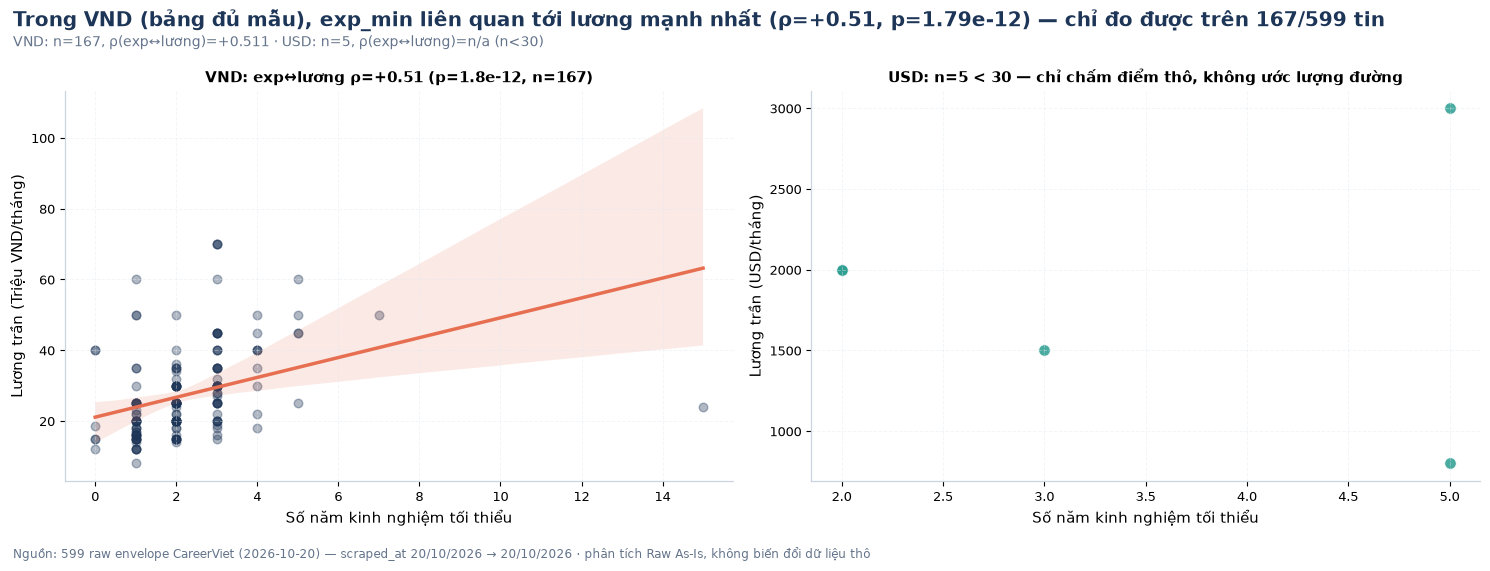

In [18]:
def _rho(v, fmt="+.3f"):
    return format(v, fmt) if pd.notna(v) else "n/a"


AUX_VARS = ["exp_min", "n_tags", "jd_desc_words", "days_since_update"]
REL = {}
print("── 5.5 Quan hệ đơn biến với lương trần — MẪU TÁCH RIÊNG TỪNG TIỀN TỆ ──")
print("   Lý do: một giá trị USD không đứng chung thang đo với một giá trị VND, nên mỗi hệ số dưới đây"
      " chỉ dùng đúng các tin khai bằng tiền tệ đang xét. Không có phép tính nào trộn hai tiền tệ.")
for tag, cur_label, unit in CUR_GROUPS:
    sal_c = feat[f"sal_max_{tag}"]
    pair = pd.DataFrame({"exp_min": feat["exp_min"], "sal": sal_c}).dropna()
    aux = {}
    for c in AUX_VARS:
        _pp = pd.DataFrame({"x": feat[c], "sal": sal_c}).dropna()
        aux[c] = (stats.spearmanr(_pp["x"], _pp["sal"]), len(_pp))
    ok = len(pair) >= MIN_N_DIST
    pear = None
    if ok:
        pear = stats.pearsonr(pair["exp_min"], pair["sal"])
    REL[tag] = {"pair": pair, "aux": aux, "pear": pear, "ok": ok, "n": len(pair)}
    print(f"\n   ▐ BẢNG {'A' if tag == 'vnd' else 'B'} — chỉ tin khai {cur_label} ({unit}); "
          f"n cặp kinh nghiệm↔lương = {len(pair)}")
    if not ok:
        print(f"      n = {len(pair)} < {MIN_N_DIST} → KHÔNG tính ρ và KHÔNG vẽ đường hồi quy "
              f"(ở mẫu này mọi hệ số đều là nhiễu). Liệt kê toàn bộ giá trị thô:")
        show(pair.reset_index(drop=True)) if len(pair) else print("        (trống)")
        continue
    for c in AUX_VARS:
        r_, n_ = aux[c]
        print(f"      {c:<18} ρ={r_.statistic:+.3f} (p={r_.pvalue:.2e}, n={n_})"
              + ("   ← KHÔNG có ý nghĩa thống kê (p ≥ 0.05)" if r_.pvalue >= .05 else ""))
    _r0 = aux["exp_min"][0]
    print(f"      đối chiếu Pearson cùng cặp exp_min↔lương: r={pear.statistic:+.3f} → "
          + ("|Pearson| > |Spearman|: đuôi dài đang thổi phồng hệ số tuyến tính, phải dùng hạng"
             if abs(pear.statistic) > abs(_r0.statistic) else
             "Spearman ≥ Pearson: quan hệ mang tính bậc thang, không phải đường thẳng"))
    print(f"      R² hạng của kinh nghiệm = {_r0.statistic**2:.3f} → phần lớn phương sai lương nằm NGOÀI biến này")

DOMR = DOM_TAG or "vnd"
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, (tag, cur_label, unit) in zip(axes, CUR_GROUPS):
    d, p = REL[tag], REL[tag]["pair"]
    if p.empty:
        ax.axis("off"), ax.set_title(f"{cur_label}: không có cặp kinh nghiệm↔lương nào")
        continue
    if d["ok"]:
        sns.regplot(data=p, x="exp_min", y="sal",
                    scatter_kws={"alpha": .35, "color": PALETTE[0 if tag == "vnd" else 1], "s": 38},
                    line_kws={"color": C_WARN, "lw": 2.5}, ax=ax)
        _r = d["aux"]["exp_min"][0]
        ax.set_title(f"{cur_label}: exp↔lương ρ={_r.statistic:+.2f} (p={_r.pvalue:.1e}, n={len(p)})", fontsize=11)
    else:
        sns.scatterplot(data=p, x="exp_min", y="sal", s=70, alpha=.85, color=PALETTE[1], ax=ax)
        ax.set_title(f"{cur_label}: n={len(p)} < {MIN_N_DIST} — chỉ chấm điểm thô, không ước lượng đường",
                     fontsize=11)
    ax.set_xlabel("Số năm kinh nghiệm tối thiểu"), ax.set_ylabel(f"Lương trần ({unit})")
    ax.grid(True, ls="--", alpha=.4)
if REL[DOMR]["ok"]:
    _top = max(AUX_VARS, key=lambda c: abs(REL[DOMR]["aux"][c][0].statistic))
    _tval = REL[DOMR]["aux"][_top][0]
    _head = (f"Trong {CUR_LABEL[DOMR]} (bảng đủ mẫu), {_top} liên quan tới lương mạnh nhất "
             f"(ρ={_tval.statistic:+.2f}, p={_tval.pvalue:.2e}) — chỉ đo được trên {REL[DOMR]['n']}/{len(df)} tin")
else:
    _head = f"Không tiền tệ nào đạt n ≥ {MIN_N_DIST} để ước lượng quan hệ kinh nghiệm↔lương"
finalize(fig, _head,
         " · ".join(f"{cur_label}: n={REL[tag]['n']}, ρ(exp↔lương)="
                    + (_rho(REL[tag]["aux"]["exp_min"][0].statistic) if REL[tag]["ok"] else f"n/a (n<{MIN_N_DIST})")
                    for tag, cur_label, _ in CUR_GROUPS),
         "04_experience_vs_salary_relation.png")

🖼️  Đã lưu reports\figures\careerviet\05_spearman_correlation_matrix.png (DPI 300)

Tự kiểm — khoảng cách Spearman vs Pearson trong TỪNG bảng:
   [VND] chênh lệch lớn nhất 0.210 giữa cặp (exp_min ↔ sal_min (VND)) → xác nhận đuôi dài làm lệch hệ số tuyến tính (chọn Spearman làm chuẩn feature screening).
   [VND] Hạng Spearman của lương trần với từng biến (mẫu = cặp đầy đủ của bảng này):
      sal_min_vnd            ρ=+0.833  (n=176)
      sal_mid_vnd            ρ=+0.978  (n=190)
      sal_width_vnd          ρ=+0.822  (n=176)
      exp_min                ρ=+0.511  (n=167)
      exp_mid                ρ=+0.458  (n=174)
      n_tags                 ρ=-0.033  (n=190)
      n_industry             ρ=-0.136  (n=190)
      jd_desc_words          ρ=+0.151  (n=190)
      n_benefit_cats         ρ=+0.043  (n=190)
      days_since_update      ρ=+0.009  (n=190)
      env_kb                 ρ=+0.258  (n=190)
   [USD] n = 4 < 30 → bỏ qua so sánh hệ số ở bảng này.


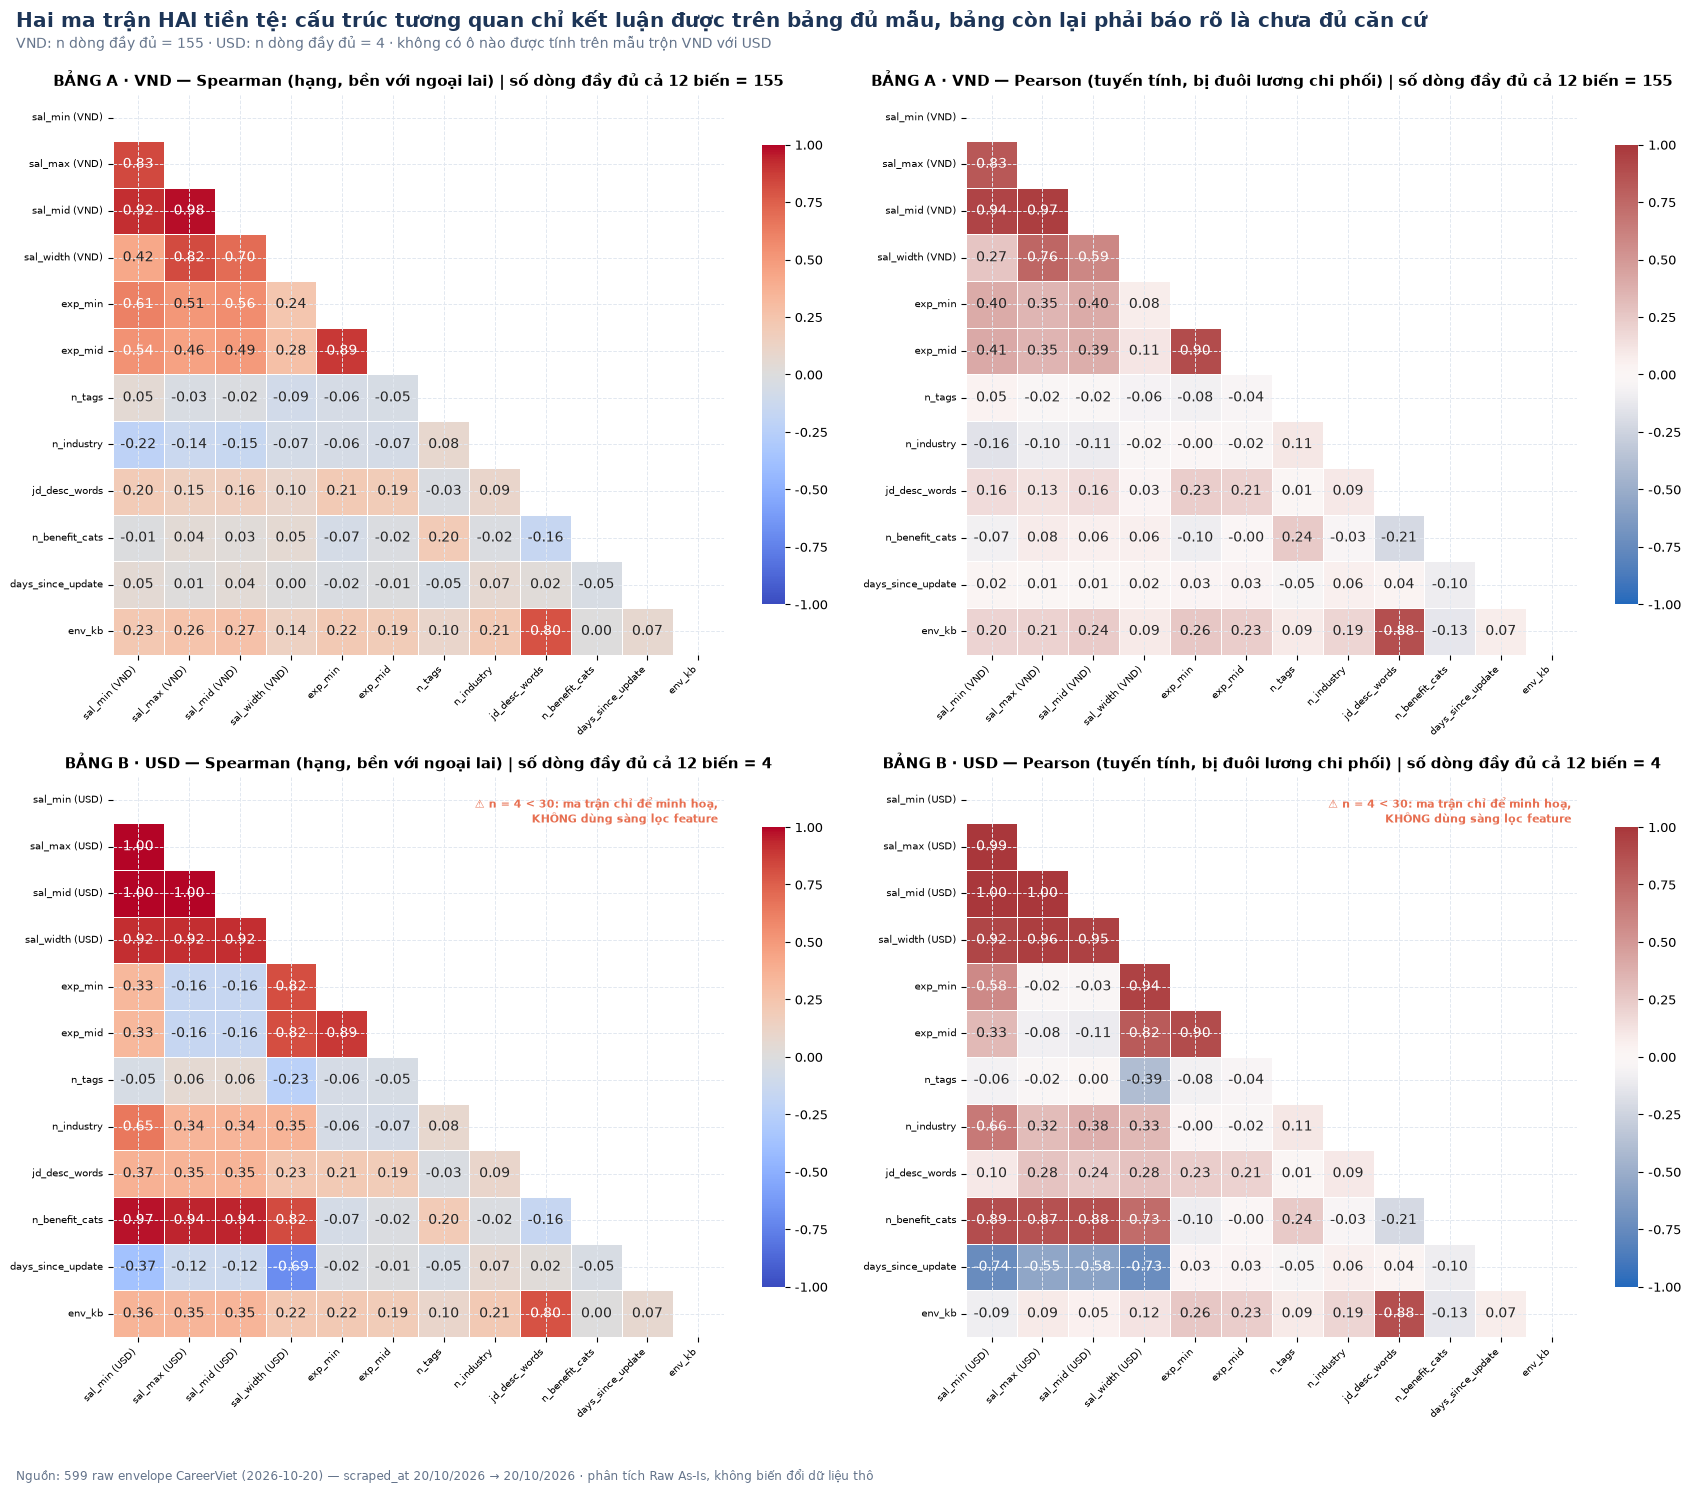

In [19]:
CORR_BASE = ["sal_min", "sal_max", "sal_mid", "sal_width", "exp_min", "exp_mid", "n_tags", "n_industry",
             "jd_desc_words", "n_benefit_cats", "days_since_update", "env_kb"]
CORR = {}
for tag, cur_label, unit in CUR_GROUPS:
    cols = [f"{v}_{tag}" if v.startswith("sal_") else v for v in CORR_BASE]
    labs = [f"{v[:-(len(tag) + 1)]} ({cur_label})" if v.startswith("sal_") else v for v in cols]
    frame = feat[cols]
    sp, pe = frame.corr(method="spearman"), frame.corr(method="pearson")
    CORR[tag] = {"cols": cols, "labs": labs, "frame": frame, "sp": sp, "pe": pe,
                 "n_full": int(frame.dropna().shape[0]),
                 "ok": int(frame.dropna().shape[0]) >= MIN_N_DIST}

fig, axes = plt.subplots(2, 2, figsize=(17.5, 15))
for row, (tag, cur_label, unit) in enumerate(CUR_GROUPS):
    d = CORR[tag]
    k = len(d["cols"])
    mask = np.triu(np.ones((k, k), dtype=bool))
    for col, (meth, mtx, cmap) in enumerate([("Spearman (hạng, bền với ngoại lai)", d["sp"], "coolwarm"),
                                             ("Pearson (tuyến tính, bị đuôi lương chi phối)", d["pe"], "vlag")]):
        ax = axes[row, col]
        sns.heatmap(mtx, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, linewidths=.6, ax=ax,
                    mask=mask, cbar_kws={"shrink": .82}, xticklabels=d["labs"], yticklabels=d["labs"])
        ax.set_title(f"BẢNG {'A' if tag == 'vnd' else 'B'} · {cur_label} — {meth} | "
                     f"số dòng đầy đủ cả 12 biến = {d['n_full']}", fontsize=11)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=7.5)
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=7.5)
        if not d["ok"]:
            # Cảnh báo nhét VÀO TAM GIÁC TRÊN ĐÃ BỊ MASK (vùng chắc chắn trống) thay vì đặt dưới trục X:
            # để ở -0.10 như bản cũ thì nó đè thẳng lên hàng nhãn định lượng đang xoay 45 độ của chính bảng.
            ax.text(.99, .965, f"⚠️ n = {d['n_full']} < {MIN_N_DIST}: ma trận chỉ để minh hoạ,\n"
                              f"KHÔNG dùng sàng lọc feature", transform=ax.transAxes, ha="right",
                    va="top", fontsize=8, color=C_WARN, fontweight="bold")
finalize(fig, "Hai ma trận HAI tiền tệ: cấu trúc tương quan chỉ kết luận được trên bảng đủ mẫu, "
              "bảng còn lại phải báo rõ là chưa đủ căn cứ",
         " · ".join(f"{CUR_LABEL[tag]}: n dòng đầy đủ = {CORR[tag]['n_full']}" for tag, _, _ in CUR_GROUPS)
         + " · không có ô nào được tính trên mẫu trộn VND với USD",
         "05_spearman_correlation_matrix.png")

print("\nTự kiểm — khoảng cách Spearman vs Pearson trong TỪNG bảng:")
for tag, cur_label, unit in CUR_GROUPS:
    d = CORR[tag]
    if not d["ok"]:
        print(f"   [{cur_label}] n = {d['n_full']} < {MIN_N_DIST} → bỏ qua so sánh hệ số ở bảng này.")
        continue
    diff = (d["sp"] - d["pe"]).abs().to_numpy()
    masked = np.where(np.triu(np.ones(diff.shape, dtype=bool)), np.nan, diff)
    if np.all(np.isnan(masked)):
        print(f"   [{cur_label}] không có cặp biến nào đủ dữ liệu để so sánh.")
        continue
    i, j = np.unravel_index(np.nanargmax(masked), masked.shape)
    print(f"   [{cur_label}] chênh lệch lớn nhất {masked[i, j]:.3f} giữa cặp "
          f"({d['labs'][i]} ↔ {d['labs'][j]}) → xác nhận đuôi dài làm lệch hệ số tuyến tính "
          f"(chọn Spearman làm chuẩn feature screening).")
    _sal_col = f"sal_max_{tag}"
    print(f"   [{cur_label}] Hạng Spearman của lương trần với từng biến (mẫu = cặp đầy đủ của bảng này):")
    for c in d["cols"]:
        if c == _sal_col:
            continue
        _p = d["frame"][[_sal_col, c]].dropna()
        if len(_p) < 3:
            print(f"      {c:<22} n={len(_p)} → quá nhỏ, không tính")
            continue
        print(f"      {c:<22} ρ={stats.spearmanr(_p[_sal_col], _p[c]).statistic:+.3f}  (n={len(_p)})")

### Đọc đồ thị 03–05 — hai tiền tệ, hai bộ kết luận: cấp bậc phân tầng lương rõ, còn kỹ năng thì không

**Đồ thị 03 (ngoại lai + cấp bậc) — 1×2, mỗi panel một tiền tệ.**

- **Bảng A (VND, n = 190):** hàng rào Tukey `[0 ; 48]` Triệu VND/tháng ⇒ **13/190 tin ngoại lai (6.8%)** — một tỷ lệ
  *rất thấp* so với mặc định "dữ liệu lương toàn ngoại lai". Bậc thang trung vị hoàn toàn **đơn điệu theo cấp bậc**:
  Sinh viên/Thực tập sinh **0.5** → Mới tốt nghiệp **21.5** → Nhân viên **23.5** → Trưởng nhóm **30.0** → Quản lý **55.0**
  → Giám đốc **70.0** (Triệu VND/tháng). Kruskal–Wallis chỉ chạy được trên **2 cấp bậc có n ≥ 5** (Nhân viên 164 tin,
  Trưởng nhóm 15 tin): **H = 5.41, p = 0.020** ⇒ nhãn "Cấp bậc" *có* mang thông tin kinh tế thật, nhưng khoảng tin cậy
  ở các bậc cao gần như vô nghĩa (Quản lý 4 tin, Giám đốc 2 tin, Mới tốt nghiệp 2 tin).
- **Bảng B (USD, n = 6):** hàng rào `[0 ; 3537.5]` USD/tháng ⇒ **0 ngoại lai**, nhưng phân bố cấp bậc chỉ còn
  Nhân viên 4 tin · Quản lý 1 · Sinh viên/Thực tập sinh 1 ⇒ **không kiểm định**, mọi so sánh "bậc nào lương cao hơn"
  ở bảng này là suy diễn từ nhiễu. Đây là điều buộc phải nói tách bạch: trước khi tách tiền tệ, 6 tin USD bị nhét vào
  chung một boxplot với 190 tin VND và trông như "ngoại lai hợp lệ".
- 13 tin mang nhãn cấp bậc `(không nhãn)` **không xuất hiện ở cả hai bảng** ⇒ chúng trùng hẳn với nhóm ẩn lương:
  thiếu cấp bậc và thiếu lương đi cùng nhau gần như tuyệt đối, dấu hiệu **MNAR** chứ không phải MCAR.

**Đồ thị 04 (quan hệ đơn biến).**
- **Bảng A (n = 167 cặp kinh nghiệm↔lương):** kinh nghiệm là biến mạnh nhất, **ρ = +0.511 (p = 1.79e-12)** nhưng R² hạng
  chỉ **0.261** ⇒ 3/4 phương sai hạng của lương nằm *ngoài* biến này. Pearson cùng cặp chỉ **+0.351 < Spearman** ⇒ quan hệ
  mang tính **bậc thang**, không phải đường thẳng. Ba biến còn lại: số thẻ kỹ năng **ρ = −0.033 (p = 0.653)**, tuổi tin
  **ρ = +0.009 (p = 0.899)** — cả hai *không có ý nghĩa thống kê*; độ dài phần mô tả **ρ = +0.151 (p = 0.038)** có ý nghĩa
  nhưng quá nhỏ để dùng làm feature. Phát hiện quan trọng nhất mang tính *phủ định*: **số lượng thẻ kỹ năng KHÔNG phải
  chỉ báo của lương** ở CareerViet ⇒ không được đưa `n_tags` vào mô hình hồi quy lương như một feature mạnh.
- **Bảng B (n = 5):** dưới ngưỡng 30 ⇒ notebook **từ chối tính ρ** và chỉ in ra 5 điểm thô (800 / 1.500 / 2.000 / 2.000 / 3.000 USD).

**Đồ thị 05 (ma trận tương quan) — 2×2, mỗi tiền tệ một ma trận Spearman + Pearson.**
- **Bảng A:** cặp lệch nhau nhất giữa hai hệ số là **exp_min ↔ sal_min (VND), cách biệt 0.210** ⇒ phần lớn thông tin nằm ở
  *trật tự hạng* chứ không ở độ lớn tuyệt đối, nên feature screening phải dùng Spearman.
- Bảng ρ của lương trần (VND) với từng biến, đúng thứ tự mạnh dần: `sal_mid_vnd` **+0.978** (n=190), `sal_min_vnd` **+0.833**
  (n=176), `sal_width_vnd` **+0.822** (n=176) — ba biến này là **hàm của nhau, không được đưa cả ba vào mô hình**
  (đa cộng tuyến gần hoàn hảo) — rồi `exp_min` +0.511 (n=167), `exp_mid` +0.458 (n=174), `env_kb` +0.258,
  `jd_desc_words` +0.151, `n_benefit_cats` +0.043, `days_since_update` +0.009, `n_tags` −0.033, `n_industry` −0.136.
- **Bảng B:** chỉ **4/599 dòng đầy đủ cả 12 biến** ⇒ ma trận được vẽ kèm cảnh báo *"chỉ để minh hoạ, KHÔNG dùng sàng lọc
  feature"*. Một notebook gộp mẫu sẽ âm thầm xuất ra ma trận 12×12 *trông có vẻ* đầy đủ từ đúng 4 quan sát — đó là kiểu
  lỗi mà việc tách bảng chặn lại ngay tại chỗ.

✅ **Tính nhất quán đã khôi phục:** ρ của `exp_min` ở đồ thị 04 và ở bảng liệt kê đồ thị 05 giờ **trùng khớp tuyệt đối
(+0.511, n = 167)** vì cả hai đều tính trên cùng một mẫu Bảng A. Trước khi tách tiền tệ, hai chỗ này cho hai số khác nhau
(+0.477 với n = 159 và +0.504 với n = 172) do hai tập mẫu ngầm định khác nhau — minh chứng cho thấy việc *không khai báo
mẫu* là nguồn số liệu không tái lập được.

## Bước 6 — Trụ cột 5: Hồ sơ đơn biến các biến phân loại & đo độ mất cân bằng

Mỗi trường phân loại của CareerViet được đo các chỉ báo: **số nhãn**, **nhãn leading + tỷ lệ**, **cumulative
top-3**, **entropy chuẩn hoá** (0 = dồn một nhãn, 1 = trải đều), **Imbalance Ratio** (max/min) và số nhãn
hiếm. Hai chỉ số `Tin có giá trị` (số tin có ít nhất một nhãn thật) và `Số lượt giá trị` (tổng lượt sau khi
tách mảng) được đo tách riêng vì các trường đa nhãn (Hình thức, Tỉnh/TP, Ngành nghề) cho phép *nhiều lượt
trên một tin* ⇒ nếu chỉ lấy lượt chia cho số tin, tỷ lệ phủ sẽ vượt 100% và so sánh giữa các trường sẽ sai.
Đây là căn cứ trực tiếp để quyết định *gộp nhãn hiếm → "Other"*, *class weighting* hay *resampling*
ở bước Integration.

In [20]:
def split_multi(series, sep=" , "):
    return series.map(lambda v: [x.strip() for x in str(v).split(sep) if x.strip()] if pd.notna(v) else [])

def _vals(series):
    """Chuẩn hoá một cột phân loại (bỏ NaN/chuỗi rỗng) rồi đếm tần suất."""
    s = series.dropna().astype(str)
    return s[s.str.strip() != ""].value_counts()


_lvl_s = lvl_raw.astype(str)
_form_s = form_series.astype(str)
_form_tok = pd.Series(split_multi(_form_s.replace("(không nhãn)", "")).explode())
_prov_tok = split_multi(df["map"].fillna("").astype(str), sep=",").explode()
_ind_tok = split_multi(ind_series).explode()
_bygd = packed_df.get("Bằng cấp", pd.Series(index=df.index, dtype=object)).astype("string").str.strip()
_gioit = packed_df.get("Giới tính", pd.Series(index=df.index, dtype=object)).astype("string").str.strip()
_itflag = pd.Series(np.where(is_it, "Có dấu hiệu IT", "Không có dấu hiệu IT"), index=df.index)

cat_sources = [
    ("Cấp bậc (detail-box)", _lvl_s, int((_lvl_s.str.strip() != "(không nhãn)").sum())),
    ("Hình thức (detail-box)", _form_s, int((_form_s.str.strip() != "(không nhãn)").sum())),
    ("Hình thức sau tách ' , '", _form_tok, int(_form_tok.dropna().index.nunique())),
    ("Tỉnh/TP (map)", _prov_tok, int(_prov_tok.dropna().index.nunique())),
    ("Ngành nghề (sau tách)", _ind_tok, int(_ind_tok.dropna().index.nunique())),
    ("Bằng cấp (Thông tin khác)", _bygd, int(_bygd.notna().sum())),
    ("Giới tính (Thông tin khác)", _gioit, int(_gioit.notna().sum())),
    ("Cờ IT (suy từ Ngành nghề+tiêu đề)", _itflag, int(_itflag.notna().sum())),
]
cat_profile = []
for name, src, n_rec in cat_sources:
    s = src.dropna().astype(str)
    s = s[s.str.strip() != ""]
    if s.empty:
        continue
    vc = s.value_counts()
    n_rec = int(min(n_rec, s.index.nunique()))      # không bao giờ vượt số tin thực sự đóng góp giá trị
    cat_profile.append({
        "Trường": name, "Tin có giá trị": n_rec, "Phủ tin (%)": round(n_rec / len(df) * 100, 1),
        "Số lượt giá trị": len(s), "Lượt/tin": round(len(s) / max(n_rec, 1), 2),
        "Số nhãn": len(vc), "Nhãn-leading": vc.index[0][:34], "Tỷ lệ leading (%)": round(vc.iloc[0] / len(s) * 100, 1),
        "Top-3 cum (%)": round(vc.head(3).sum() / len(s) * 100, 1),
        "Entropy chuẩn hoá": round(entropy_norm(vc.values), 3),
        "Imbalance Ratio": round(vc.max() / max(vc.min(), 1), 1),
        "Nhãn đơn độc": int((vc == 1).sum()),
    })
cat_tbl = pd.DataFrame(cat_profile)
show(cat_tbl)
print(f"\nℹ️  `Tin có giá trị` của Cấp bậc/Hình thức đã loại trừ nhãn giả `(không nhãn)`; các chỉ tiêu phân bố "
      f"(leading, top-3, entropy) vẫn tính cả nhãn giả này vì nó là một trạng thái thật của dữ liệu thô.")
print("ℹ️  Với trường đa nhãn, `Số lượt giá trị` > `Tin có giá trị` ⇒ chỉ tiêu phân bố tính trên tổng lượt.")
print("\n📌 Nhận diện: 'Cấp bậc' và 'Hình thức' cực kỳ mất cân bằng (Entropy thấp) → nhóm thiểu số "
      "(Giám đốc, Bán thời gian, Thời vụ) phải được gộp hoặc class-weight khi huấn luyện mô hình.")

vc_map = _vals(_prov_tok)
hn_hcm = vc_map.reindex(["Hà Nội", "Hồ Chí Minh"]).fillna(0).sum()
print(f"🌏 Thiên lệch địa lý: Hà Nội + Hồ Chí Minh = {int(hn_hcm)}/{int(vc_map.sum())} "
      f"lượt nhắc ({hn_hcm / vc_map.sum() * 100:.1f}%) — {len(vc_map)} tỉnh thành khác chỉ chiếm phần còn lại.")

,Trường,Tin có giá trị,Phủ tin (%),Số lượt giá trị,Lượt/tin,Số nhãn,Nhãn-leading,Tỷ lệ leading (%),Top-3 cum (%),Entropy chuẩn hoá,Imbalance Ratio,Nhãn đơn độc
0,Cấp bậc (detail-box),586,97.8,599,1.02,7,Nhân viên,81.0,94.2,0.396,121.2,0
1,Hình thức (detail-box),586,97.8,599,1.02,7,Nhân viên chính thức,94.8,98.2,0.144,568.0,2
2,"Hình thức sau tách ' , '",586,97.8,597,1.02,4,Nhân viên chính thức,96.6,99.8,0.125,577.0,1
3,Tỉnh/TP (map),586,97.8,638,1.09,24,Hà Nội,52.2,89.0,0.424,333.0,10
4,Ngành nghề (sau tách),586,97.8,1411,2.41,53,CNTT - Phần mềm,38.6,63.7,0.626,545.0,8
5,Bằng cấp (Thông tin khác),526,87.8,526,1.00,4,Đại học,78.3,99.8,0.431,412.0,1
6,Giới tính (Thông tin khác),49,8.2,49,1.00,2,Nam,93.9,100.0,0.332,15.3,0
7,Cờ IT (suy từ Ngành nghề+tiêu đề),599,100.0,599,1.00,2,Có dấu hiệu IT,92.3,100.0,0.391,12.0,0



ℹ️  `Tin có giá trị` của Cấp bậc/Hình thức đã loại trừ nhãn giả `(không nhãn)`; các chỉ tiêu phân bố (leading, top-3, entropy) vẫn tính cả nhãn giả này vì nó là một trạng thái thật của dữ liệu thô.
ℹ️  Với trường đa nhãn, `Số lượt giá trị` > `Tin có giá trị` ⇒ chỉ tiêu phân bố tính trên tổng lượt.

📌 Nhận diện: 'Cấp bậc' và 'Hình thức' cực kỳ mất cân bằng (Entropy thấp) → nhóm thiểu số (Giám đốc, Bán thời gian, Thời vụ) phải được gộp hoặc class-weight khi huấn luyện mô hình.
🌏 Thiên lệch địa lý: Hà Nội + Hồ Chí Minh = 545/638 lượt nhắc (85.4%) — 24 tỉnh thành khác chỉ chiếm phần còn lại.


── 6.2 Độ thưa thớt của thẻ kỹ năng (job-tags) ──
Tổng lượt thẻ: 2459 | Thẻ độc nhất: 1450 | Thẻ chỉ xuất hiện 1 lần: 1089 (75.1% số loại)
Hệ số Gini tần suất thẻ: 0.356 (0 = thẻ nào cũng như nhau, →1 = vài thẻ nuốt toàn bộ tần suất)
🖼️  Đã lưu reports\figures\careerviet\06_skills_pareto_distribution.png (DPI 300)


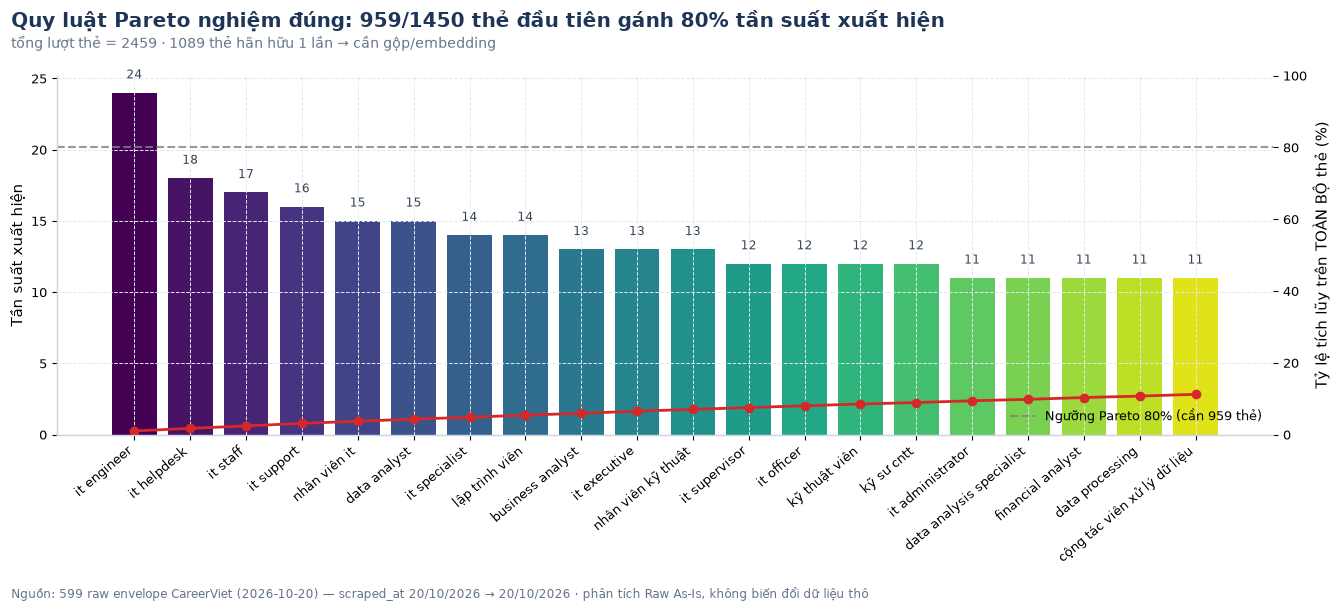

In [21]:
skills = df["job-tags"].map(lambda v: [x.strip() for x in v if isinstance(x, str) and x.strip()] if isinstance(v, list) else [])
sk_all = skills.explode().dropna().str.lower()
vc_sk = sk_all.value_counts()
print(f"── 6.2 Độ thưa thớt của thẻ kỹ năng (job-tags) ──")
print(f"Tổng lượt thẻ: {len(sk_all)} | Thẻ độc nhất: {sk_all.nunique()} | "
      f"Thẻ chỉ xuất hiện 1 lần: {int((vc_sk == 1).sum())} ({(vc_sk == 1).mean()*100:.1f}% số loại)")
n_needed = int((vc_sk.cumsum() / vc_sk.sum() <= .8).sum()) + 1
x = np.sort(vc_sk.values.astype(float))
gini = float((2 * np.sum((np.arange(1, len(x) + 1)) * x)) / (len(x) * x.sum()) - (len(x) + 1) / len(x)) \
    if len(x) > 1 and x.sum() else 0.0
print(f"Hệ số Gini tần suất thẻ: {gini:.3f} (0 = thẻ nào cũng như nhau, →1 = vài thẻ nuốt toàn bộ tần suất)")
top20 = vc_sk.head(20)
pareto = pd.DataFrame({"Skill": top20.index, "Frequency": top20.values})
pareto["Cum_%"] = (pareto["Frequency"].cumsum() / vc_sk.sum() * 100).round(1)

fig, ax1 = plt.subplots(figsize=(13.5, 6))
ax1.bar(range(len(pareto)), pareto["Frequency"], color=[matplotlib.colormaps["viridis"](i / len(pareto)) for i in range(len(pareto))])
ax1.set_xticks(range(len(pareto))), ax1.set_xticklabels(pareto["Skill"], rotation=40, ha="right", fontsize=9.5)
ax1.set_ylabel("Tần suất xuất hiện")
for i, v in enumerate(pareto["Frequency"]):
    ax1.text(i, v + 1, f"{v}", ha="center", fontsize=8.5, color="#334155")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(range(len(pareto)), pareto["Cum_%"], color="#d62828", marker="o", lw=2)
ax2.axhline(80, color="gray", ls="--", alpha=.8, label=f"Ngưỡng Pareto 80% (cần {n_needed} thẻ)")
ax2.set_ylabel("Tỷ lệ tích lũy trên TOÀN BỘ thẻ (%)"), ax2.set_ylim(0, 100), ax2.legend(loc="lower right")
finalize(fig, f"Quy luật Pareto nghiệm đúng: {n_needed}/{len(vc_sk)} thẻ đầu tiên gánh 80% tần suất xuất hiện",
         f"tổng lượt thẻ = {len(sk_all)} · {int((vc_sk == 1).sum())} thẻ hãn hữu 1 lần → cần gộp/embedding",
         "06_skills_pareto_distribution.png")

🖼️  Đã lưu reports\figures\careerviet\07_bias_and_class_balance.png (DPI 300)


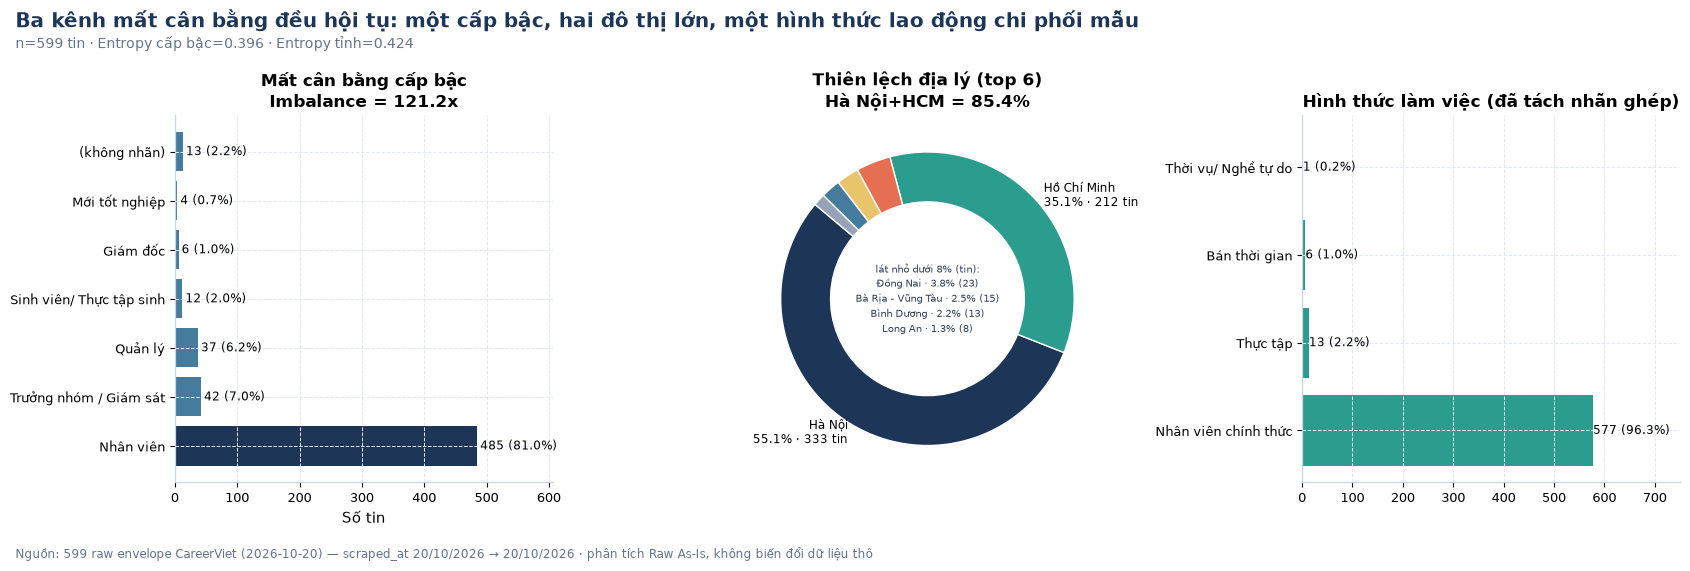

In [22]:
vc_lvl = lvl_raw.value_counts()
vc_prov = vc_map.head(6)
form_clean = _vals(_form_tok)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))

o = [k for k in order if k in vc_lvl.index]
vals = vc_lvl.reindex(o).fillna(0).values
axes[0].barh(range(len(o)), vals, color=[C_MAIN if v == max(vals) else "#457b9d" for v in vals])
axes[0].set_yticks(range(len(o))), axes[0].set_yticklabels(o, fontsize=9)
for i, v in enumerate(vals):
    axes[0].text(v + max(vals) * .01, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[0].set_xlim(0, max(vals) * 1.25), axes[0].set_xlabel("Số tin")
axes[0].set_title(f"Mất cân bằng cấp bậc\nImbalance = {vc_lvl.max()/max(vc_lvl.min(),1):.1f}x")

donut(axes[1], vc_prov.values, vc_prov.index, PALETTE + ["#94a3b8"], unit="tin")
axes[1].set_title(f"Thiên lệch địa lý (top 6)\nHà Nội+HCM = {hn_hcm/vc_map.sum()*100:.1f}%")

axes[2].barh(range(len(form_clean)), form_clean.values, color=PALETTE[1])
axes[2].set_yticks(range(len(form_clean))), axes[2].set_yticklabels(form_clean.index, fontsize=9)
for i, v in enumerate(form_clean.values):
    axes[2].text(v + .5, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[2].set_xlim(0, max(form_clean.values) * 1.3), axes[2].set_title("Hình thức làm việc (đã tách nhãn ghép)")
finalize(fig, "Ba kênh mất cân bằng đều hội tụ: một cấp bậc, hai đô thị lớn, một hình thức lao động chi phối mẫu",
         f"n={len(df)} tin · Entropy cấp bậc={entropy_norm(vc_lvl.values):.3f} · Entropy tỉnh={entropy_norm(vc_map.values):.3f}",
         "07_bias_and_class_balance.png")

── 6.5 Cờ IT vs ngoài IT — so sánh RIÊNG trong từng tiền tệ (không trộn hai thang đo) ──

   ▐ BẢNG A — VND (Triệu VND/tháng)
      Mann–Whitney U (IT n=182 vs ngoài IT n=8): p=0.007 → khác biệt CÓ ý nghĩa thống kê

   ▐ BẢNG B — USD (USD/tháng)
      IT có 5 tin công khai lương, ngoài IT có 1 tin → có nhóm dưới 5 quan sát, KHÔNG kiểm định (kết luận 'IT lương cao hơn' ở bảng này sẽ là suy diễn từ nhiễu).

Tỷ lệ tin mang nhãn 'CNTT - Phần mềm' trong Ngành nghề: 91.0% — CareerViet là sàn ĐA NGÀNH, bộ lọc IT bắt buộc trước khi tích hợp.
🖼️  Đã lưu reports\figures\careerviet\13_it_vs_non_it.png (DPI 300)


,Tin có lương,Lương trung vị,Lương P25,Lương P75,Kinh nghiệm trung vị,Thẻ kỹ năng TB,JD (từ) TB
nhóm,,,,,,,
IT,182,25.0,18.0,31.5,2.0,4.07,273.61
Ngoài IT,8,17.5,15.0,18.5,2.0,4.48,227.84


,Tin có lương,Lương trung vị,Lương P25,Lương P75,Kinh nghiệm trung vị,Thẻ kỹ năng TB,JD (từ) TB
nhóm,,,,,,,
IT,5,2000.0,1500.0,2000.0,2.0,4.07,273.61
Ngoài IT,1,800.0,800.0,800.0,2.0,4.48,227.84


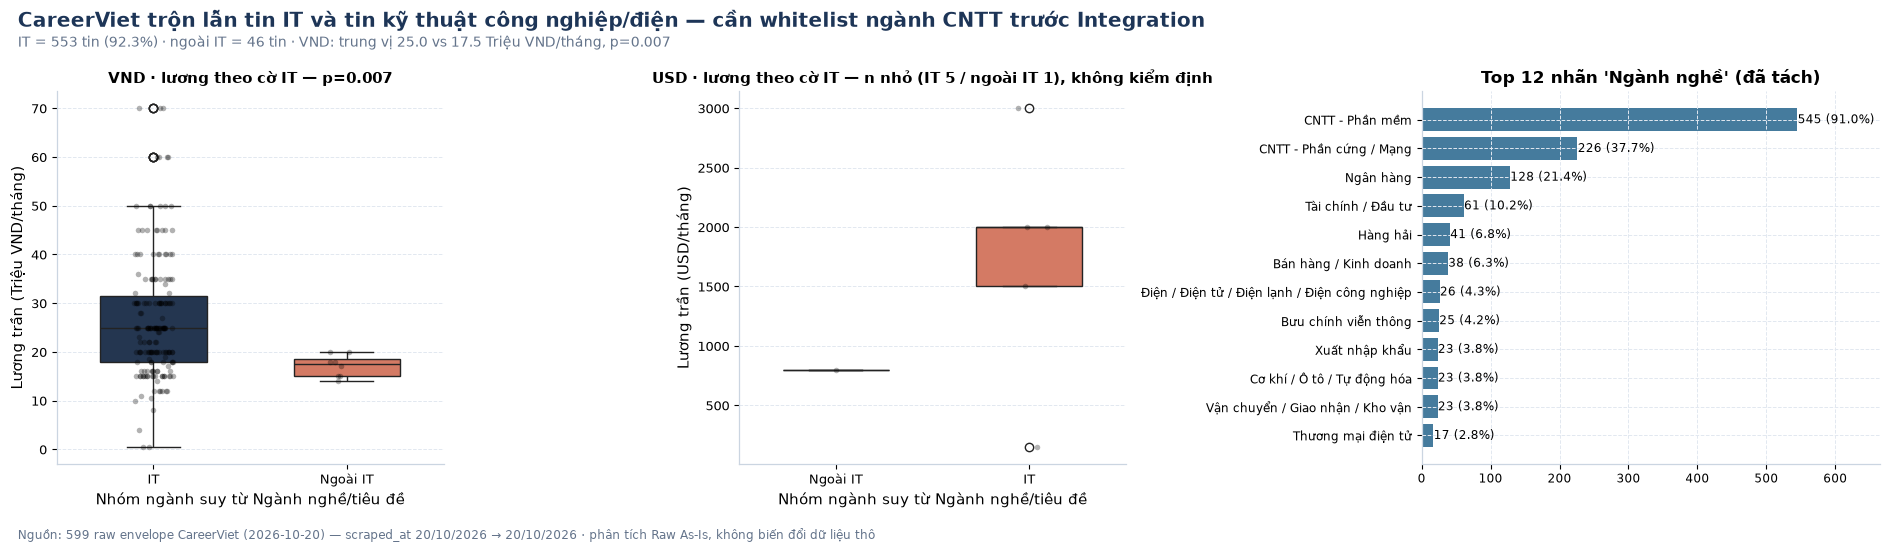

In [23]:
it_flag = pd.Series(np.where(is_it, "IT", "Ngoài IT"), index=df.index)
print("── 6.5 Cờ IT vs ngoài IT — so sánh RIÊNG trong từng tiền tệ (không trộn hai thang đo) ──")
ITN = {}
for tag, cur_label, unit in CUR_GROUPS:
    comp = pd.DataFrame({"nhóm": it_flag, "sal": feat[f"sal_max_{tag}"], "exp": feat["exp_min"],
                         "tags": feat["n_tags"], "jd": feat["jd_desc_words"]})
    tab = comp.groupby("nhóm", observed=True).agg(**{
        "Tin có lương": ("sal", "count"), "Lương trung vị": ("sal", "median"),
        "Lương P25": ("sal", lambda s: s.quantile(.25)), "Lương P75": ("sal", lambda s: s.quantile(.75)),
        "Kinh nghiệm trung vị": ("exp", "median"), "Thẻ kỹ năng TB": ("tags", "mean"),
        "JD (từ) TB": ("jd", "mean")}).round(2)
    print(f"\n   ▐ BẢNG {'A' if tag == 'vnd' else 'B'} — {cur_label} ({unit})")
    show(tab)
    a = comp.loc[comp["nhóm"].eq("IT"), "sal"].dropna()
    b = comp.loc[comp["nhóm"].eq("Ngoài IT"), "sal"].dropna()
    ITN[tag] = {"comp": comp, "a": len(a), "b": len(b), "p": np.nan,
                "med_it": float(a.median()) if len(a) else np.nan,
                "med_out": float(b.median()) if len(b) else np.nan}
    if min(len(a), len(b)) >= 5:
        u_ = stats.mannwhitneyu(a, b)
        ITN[tag]["p"] = float(u_.pvalue)
        print(f"      Mann–Whitney U (IT n={len(a)} vs ngoài IT n={len(b)}): p={u_.pvalue:.3f} → "
              + ("khác biệt CÓ ý nghĩa thống kê" if u_.pvalue < .05 else "CHƯA đủ bằng chứng khác biệt"))
    else:
        print(f"      IT có {len(a)} tin công khai lương, ngoài IT có {len(b)} tin → có nhóm dưới 5 quan sát, "
              f"KHÔNG kiểm định (kết luận 'IT lương cao hơn' ở bảng này sẽ là suy diễn từ nhiễu).")

print(f"\nTỷ lệ tin mang nhãn 'CNTT - Phần mềm' trong Ngành nghề: "
      f"{ind_series.str.contains('CNTT - Phần mềm').mean()*100:.1f}% — CareerViet là sàn ĐA NGÀNH, "
      f"bộ lọc IT bắt buộc trước khi tích hợp.")

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4), gridspec_kw={"width_ratios": [1.35, 1.35, 1.6]})
for ax, (tag, cur_label, unit) in zip(axes[:2], CUR_GROUPS):
    d = ITN[tag]
    boxd = d["comp"].dropna(subset=["sal"])
    if boxd.empty:
        ax.axis("off"), ax.set_title(f"{cur_label}: không có tin nào công khai lương"); continue
    sns.boxplot(data=boxd, x="nhóm", y="sal", hue="nhóm", palette=[PALETTE[0], PALETTE[2]],
                legend=False, ax=ax, width=.55)
    sns.stripplot(data=boxd, x="nhóm", y="sal", color="black", alpha=.3, size=4, ax=ax)
    ax.set_xlabel("Nhóm ngành suy từ Ngành nghề/tiêu đề"), ax.set_ylabel(f"Lương trần ({unit})")
    ax.set_title(f"{cur_label} · lương theo cờ IT — "
                 + (f"p={d['p']:.3f}" if pd.notna(d["p"]) else f"n nhỏ (IT {d['a']} / ngoài IT {d['b']}), không kiểm định"),
                 fontsize=10.5)
vc_it = _vals(_ind_tok).head(12).sort_values()
axes[2].barh(vc_it.index, vc_it.values, color=PALETTE[4])
for i, v in enumerate(vc_it.values):
    axes[2].text(v + .5, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[2].set_xlim(0, vc_it.max() * 1.22), axes[2].set_title("Top 12 nhãn 'Ngành nghề' (đã tách)")
axes[2].tick_params(labelsize=8.5)
_pv = ITN[DOMR]["p"]
_d_it = ITN[DOMR]
finalize(fig, "CareerViet trộn lẫn tin IT và tin kỹ thuật công nghiệp/điện — cần whitelist ngành CNTT trước Integration",
         f"IT = {int((it_flag=='IT').sum())} tin ({(it_flag=='IT').mean()*100:.1f}%) · "
         f"ngoài IT = {int((it_flag=='Ngoài IT').sum())} tin · "
         + (f"{CUR_LABEL[DOMR]}: trung vị {_d_it['med_it']:.1f} vs {_d_it['med_out']:.1f} {CUR_UNIT[DOMR]}, p={_pv:.3f}"
            if pd.notna(_pv) else f"{CUR_LABEL[DOMR]}: không đủ mẫu để kiểm định"),
         "13_it_vs_non_it.png")

🖼️  Đã lưu reports\figures\careerviet\14_company_and_benefits.png (DPI 300)


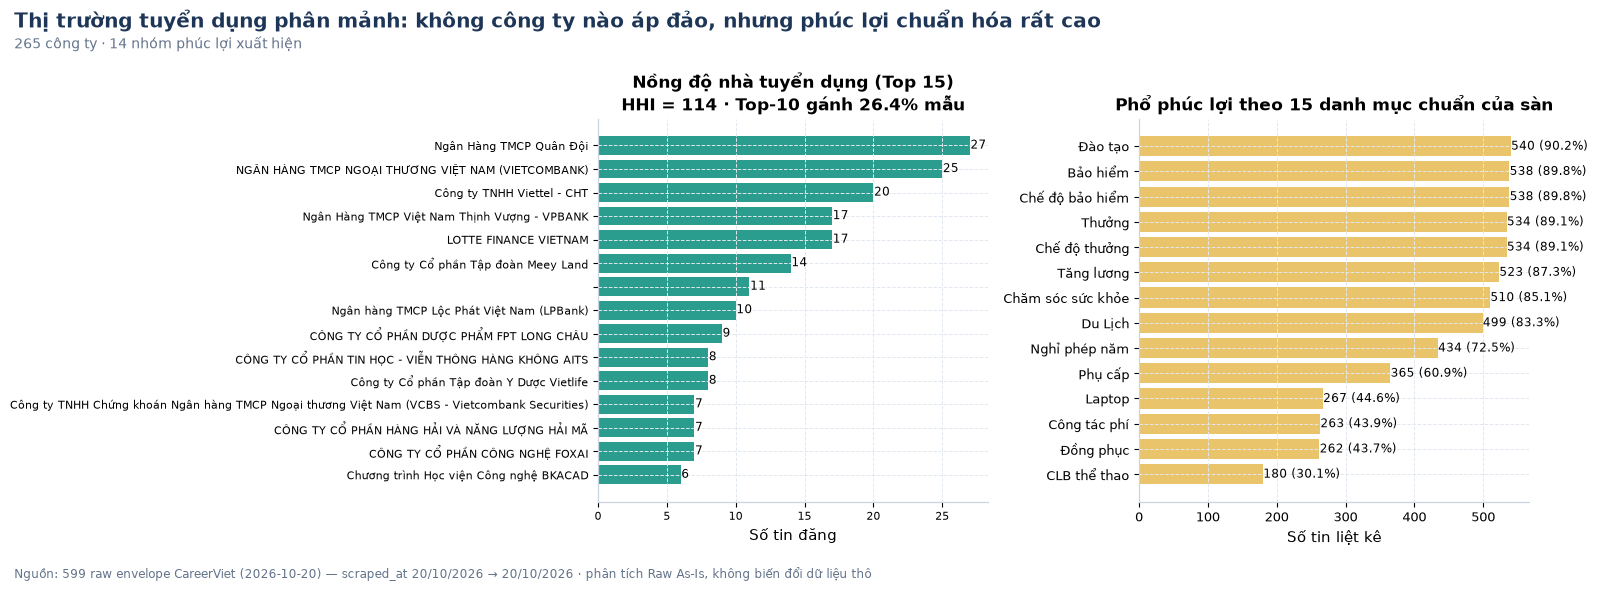

In [24]:
comp_counts = df["job-company-name"].value_counts()
hhi = float(((comp_counts / comp_counts.sum()) ** 2).sum() * 10000)
top10_share = comp_counts.head(10).sum() / comp_counts.sum() * 100
vc_ben = df[text_cols["jd_ben"]].map(lambda s: [b for b in BENEFIT_CATS if isinstance(s, str) and b.lower() in s.lower()]).explode().dropna().value_counts()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
tc = comp_counts.head(15).sort_values()
axes[0].barh(tc.index.astype(str), tc.values, color=PALETTE[1])
for i, v in enumerate(tc.values):
    axes[0].text(v + .05, i, f"{int(v)}", va="center", fontsize=8.5)
axes[0].set_xlabel("Số tin đăng"), axes[0].tick_params(labelsize=8)
axes[0].set_title(f"Nồng độ nhà tuyển dụng (Top 15)\nHHI = {hhi:.0f} · Top-10 gánh {top10_share:.1f}% mẫu")
vb = vc_ben.sort_values()
axes[1].barh(vb.index, vb.values, color=PALETTE[3])
for i, v in enumerate(vb.values):
    axes[1].text(v + .5, i, f"{int(v)} ({v/len(df)*100:.1f}%)", va="center", fontsize=8.5)
axes[1].set_xlabel("Số tin liệt kê"), axes[1].set_title("Phổ phúc lợi theo 15 danh mục chuẩn của sàn")
finalize(fig, "Thị trường tuyển dụng phân mảnh: không công ty nào áp đảo, nhưng phúc lợi chuẩn hóa rất cao",
         f"{df['job-company-name'].nunique()} công ty · {len(vc_ben)} nhóm phúc lợi xuất hiện",
         "14_company_and_benefits.png")

### Đọc đồ thị 06–07 và các biểu đồ bổ trợ — độ thưa thớt & ba kênh mất cân bằng

**Đồ thị 06 (Pareto thẻ kỹ năng).** CareerViet không cho một danh sách kỹ năng có cấu trúc mà cho `job-tags` —
kết quả là **2.459 lượt thẻ nhưng tới 1.450 nhãn độc nhất**, trong đó **1.089 thẻ (75.1% số loại) chỉ xuất hiện đúng
1 lần**. Gini tần suất thẻ chỉ **0.356** — tức phần đuôi không hề “dẹt” như Pareto 80/20 cổ điển: phải cần tới **959/1.450
nhãn** mới gom đủ 80% tổng lượt. Hệ quả thực tế: **không được one-hot-encode** kho thẻ này (sẽ nổ dimension với toàn
cột gần bằng 0); phải dùng embedding/TF-IDF, và nếu lọc thì chỉ lọc xuất hiện-1-lần *khi vẽ*, còn khi lập mô hình vẫn giữ đủ.

**Đồ thị 07 (mất cân bằng).** Ba kênh hội tụ về cùng một bức tranh, nhưng mức độ khác nhau nhiều:

| Kênh | Nhãn leading | Entropy chuẩn hoá | Imbalance Ratio | Đọc là gì |
|:---|:---|:---|:---|:---|
| Cấp bậc | Nhân viên 81.0% | 0.396 | 121.2x | Mẫu nghiêng gần hẳn về nhân viên; Quản lý 37 · Giám đốc 6 tin |
| Hình thức | Nhân viên chính thức 94.8% | **0.144** | **568x** | Kênh mất cân bằng nghiêm trọng nhất; sau tách nhãn ghép còn 4 nhãn, leading 96.6% |
| Tỉnh/TP | Hà Nội 52.2% | 0.424 | 333x | Hà Nội + HCM = **85.4%** (545/638 lượt), 10 tỉnh chỉ xuất hiện 1 lần |
| Ngành nghề | CNTT - Phần mềm 38.6% | **0.626** | 545x | Kênh *đa dạng nhất* (53 nhãn, 2.41 lượt/tin) — đúng bản chất sàn đa ngành |

Hai điểm cần nói thẳng để tránh diễn giải sai: (i) **`Giới tính` chỉ xuất hiện trên 49/599 tin (8.2%) và 93.9% trong số đó
là “Nam”** — con số này đo *cách nhà tuyển dụng khai báo*, không phải *cơ giới ứng viên*, nên không được dùng làm bằng
chứng thiên lệch tuyển dụng; (ii) `Bằng cấp` phủ 87.8% với “Đại học” chiếm 78.3%, nghĩa là chỉ tiêu này gần như hằng số
⇒ sức phân biệt thấp khi đưa vào mô hình.

**Biểu đồ bổ trợ.** `n_box_items` có skew **−6.23** với trần cứng ở 10 phần tử (đồ thị 09): `detail-box` là khuôn mẫu
DOM cố định, không phải biến nghiệp vụ — vì vậy nó tốt để *giám sát crawler* (tin có 0 mục = 13 tin detail-box rỗng)
hơn là làm feature. `label_echo` xuất hiện ở **598/599 tin** văn bản (đồ thị 12b): mỗi khối mô tả mở đầu bằng chính
nhãn của nó (“Mô tả Công việc …”), nên phải cắt prefix trước khi trích xuất kỹ năng, nếu không bộ đếm từ sẽ tính thừa.
Đồ thị 13 bây giờ so sánh **từng tiền tệ một**. Bảng A (VND): nhóm IT có lương trung vị **25.0** so với **17.5** của nhóm
ngoài IT, Mann–Whitney **p = 0.007** (trên 182 tin IT và 8 tin ngoài IT có lương công khai) ⇒ khác biệt không phải do
ngẫu nhiên, và đó chính là lý do phải lọc IT *trước* khi tích hợp đa nguồn. Bảng B (USD) chỉ còn **5 tin IT và 1 tin
ngoài IT** có lương ⇒ notebook **từ chối kiểm định** thay vì báo một p-value vô nghĩa.

## Bước 7 — Bệnh án dữ liệu CareerViet & khuyến nghị tiền xử lý (tự động từ số liệu vừa đo)

In [25]:
N_QUANT = int(feat_sal["currency"].notna().sum())
N_CEIL = int(feat_sal["sal_max"].notna().sum())
N_FLOOR_ONLY = int((feat_sal["currency"].notna() & feat_sal["sal_max"].isna()).sum())
_d_cur, _d_dist = [], []
for tag, cur_label, unit in CUR_GROUPS:
    s_ = SAL_BY_CUR[tag]["tbl"]["max"].dropna()
    _nb = SAL_BY_CUR[tag].get("n_bad", 0)
    _d_cur.append(f"{cur_label}: {len(s_)} tin có lương trần"
                  + (f", trung vị {s_.median():.1f} {unit}" if len(s_) else "")
                  + f", guard {SAL_SANITY[tag][0]:g}–{SAL_SANITY[tag][1]:g} "
                  + ("PASS" if _nb == 0 else f"FAIL ({_nb} tin)"))
    _d_dist.append(f"{cur_label}: " + (f"skew={s_.skew():+.2f}, kurt={s_.kurtosis():+.2f}, "
                                       f"ngoại lai Tukey {SAL_BY_CUR[tag].get('n_out', 0)}/{len(s_)} "
                                       f"({SAL_BY_CUR[tag].get('n_out', 0)/len(s_)*100:.1f}%)"
                  if len(s_) else "0 tin, không đo phân phối"))
_d_ladder = (f"{best} là nghiệm đối xứng tốt nhất cho {CUR_LABEL[DOM_TAG]} (skew {skews[best]:+.2f}) "
             f"trong khi log1p ép quá tay ({sk_log:+.2f})"
             if DOM_TAG else f"không tiền tệ nào đạt n ≥ {MIN_N_DIST} để dựng thang kiểm biến đổi")
_d_kw = (f"cấp bậc phân tầng lương rõ (Kruskal–Wallis p={kw_sen.pvalue:.3f} trên {CUR_LABEL[DOM]})"
         if pd.notna(kw_sen.pvalue) else "Kruskal–Wallis không tính được (mẫu cấp bậc quá mỏng)")
print("── 7. Bệnh án dữ liệu thô (mọi con số dưới đây đều do notebook vừa đo) ──")
diagnosis = {
    "0. Quy mô Raw": f"{len(df)} envelope / {df['_partition'].nunique()} phân vùng dt · {len(raw_cols)} cột thô + {df_meta.shape[1]} cột metadata",
    "1. Độ hoàn thiện": f"{int(nan_table['Số dòng NaN (isnull())'].gt(0).sum())} cột có NaN tường minh; "
                        f"{len(hn)} cột có null trá hình; nặng nhất: {hn.iloc[0]['Cột']} ({hn.iloc[0]['Tỷ lệ (%)']}%)",
    "2. Tính hợp lệ": f"{N_QUANT}/{len(df)} tin bóc được ít nhất một mốc lương số ({N_QUANT/len(df)*100:.1f}%), "
                      f"trong đó {N_CEIL} tin có trần lương và {N_FLOOR_ONLY} tin chỉ ghi sàn kiểu 'trên N'; "
                      f"{int(kc.get('Ẩn số / thương lượng', 0))} tin 'Cạnh tranh/Thỏa thuận'; "
                      f"{int((dup_items>0).sum())} tin có chuỗi trùng lặp trong detail-box; "
                      f"{int(feat['n_box_items'].eq(0).sum())} tin detail-box rỗng",
    "2b. HAI BẢNG TIỀN TỆ": " | ".join(_d_cur) + " — hai bảng ĐỌC RIÊNG, notebook không quy đổi chéo",
    "3. Tính duy nhất": f"{int(logical[logical>1].sum())} tin thuộc cụm trùng logic công ty+tiêu đề; "
                        f"canonical_hash trùng: {int(df_meta['m_canonical_hash'].duplicated().sum())}; "
                        f"job_id trùng: {int(df_meta['m_job_id'].duplicated().sum())}",
    "4. Phân phối": " | ".join(_d_dist) + f"; kinh nghiệm skew={feat['exp_min'].skew():.2f}; "
                    f"{_d_ladder}; {_d_kw}",
    "5. Mất cân bằng": f"Cấp bậc Entropy={entropy_norm(vc_lvl.values):.3f}, Imbalance={vc_lvl.max()/max(vc_lvl.min(),1):.1f}x; "
                       f"Hà Nội+HCM={hn_hcm/vc_map.sum()*100:.1f}%; thẻ kỹ năng {n_needed}/{len(vc_sk)} gánh 80% tần suất",
    "6. Rủi ro cho Integration": f"Sàn đa ngành: chỉ {(it_flag=='IT').mean()*100:.1f}% tin có dấu hiệu IT → bắt buộc whitelist 'CNTT - Phần mềm'; "
                                f"địa điểm chi tiết thiếu {int(df['detail-row.Địa điểm làm việc'].isna().sum())} tin",
}
print("=" * 78); print(f"🩺 BỆNH ÁN DỮ LIỆU THÔ — {SOURCE_LABEL.upper()}"); print("=" * 78)
for k, v in diagnosis.items():
    print(f"  {k}\n      → {v}")

print("\n" + "=" * 78)
print("📁 KIỂM TRA ĐẦU RA (Definition of Done)")
print("=" * 78)
REQUIRED = ["01_data_completeness_missingno.png", "02_salary_distribution_skewness.png",
            "03_salary_outliers_seniority.png", "04_experience_vs_salary_relation.png",
            "05_spearman_correlation_matrix.png", "06_skills_pareto_distribution.png",
            "07_bias_and_class_balance.png"]
for f in REQUIRED:
    p = FIG_DIR / f
    print(f"  {'✅' if p.exists() else '❌'} {f}  {'(' + str(round(p.stat().st_size/1024)) + ' KB)' if p.exists() else ''}")
aux = [n for n in SAVED_FIGS if n not in REQUIRED]
print(f"  🎁 Biểu đồ bổ trợ do notebook này tạo: {len(aux)} file → {sorted(aux)}")
stray = sorted(p.name for p in FIG_DIR.glob("*.png") if p.name not in SAVED_FIGS)
if stray:
    print(f"  ⚠️  {len(stray)} PNG khác trong thư mục nhưng KHÔNG do notebook này ghi ra "
          f"(sản phẩm của notebook EDA cũ hoặc nguồn khác, để nguyên không xoá): {stray}")

print("\n" + "=" * 78)
print("🔒 KIỂM CHỨNG 'EDA KHÔNG TIỀN XỬ LÝ' — tầng Raw As-Is phải bất biến")
print("=" * 78)
RAW_DISK_1 = _raw_fingerprint(DATA_DIR)
RAW_FRAME_1 = _frame_fingerprint(df)
_checks = [
    ("File thô trên đĩa không đổi (số lượng)", RAW_DISK_0["n"] == RAW_DISK_1["n"],
     f"{RAW_DISK_0['n']} → {RAW_DISK_1['n']}"),
    ("File thô trên đĩa không đổi (tổng byte)", RAW_DISK_0["bytes"] == RAW_DISK_1["bytes"],
     f"{RAW_DISK_0['bytes']:,} → {RAW_DISK_1['bytes']:,}"),
    ("File thô không bị sửa (hash tên+size+mtime)", RAW_DISK_0["sha"] == RAW_DISK_1["sha"],
     f"{RAW_DISK_0['sha']} → {RAW_DISK_1['sha']}"),
    ("Khung `df` trong bộ nhớ giữ nguyên {0}×{1}".format(*RAW_SHAPE_0), df.shape == RAW_SHAPE_0,
     f"{RAW_SHAPE_0} → {df.shape}"),
    ("Bộ cột thô của `df` không bị thêm/bớt", list(df.columns) == RAW_COLUMNS_0,
     f"{len(RAW_COLUMNS_0)} cột → {len(df.columns)} cột"),
    ("Nội dung từng ô của `df` không bị biến đổi", RAW_FRAME_0 == RAW_FRAME_1,
     f"{RAW_FRAME_0} → {RAW_FRAME_1}"),
]
_all_pass = True
for name, ok, detail in _checks:
    _all_pass &= bool(ok)
    print(f"  {'✅' if ok else '❌'} {name:<52} {detail}")
print(f"\n  ➤ Kết luận: {'PASS — EDA chỉ ĐỌC và ĐO, không một phép tiền xử lý nào được áp lên dữ liệu thô.' if _all_pass else 'FAIL — có thao tác đã đụng tới tầng Raw, PHẢI dừng và sửa notebook.'}")
print("  ➤ Phạm vi tiền xử lý thuộc về tầng Integration (sau khi ghép đủ 8 nguồn):")
print("      • Imputation (điền khuyết thiếu), Normalization/Scaling (chuẩn hoá), Encoding (mã hoá nhãn),")
print("      • Khử trùng lặp xuyên sàn, quy đổi tỷ giá về một đồng tiền chung, gộp schema 8 nguồn.")
print("      Notebook này chỉ trả về KẾ HOẠCH tiền xử lý (mục 7.1) — không tạo ra biến đổi nào.")

── 7. Bệnh án dữ liệu thô (mọi con số dưới đây đều do notebook vừa đo) ──
🩺 BỆNH ÁN DỮ LIỆU THÔ — CAREERVIET
  0. Quy mô Raw
      → 599 envelope / 1 phân vùng dt · 14 cột thô + 16 cột metadata
  1. Độ hoàn thiện
      → 10 cột có NaN tường minh; 14 cột có null trá hình; nặng nhất: detail-row.Video Tuyển Dụng (99.67%)
  2. Tính hợp lệ
      → 200/599 tin bóc được ít nhất một mốc lương số (33.4%), trong đó 196 tin có trần lương và 4 tin chỉ ghi sàn kiểu 'trên N'; 386 tin 'Cạnh tranh/Thỏa thuận'; 586 tin có chuỗi trùng lặp trong detail-box; 13 tin detail-box rỗng
  2b. HAI BẢNG TIỀN TỆ
      → VND: 190 tin có lương trần, trung vị 25.0 Triệu VND/tháng, guard 0.5–1000 PASS | USD: 6 tin có lương trần, trung vị 1750.0 USD/tháng, guard 50–20000 PASS — hai bảng ĐỌC RIÊNG, notebook không quy đổi chéo
  3. Tính duy nhất
      → 30 tin thuộc cụm trùng logic công ty+tiêu đề; canonical_hash trùng: 1; job_id trùng: 0
  4. Phân phối
      → VND: skew=+1.19, kurt=+1.77, ngoại lai Tukey 13/190 (6.8%) |

### 🔎 Kiểm bao phủ trực quan hóa — trả lời bằng máy, không trả lời bằng cảm tính

Câu hỏi “**đã vẽ hết trường trong dữ liệu thô chưa?**” được cell ngay dưới đây trả lời **tự động ở mỗi lần chạy**, theo ba ràng buộc:

1. **Vũ trụ trường** được đọc từ chính khung dữ liệu đã nạp (`df`, `df_top` nếu có, `df_meta`), chỉ loại các cột provenance nội bộ bắt đầu bằng `_`. Con số này do dữ liệu sinh ra chứ không do người viết gõ vào, nên một đợt cào thêm trường mới sẽ tự động làm vũ trụ phình ra và cell kiểm sẽ đòi hỏi trường đó.
2. **Bằng chứng “đã lên hình”** là toàn bộ chữ in trên PNG *thật* tại thời điểm lưu (`_harvest_labels` thu nhãn tick, tên trục, tiêu đề, legend, ghi chú) — không phải một danh sách khai báo tay.
3. Trường nào không lên hình vẫn được tính là **có bao phủ** nếu nó đã biến thành feature trên hình; nhưng mỗi khai báo kiểu đó bị *chứng minh* bằng cách đi tìm đúng chuỗi nhãn đó trong đúng biểu đồ được nêu, khai sai sẽ tự rớt xuống nhóm sau.

Bốn mức được in ra: tên trường xuất hiện trực tiếp trên hình · lên hình gián tiếp qua feature · chỉ kiểm kê bằng **bảng/số liệu** (kèm lý do nghiệp vụ ghi rõ cho từng trường) · và **❗ chưa giải trình**. Điều kiện nghiệm thu: **cột `❗` bắt buộc bằng 0** — nếu đợt cào mới sinh ra trường chưa được nhìn thấy, phải hoặc vẽ thêm, hoặc khai lý do vào `REASON`.

Cell này cũng in luôn **kiểm tra bố cục chữ**: hộp bao pixel của *từng* dòng chữ trên hình được đo ngay lúc lưu, nên “chữ đè chữ” và “chữ bị cắt ở biên” trở thành hai con số có nghiệm thu (**0**) thay vì một nhận xét bằng mắt. Đây là cách trả lời phản hồi “biểu đồ bị đè chữ”: ràng buộc tồn tại trong code và tự tái kiểm tra ở mỗi đợt cào mới, khi nhãn dài ra hoặc số nhóm tăng lên.

In [26]:
print("\n" + "=" * 78)
print("🔎 KIỂM BAO PHỦ TRỰC QUAN HÓA — từng trường thô có lên ít nhất một biểu đồ không?")
print("=" * 78)

FRAME_COLS = [c for c in df.columns if not c.startswith("_")]
TOP_COLS = list(df_top.columns) if "df_top" in globals() else []
META_COLS = list(df_meta.columns)
UNIVERSE = list(dict.fromkeys(FRAME_COLS + TOP_COLS + META_COLS))
ALL_LABS = {p: {s.lower() for s in labs} for p, labs in FIG_LABELS.items()}


def _toks(col):
    """Mọi cách một biểu đồ có thể ghi tên trường: nguyên văn, lá, và dạng viết tắt gọn của khối lồng.

    Cột quản trị `m_*` chỉ được tính khi NGUYÊN TÊN xuất hiện trên hình. Nếu cho cắt lấy lá thì
    `m_field_hashes.title` sẽ khớp với nhãn `title` của trường gốc và báo khống mức bao phủ.
    """
    out = {col}
    if not col.startswith("m_"):
        out.add(col.split(".")[-1])
        for a, b in (("job_posting_jsonld.", "jsonld."), ("company_details.", "cd.")):
            out.add(col.replace(a, b))
    return {t.strip().lower() for t in out if t.strip()}


# Ánh xạ cho những trường lên hình GIÁN TIẾP (đã biến thành feature nên tên trường không còn trên nhãn).
# Mỗi khai báo bị CHUNG MINH bằng cách đi tìm đúng chuỗi đó trong nhãn thật của đúng biểu đồ được nêu;
# khai báo sai sẽ bị loại khỏi sổ bao phủ chứ không được âm thầm tính là 'đã có hình'.
INDIRECT = {
    "detail-row.Mô tả Công việc": ("số từ của 'mô tả công việc'", "12"),
    "detail-row.Yêu Cầu Công Việc": ("số từ của 'yêu cầu công việc'", "12"),
    "detail-row.Phúc lợi": ("phổ phúc lợi", "14"),
    "m_scraped_at": ("giờ thu thập", "08"),
}

# Lý do tường minh cho từng trường KHÔNG lên hình. Trường nào rớt lại mà chưa khai lý do sẽ bị báo
# ❗ — nhờ đó câu trả lời 'đã phủ hết chưa' không thể tự nói dối khi dữ liệu cào thêm đợt mới.
REASON = [
    ("m_field_hashes.", "bảng 1.2 liệt kê đủ; mỗi ô là SHA-256 của một khối DOM, một giá trị duy nhất/tin → không tồn tại phân phối để vẽ"),
    ("m_source_category", "một giá trị hằng theo phân vùng → đã đếm ở bảng 1.2"),
    ("m_source_url", "đường dẫn dài, một giá trị/tin; ảnh hưởng của độ dài chuỗi đã đo bóng qua `_bytes` ở đồ thị 08"),
    ("m_source", "một giá trị hằng cho cả nguồn → biểu đồ sẽ chỉ có một đòn"),
    ("m_scraper_version", "hằng số theo thế hệ crawler → bảng 1.2"),
    ("m_version", "nhị phân 1 vs >1 → đã in số ở mục 1.2 và dùng ở mục 4.1"),
    ("m_content_hash", "duy nhất theo tin; độ trùng được đo bằng BẢNG ở mục 4.1"),
    ("m_canonical_hash", "duy nhất theo tin; số ô trống đã in ở mục 1.2"),
    ("m_job_id", "khóa duy nhất theo tin, được dùng làm bằng chứng khử trùng lặp ở mục 4.1 (BẢNG, không phải trục số)"),
    ("detail-row.Gợi ý hồ sơ", "khối văn bản sàn sinh cho ứng viên, không phải thuộc tính tin đăng → chỉ liệt kê ở bảng 3.4"),
    ("detail-row.JOB TAGS / SKILLS:", "trùng nội dung `job-tags` (đã có Pareto ở đồ thị 06); nhãn mang dấu ':' → bảng 3.4"),
    ("detail-row.Video Tuyển Dụng", "URL video, độ phủ gần 0 → bảng 3.4"),
    ("detail-row.Địa điểm làm việc", "chuỗi địa chỉ tự do, khuyết theo mẫu MNAR → cờ `is_missing` ở mục 2.2 & bảng 3.4"),
]


def _reason(col):
    for needle, txt in REASON:
        if col.startswith(needle) or needle in col:
            return txt
    return None


direct, indirect_ok, table_only, unexplained = [], [], [], []
for col in UNIVERSE:
    exact, sub = _toks(col), {t for t in _toks(col) if len(t) >= 7}
    hit = sorted(p for p, labs in ALL_LABS.items()
                 if exact & labs or any(t in l for t in sub for l in labs))
    if hit:
        direct.append((col, hit))
        continue
    claim = INDIRECT.get(col)
    if claim:
        needle, prefix = claim
        okp = [p for p in ALL_LABS if p.startswith(prefix) and any(needle in l for l in ALL_LABS[p])]
        if okp:
            indirect_ok.append((col, okp))
            continue
    table_only.append(col)
    if not _reason(col):
        unexplained.append(col)

n_cov = len(direct) + len(indirect_ok)
n_prov = len(df.columns) - len(FRAME_COLS)
n_parent = len(UNIVERSE) - len(FRAME_COLS) - len(META_COLS)
print(f"  Vũ trụ trường do chính khung nạp sinh ra: {len(UNIVERSE)} "
      f"= {len(FRAME_COLS)} cột `df`"
      + (f" + {n_parent} cột cha chỉ nằm trong `df_top`" if n_parent else "")
      + f" + {len(META_COLS)} cột `df_meta`  (đã loại {n_prov} cột provenance nội bộ bắt đầu bằng `_`)")
print(f"  {len(ALL_LABS)} biểu đồ đã lưu trong phiên này, tổng số nhãn thu được: "
      f"{sum(len(v) for v in ALL_LABS.values())}")
print(f"  ✅ Có tên trường trên nhãn trục/tiêu đề của ≥1 biểu đồ ............ {len(direct)}/{len(UNIVERSE)}")
print(f"  ✅ Lên hình GIÁN TIẾP qua feature (khai báo đã được kiểm chứng) ..... {len(indirect_ok)}/{len(UNIVERSE)}")
print(f"  📋 Chỉ được kiểm kê bằng BẢNG/SỐ LIỆU, có lý do ghi rõ ............. {len(table_only)}/{len(UNIVERSE)}")
print(f"  ❗ Chưa có hình VÀ chưa có lý do (phải sửa notebook nếu > 0) ........ {len(unexplained)}/{len(UNIVERSE)}")
print("\n  ── CHI TIẾT NHÓM CHƯA LÊN HÌNH ──")
for col in table_only:
    print(f"    • {col:<44} {_reason(col) or '❗ CHƯA GIẢI TRÌNH'}")
print(f"\n  ➤ Kết luận: {n_cov}/{len(UNIVERSE)} trường ({n_cov / max(len(UNIVERSE), 1) * 100:.1f}%) có bằng chứng "
      f"trực quan hóa lấy từ nhãn của chính PNG đã lưu; {len(table_only)} trường còn lại là tầng quản trị "
      f"(hash/CDC) và khối văn bản một giá trị, được nghiệm thu bằng bảng kiểm kê mục 1.1–1.2 & 3.4.")
print("  ➤ Đây là KẾT LUẬN CÓ RÀNG BUỘC: mọi khai báo ở trên đều suy từ đối tượng hình thật, không nhập tay.")

n_typo = sum(n for _, n in TEXT_CHECKS)
print("\n  ── KIỂM BỐ CỤC CHỮ (đo bằng hộp bao pixel của chính hình, không đo bằng mắt) ──")
print(f"  {'✅' if (n_typo == 0 and len(TEXT_CHECKS) == len(SAVED_FIGS)) else '❗'} "
      f"{len(TEXT_CHECKS)}/{len(SAVED_FIGS)} biểu đồ đã được đo · {n_typo} vị trí chữ đè nhau hoặc bị cắt ở biên "
      f"(nghiệm thu: phải đo đủ {len(SAVED_FIGS)} hình và 0 lỗi)")
for _png, _n in TEXT_CHECKS:
    if _n:
        print(f"     • {_png}: {_n} vấn đề — chi tiết từng cặp chữ đã in ngay lúc vẽ hình này")


🔎 KIỂM BAO PHỦ TRỰC QUAN HÓA — từng trường thô có lên ít nhất một biểu đồ không?
  Vũ trụ trường do chính khung nạp sinh ra: 30 = 14 cột `df` + 16 cột `df_meta`  (đã loại 6 cột provenance nội bộ bắt đầu bằng `_`)
  14 biểu đồ đã lưu trong phiên này, tổng số nhãn thu được: 701
  ✅ Có tên trường trên nhãn trục/tiêu đề của ≥1 biểu đồ ............ 14/30
  ✅ Lên hình GIÁN TIẾP qua feature (khai báo đã được kiểm chứng) ..... 1/30
  📋 Chỉ được kiểm kê bằng BẢNG/SỐ LIỆU, có lý do ghi rõ ............. 15/30
  ❗ Chưa có hình VÀ chưa có lý do (phải sửa notebook nếu > 0) ........ 0/30

  ── CHI TIẾT NHÓM CHƯA LÊN HÌNH ──
    • m_job_id                                     khóa duy nhất theo tin, được dùng làm bằng chứng khử trùng lặp ở mục 4.1 (BẢNG, không phải trục số)
    • m_source                                     một giá trị hằng cho cả nguồn → biểu đồ sẽ chỉ có một đòn
    • m_source_url                                 đường dẫn dài, một giá trị/tin; ảnh hưởng của độ dài chuỗi đã đo bóng q

### 7.1 Khuyến nghị tiền xử lý (dẫn chiếu thẳng tới số liệu đã đo ở trên)

| Vấn đề quan sát | Bằng chứng số | Kỹ thuật đề xuất | Lý do không chọn cách khác |
|:---|:---|:---|:---|
| Lương ẩn dạng chuỗi marketing | Nhóm `Ẩn số / thương lượng` ở Bước 3.2 | Cờ `is_salary_negotiable = 1`, **không** fill trung bình | Tin "Cạnh tranh" có phân phối khác hẳn tin công khai → mean-imputation gây bias |
| Lương lệch phải, đuôi dài | skew **+1.19** / kurt **+1.77** trên lương trần Bảng A (mục 5.1a) | **Box–Cox λ = 0.50** (nghiệm tốt nhất ở thang kiểm đồ thị 02, skew +0.17) + Winsorize P1–P99 cho các biến đếm đuôi dài (bảng 5.3) | `log1p` **bị bác bỏ bằng số liệu**: ép skew từ +1.19 xuống **−1.60** (đảo sang lệch trái, kurtosis phồng lên +8.38). Drop dòng thì mất luôn tag kỹ năng và phúc lợi của tin |
| Đỉnh nhọn 15.3% tại 25.0 Triệu | Q–Q và kiểm định D'Agostino (đồ thị 02, p = 7.26e-10 → 1.04e-02 sau Box–Cox) | Giữ nguyên giá trị rời rạc, thêm biến cờ `is_at_market_median`; không làm mượt bằng KDE khi báo cáo | Nhầm đỉnh mẫu số học (25/30Tr) cho “mức lương thị trường” là lỗi suy diễn phổ biến nhất |
| **Lương hai tiền tệ (VND + USD)** | Mục 3.2b: **Bảng A 190 tin** (trung vị 25.0 Triệu, guard PASS) và **Bảng B 6 tin** (trung vị 1.750 USD, guard PASS) | Ở EDA: **giữ nguyên hai bảng**, xuất kèm cột `currency` và chuỗi gốc. Việc quy đổi thuộc tầng Integration, có khai báo tỷ giá + ngày chốt | Quy đổi ngầm trong notebook EDA sẽ xoá dấu vết đơn vị; chính lỗi bậc độ lớn của hằng số đã làm skew lệch từ +1.22 thành +7.24 mà không biểu đồ nào báo |
| Nhãn DOM trùng lặp trong `detail-box` | Bước 3.1 | Khử duplicate-before-parse, giữ thứ tự xuất hiện đầu tiên | Nếu không, trường "Lương"/"Ngành nghề" dễ lấy nhầm bản sao |
| Chuỗi `Lương Lương:` | Bước 3.1 | Cắt lặp nhãn theo `startswith(label)` hai lần | Regex số không bắt được lỗi nhãn |
| Ngày dd/MM/yyyy & tương đối | Bước 3.3 | Parse về `datetime` + tuổi tin; gắn `is_expired` | `pd.to_datetime` mặc định (mm/dd) sẽ sai 100% bản ghi |
| Trường đóng gói `Thông tin khác` | Bước 3.4 | Tách theo whitelist key, phần dư giữ nguyên vào `raw_extra` | Split theo `:` mù sẽ cắt nhầm cụm "Cao đẳng" |
| Nhãn ghép ` , ` (Hình thức, Ngành nghề, map) | Bước 3.5 | explode thành bảng Many-to-1 khi Integration | Giữ chuỗi ghép làm loãng frequency |
| Mất cân bằng cấp bậc/hình thức | Bước 6.1 | Gộp nhãn <2% vào `Other` + `class_weight='balanced'` | SMOTE không phù hợp dữ liệu phân loại văn bản |
| Thẻ kỹ năng thưa thớt | Bước 6.2 | Giữ full taxonomy + TF-IDF/embedding; chỉ lọc xuất hiện 1 lần khi vẽ | Gộp sớm sẽ mất tín hiệu kỹ năng ngách |
| Sàn đa ngành, tin ngoài IT lẫn trong mẫu | Bước 6.5 | Whitelist `Ngành nghề` chứa "CNTT", kết hợp kiểm tra tiêu đề | Lọc theo từ khóa đơn thuần bỏ sót kỹ sư điện — tự động hóa (c37) |

### 7.2 Bàn giao cho Nhóm Insight (nguồn này **thiếu gì**?)
1. **Không có ngày đăng tuyệt đối** — chỉ có `Ngày cập nhật`/`Hết hạn nộp` (dd/MM/yyyy) ⇒ không đo được *velocity* đăng tin mới.
2. **Không có trường quy mô công ty / năm hoạt động / ngành cấp 2** ⇒ không phân tích được vi mô theo doanh nghiệp.
3. **Lương công khai chỉ ~33%** (phần còn lại "Cạnh tranh") ⇒ mọi kết luận mức lương phải kèm khoảng tin cậy và ghi rõ mẫu tự chọn.
4. **Địa điểm chi tiết khuyết** ⇒ chỉ chuẩn hóa được đến cấp tỉnh, không làm được analysis cấp quận/huyện.
5. **Không có flag remote/hybrid tường minh** ⇒ biến work-mode phải suy từ `Hình thức`, độ tin cậy thấp.

> **Kết luận vai trò EDA nguồn:** dữ liệu thô CareerViet **đủ độ hoàn thiện cấu trúc** để tích hợp, nhưng **ba điểm gãy** (lương ẩn kiểu MNAR, `detail-box` lặp nhãn, tính đa ngành) phải được xử lý bằng luật tường minh ở bước Data Integration — không được âm thầm chuẩn hóa ở tầng Raw.